# Trabajo Práctico Integrador: Comprensión Visual de Escenas
**Cátedra de Inteligencia Artificial – UTN (Primavera 2026)**

* **Curso:** 5k2
* **Grupo:** 21
* **Integrantes:**
  * Ocampo, Gabriel - 93368
  * Pecchio, Valentina - 94416
  * Lopez Quinteros, Manuel - 99026
  * Chaile, Emmanuel Ricardo - 89767
  * Perez, Alvaro - 97986

## 0. Introducción y Objetivos

El presente trabajo práctico consiste en desarrollar un sistema de comprensión visual de escenas capaz de transformar una imagen en una representación estructurada, describirla y responder preguntas sobre su contenido. La arquitectura conceptual progresa a través de cinco etapas clave: Percepción, Segmentación, Representación, Razonamiento e Interacción.

El objetivo principal no es maximizar una única métrica, sino diseñar un *pipeline* modular y trazable, realizar experimentos controlados y justificar rigurosamente cada decisión técnica adoptada. Para fundamentar este diseño, el proyecto transita un proceso estructurado que comprende:
* Un **Análisis Exploratorio de Datos (EDA)** inicial sobre el conjunto de desarrollo para caracterizar la densidad, escala y distribución de las instancias.
* La implementación de un módulo de **Percepción Open-Vocabulary** mediante OWLv2 con calibración de umbrales para mitigar falsos negativos.
* La incorporación de segmentación precisa y el respeto por las políticas de anotación federada de LVIS.

> **Nota metodológica:** Antes de procesar el conjunto completo de datos, el pipeline se diseña e implementa paso a paso utilizando **una única imagen de prueba**. Esto permite inspeccionar visualmente cada etapa (las detecciones brutas, los recortes, las máscaras de segmentación y la salida estructurada) para verificar el correcto funcionamiento de los modelos y ajustar los parámetros antes de la ejecución masiva.

### 0.1. Configuración del Entorno y Dependencias

Para dar inicio a la implementación, en esta primera celda se instalan SAM2 y se importan las librerías principales del pipeline (PyTorch, NumPy, Hugging Face, SAM2). Las dependencias específicas de etapas posteriores (`jsonschema` para validación, `pycocotools` para evaluación, `re`/`time` para QA y trazas) se importan en la sección donde se usan, para que cada módulo sea autocontenido.

* **Trazabilidad:** Facilita la auditoría rápida de todas las dependencias externas utilizadas en el proyecto (PyTorch, NumPy, HuggingFace, SAM2, etc.).
* **Eficiencia:** Evita la sobrecarga de memoria al no reiterar llamadas de importación en celdas posteriores durante la experimentación.
* **Limpieza:** Mantiene la definición de nuestras clases y funciones (como `OpenVocabDetector` o `SAM2Segmenter`) enfocadas puramente en la lógica del negocio, sin ensuciar el código con configuraciones de entorno.

In [1]:
!SAM2_BUILD_CUDA=0 pip install -q git+https://github.com/facebookresearch/sam2.git
!wget -q -nc -P /kaggle/working https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt
!ls -lh /kaggle/working/sam2_hiera_small.pt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.9/168.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 6.1 MB/s eta 0:00:00
-rw-r--r-- 1 root root 176M Jul 28  2024 /kaggle/working/sam2_hiera_small.pt


In [2]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision
from collections import Counter
from PIL import Image
from transformers import Owlv2Processor, Owlv2ForObjectDetection
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

## 1. Análisis Exploratorio de Datos (EDA)
En esta sección analizamos el conjunto de desarrollo provisto por la cátedra, compuesto por **120 imágenes** y un vocabulario evaluable de **120 categorías** basadas en LVIS/COCO. El objetivo de este análisis no es meramente descriptivo, sino caracterizar las dificultades del dataset (como la variabilidad en la densidad de objetos o los niveles de oclusión) para fundamentar las decisiones de diseño posteriores.

### 1.1. Distribución de la Cantidad de Objetos por Imagen
Para evaluar la complejidad visual de las escenas, analizamos cuántas instancias se encuentran anotadas por cada una de las imágenes del conjunto de desarrollo.

--- ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---
Total de imágenes de desarrollo: 120
Total de categorías evaluables: 120
Total de instancias anotadas: 1790
Promedio de objetos por imagen: 14.92


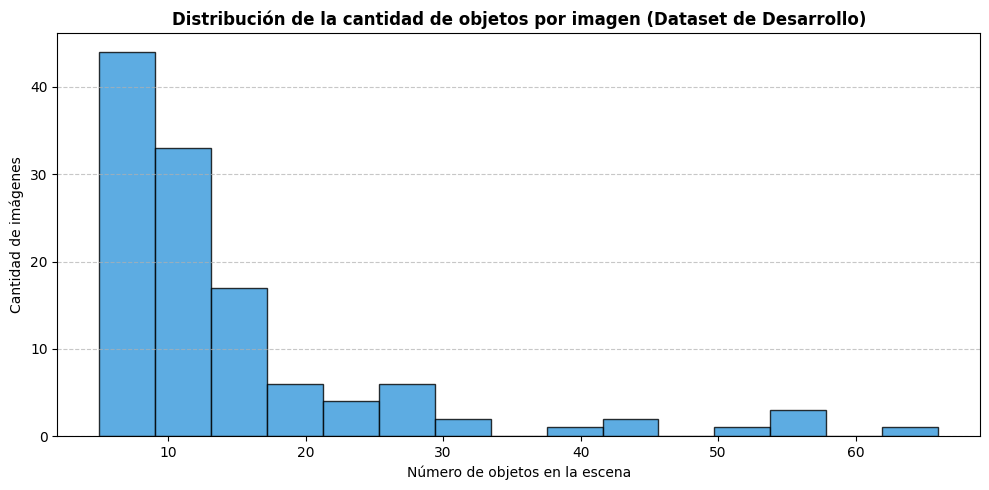

In [3]:
# Rutas del dataset en el entorno de Kaggle
base_dir = "/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas"
dev_images_dir = os.path.join(base_dir, "development", "images")
ann_path = os.path.join(base_dir, "development", "annotations.json")

# Cargar anotaciones de desarrollo
with open(ann_path, 'r') as f:
    coco_data = json.load(f)

# Extraer información básica
images_info = coco_data.get('images', [])
annotations = coco_data.get('annotations', [])
categories = {cat['id']: cat['name'] for cat in coco_data.get('categories', [])}

# Mapear nombre de archivo por ID de imagen
image_dict = {img['id']: img['file_name'] for img in images_info}

# Contar instancias por imagen
counts_per_image = {}
for ann in annotations:
    img_id = ann['image_id']
    counts_per_image[img_id] = counts_per_image.get(img_id, 0) + 1

df_eda = pd.DataFrame([
    {
        "image_id": img_id,
        "file_name": image_dict.get(img_id, "Desconocido"),
        "num_objetos": counts_per_image.get(img_id, 0)
    }
    for img_id in image_dict.keys()
])

print(f"--- ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---")
print(f"Total de imágenes de desarrollo: {len(images_info)}")
print(f"Total de categorías evaluables: {len(categories)}")
print(f"Total de instancias anotadas: {len(annotations)}")
print(f"Promedio de objetos por imagen: {df_eda['num_objetos'].mean():.2f}")

# Gráfico de distribución de objetos por imagen
plt.figure(figsize=(10, 5))
plt.hist(df_eda['num_objetos'], bins=15, color='#3498db', edgecolor='black', alpha=0.8)
plt.title('Distribución de la cantidad de objetos por imagen (Dataset de Desarrollo)', fontsize=12, fontweight='bold')
plt.xlabel('Número de objetos en la escena')
plt.ylabel('Cantidad de imágenes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Análisis de la densidad de objetos:**
- **Variabilidad en la densidad:** El análisis del dataset de desarrollo (120 imágenes y 1.790 instancias totales) revela un promedio de **14.92 objetos por imagen**, con una distribución sesgada donde la gran mayoría de las escenas concentran entre 5 y 15 instancias.
- **Presencia de valores extremos:** Se identificaron escenas complejas que superan los 40 y llegan hasta los 60 objetos, lo cual confirma la existencia de alta densidad y posibles oclusiones en el dataset.
- **Decisión técnica:** Esta diversidad de escalas y densidad nos obliga a configurar cuidadosamente los umbrales de confianza del detector *open-vocabulary* y a supervisar de cerca cómo SAM2 recorta las máscaras en zonas de solapamiento, evitando así la propagación de errores hacia la representación estructurada en JSON.

### 1.2. Top de Categorías más Frecuentes
Para comprender mejor la composición semántica del conjunto de desarrollo (compuesto por 120 categorías evaluables derivadas de LVIS/COCO), analizaremos cuáles son las clases con mayor cantidad de instancias anotadas. Esto nos permite identificar si existe un desbalance en el dataset y qué tipos de objetos predominan en las escenas.

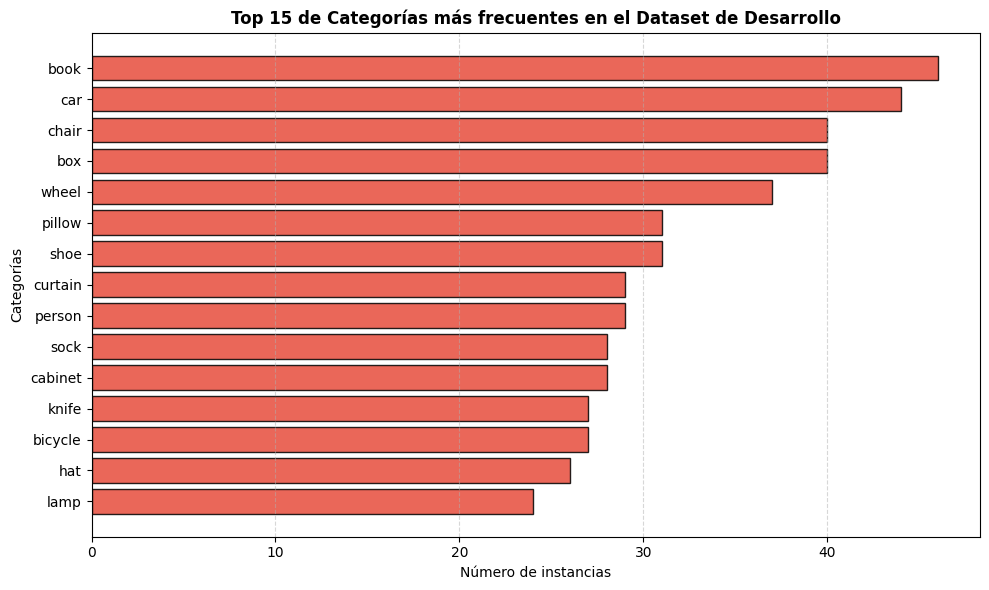

In [4]:
# Rutas y carga del JSON
base_dir = (
    "/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas"
)
ann_path = os.path.join(base_dir, "development", "annotations.json")

with open(ann_path, "r") as f:
    coco_data = json.load(f)

categories_dict = {cat["id"]: cat["name"] for cat in coco_data.get("categories", [])}

# Contar frecuencias por categoría
cat_counts = {}
for ann in coco_data.get("annotations", []):
    cat_id = ann["category_id"]
    cat_name = categories_dict.get(cat_id, str(cat_id))
    cat_counts[cat_name] = cat_counts.get(cat_name, 0) + 1

# Convertir a DataFrame y ordenar
df_cats = pd.DataFrame(
    list(cat_counts.items()), columns=["Categoria", "Frecuencia"]
).sort_values(by="Frecuencia", ascending=False)

# Gráfico de barras horizontales (Top 15)
plt.figure(figsize=(10, 6))
top_n = 15
plt.barh(
    df_cats["Categoria"].head(top_n)[::-1],
    df_cats["Frecuencia"].head(top_n)[::-1],
    color="#e74c3c",
    edgecolor="black",
    alpha=0.85,
)
plt.title(
    f"Top {top_n} de Categorías más frecuentes en el Dataset de Desarrollo",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Número de instancias")
plt.ylabel("Categorías")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Análisis de la distribución de categorías:**
- **Variabilidad semántica:** El análisis del Top 15 de categorías más frecuentes muestra una variedad heterogénea de objetos cotidianos, destacándose elementos como *book*, *car*, *chair* y *box* en las posiciones con mayor cantidad de instancias. No se observa una única clase que monopolice el dataset, sino una representación distribuida entre mobiliario, elementos de interior y objetos de uso diario pertenecientes a las categorías evaluables.
- **Decisión técnica:** Esta diversidad semántica justifica y valida la elección de un enfoque *open-vocabulary*, ya que el sistema de detección debe ser capaz de adaptarse dinámicamente a múltiples tipos de objetos sin depender de un conjunto cerrado de clases fijas.

### 1.3. Distribución del Tamaño Relativo de los Objetos
El enunciado del trabajo advierte que las imágenes presentan distinta cantidad de instancias y tamaños de objeto variables. Para dimensionar este desafío, calcularemos el área relativa de cada *bounding box* respecto a la superficie total de su imagen. Esto nos permitirá ver si predominan objetos pequeños, medianos o grandes, lo cual impacta directamente en el rendimiento de los detectores y de SAM2.

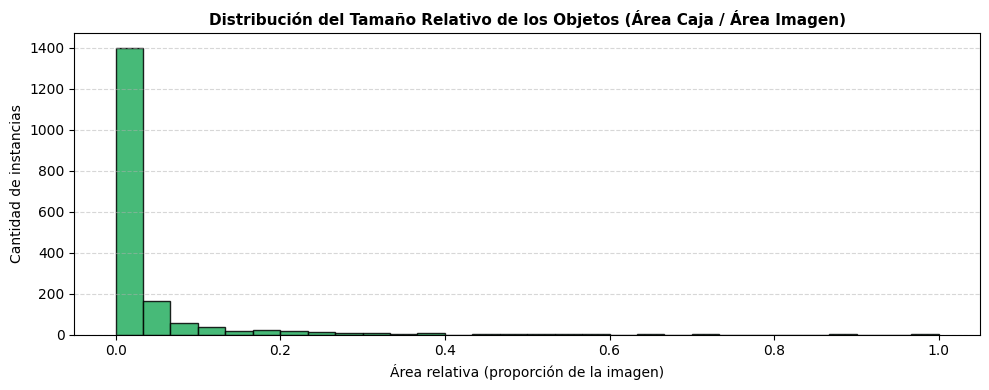

Área relativa promedio de los objetos: 0.0375
Mediana del área relativa: 0.0061 (el 50% de los objetos son menores a esto)


In [5]:
# Mapear dimensiones de cada imagen (ancho y alto)
image_dimensions = {
    img["id"]: (img["width"], img["height"]) for img in coco_data.get("images", [])
}

relative_areas = []

for ann in coco_data.get("annotations", []):
    img_id = ann["image_id"]
    if img_id in image_dimensions:
        img_w, img_h = image_dimensions[img_id]
        box_w, box_h = ann["bbox"][2], ann[
            "bbox"
        ][3]  # formato COCO: [x, y, width, height]

        # Calcular área relativa (Área de la caja / Área total de la imagen)
        box_area = box_w * box_h
        img_area = img_w * img_h
        if img_area > 0:
            rel_area = box_area / img_area
            relative_areas.append(rel_area)

# Gráfico de distribución de áreas relativas
plt.figure(figsize=(10, 4))
plt.hist(
    relative_areas,
    bins=30,
    color="#27ae60",
    edgecolor="black",
    alpha=0.85,
    range=(0, 1),
)
plt.title(
    "Distribución del Tamaño Relativo de los Objetos (Área Caja / Área Imagen)",
    fontsize=11,
    fontweight="bold",
)
plt.xlabel("Área relativa (proporción de la imagen)")
plt.ylabel("Cantidad de instancias")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Área relativa promedio de los objetos: {np.mean(relative_areas):.4f}")
print(
    f"Mediana del área relativa: {np.median(relative_areas):.4f} (el 50% de los objetos son menores a esto)"
)

**Análisis de la escala de los objetos:**
- **Distribución geométrica:** El cálculo de la proporción geométrica (área del *bounding box* dividida por el área total de la imagen) muestra que la distribución está fuertemente sesgada hacia valores cercanos a cero, arrojando un **área relativa promedio de 0.0375** y una **mediana de 0.0061**. Esto significa que la mitad de los objetos analizados ocupan menos del 0.6% de la superficie total de la escena, evidenciando una altísima predominancia de **objetos pequeños**.
- **Decisión técnica:** La abundancia de instancias pequeñas representa una dificultad técnica crítica para la pipeline. Los objetos de escala reducida son altamente sensibles a los errores de redondeo, a las métricas de solapamiento ($IoU$) y a la pérdida de detalle espacial durante la segmentación con SAM2. Por lo tanto, este hallazgo nos obliga a prestar especial atención a la resolución de entrada y a los umbrales de confianza del detector para evitar falsos negativos en elementos lejanos o diminutos.

### 1.4. Análisis de la Política de Anotación LVIS

Una de las particularidades clave del dataset provisto por la cátedra es el uso de anotaciones basadas en LVIS y su esquema de evaluación federada. En este tipo de datasets, debido a la amplitud del vocabulario, no se asume que todas las categorías hayan sido verificadas exhaustivamente en cada imagen.

Por lo tanto, para caracterizar correctamente el entorno sobre el cual evaluaremos nuestra pipeline, es necesario analizar la distribución de las categorías negativas (verificadas como ausentes) y las categorías no exhaustivas en el conjunto de desarrollo. Esto nos permitirá dimensionar cómo impactará esta política en el cálculo futuro de las métricas de precisión y *recall*.

In [6]:
num_images_with_negatives = 0
total_negatives = 0
total_not_exhaustive = 0

images_list = coco_data.get('images', [])

for img_info in images_list:
    # Metadatos de LVIS asociados a cada imagen
    neg_cats = img_info.get('neg_category_ids', [])
    not_ex_cats = img_info.get('not_exhaustive_category_ids', [])

    if len(neg_cats) > 0:
        num_images_with_negatives += 1
        total_negatives += len(neg_cats)

    if len(not_ex_cats) > 0:
        total_not_exhaustive += len(not_ex_cats)

print(f"--- ANÁLISIS DE ANOTACIONES LVIS / FEDERADAS ---")
print(f"Imágenes con al menos una categoría declarada como negativa (ausente): {num_images_with_negatives} de {len(images_list)}")
print(f"Total acumulado de declaraciones de categorías negativas: {total_negatives}")
print(f"Total acumulado de declaraciones no exhaustivas: {total_not_exhaustive}")
print(f"Promedio de categorías negativas por imagen: {total_negatives / len(images_list):.2f}")

--- ANÁLISIS DE ANOTACIONES LVIS / FEDERADAS ---
Imágenes con al menos una categoría declarada como negativa (ausente): 74 de 120
Total acumulado de declaraciones de categorías negativas: 118
Total acumulado de declaraciones no exhaustivas: 47
Promedio de categorías negativas por imagen: 0.98


**Análisis de la política de anotación LVIS:**
- **Presencia activa de evaluación federada:** El análisis de los metadatos de desarrollo revela que **74 de las 120 imágenes** cuentan con declaraciones explícitas de categorías negativas (`neg_category_ids`), acumulando un total de **118 clases verificadas como ausentes** (un promedio de **0.98 por imagen**). Asimismo, se registraron **47 declaraciones de categorías no exhaustivas** (`not_exhaustive_category_ids`).
- **Impacto analítico:** Estos números confirman que el dataset no asume una ausencia total ingenua de clases. En las imágenes analizadas, predecir una categoría que figura en la lista de negativas penalizará de forma directa al sistema como un falso positivo. Por el contrario, las categorías no verificadas (la gran mayoría del vocabulario de 120 clases que no figura ni como positiva ni como negativa) deberán ser ignoradas en el cálculo de precisión.
- **Decisión técnica:** Para cumplir rigurosamente con los criterios de evaluación de la cátedra, implementaremos un módulo de evaluación local que respete la partición federada de LVIS. Esto evitará penalizaciones injustas por falsos positivos en clases no verificadas y asegurará que nuestra experimentación end-to-end refleje de manera fiel las métricas oficiales de la competencia.

### 1.5. Análisis del Benchmark de Preguntas (VQA)
Para diseñar un módulo de Preguntas y Respuestas Visuales (VQA) robusto, es fundamental analizar el benchmark de evaluación provisto (`questions_dev.jsonl`). Estudiaremos la distribución de los tipos de preguntas y las clases que la cátedra busca evaluar para alinear nuestro motor de inferencia con los requisitos reales de la competencia.

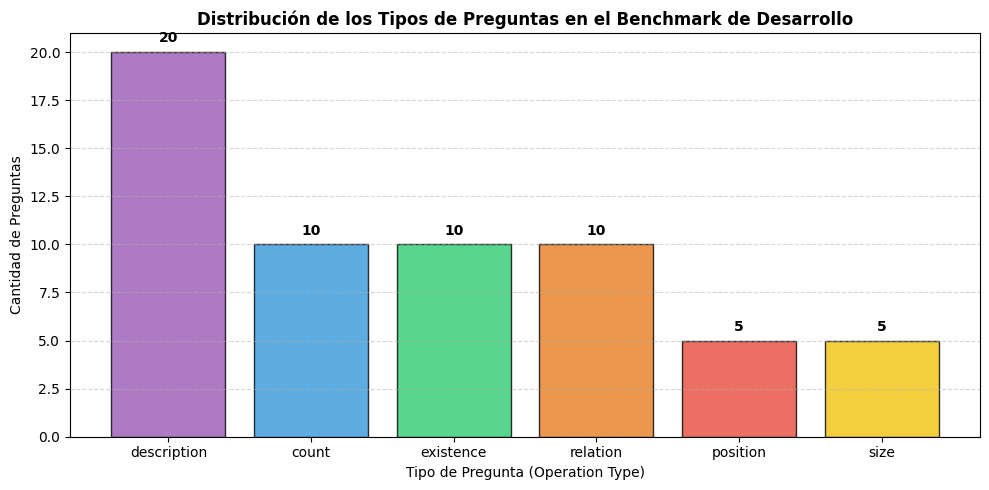

--- ANÁLISIS DEL BENCHMARK DE PREGUNTAS (VQA) ---
Total de preguntas analizadas: 60
Imágenes únicas evaluadas: 20
Formatos de respuesta requeridos:
answer_format
free_text       20
boolean         20
integer         10
position_3x3     5
size_class       5


In [7]:
# Cargar y analizar el archivo de preguntas de desarrollo
bench_path = "/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_2026_qa_public/questions_dev.jsonl"

with open(bench_path, 'r') as f:
    bench_data = [json.loads(line) for line in f]

# Convertir a DataFrame
df_bench = pd.DataFrame(bench_data)

# 1. Distribución de tipos de preguntas
type_counts = df_bench['type'].value_counts()

plt.figure(figsize=(10, 5))
colors_vqa = ['#9b59b6', '#3498db', '#2ecc71', '#e67e22', '#e74c3c', '#f1c40f']
plt.bar(type_counts.index, type_counts.values, color=colors_vqa, edgecolor='black', alpha=0.8)
plt.title('Distribución de los Tipos de Preguntas en el Benchmark de Desarrollo', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Pregunta (Operation Type)')
plt.ylabel('Cantidad de Preguntas')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Agregar valores sobre las barras
for i, val in enumerate(type_counts.values):
    plt.text(i, val + 0.5, str(val), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Análisis del formato de respuesta requerido
print("--- ANÁLISIS DEL BENCHMARK DE PREGUNTAS (VQA) ---")
print(f"Total de preguntas analizadas: {len(df_bench)}")
print(f"Imágenes únicas evaluadas: {df_bench['image_file'].nunique()}")
print(f"Formatos de respuesta requeridos:\n{df_bench['answer_format'].value_counts().to_string()}")

**Análisis del Benchmark de Preguntas (VQA):**
- **Distribución de operaciones:** El benchmark de desarrollo consta de **60 preguntas distribuidas en 20 imágenes únicas** (~3 preguntas por escena). El tipo de consulta predominante es `description` (20 preguntas, una por escena), seguido por una distribución equitativa de tareas analíticas: `count` (10), `existence` (10) y `relation` (10). Las operaciones de alineación espacial y geométrica fina (`position` y `size`) representan un volumen menor con 5 preguntas cada una.
- **Diversidad de formatos de salida:** El sistema debe ser capaz de estructurar respuestas bajo formatos altamente heterogéneos: texto libre (`free_text`), respuestas booleanas rígidas (`boolean`), valores numéricos discretos (`integer`), o selectores categóricos específicos de la grilla de celdas (`position_3x3`) y escalas geométricas (`size_class`).
- **Decisión técnica:** Esta caracterización metodológica fundamenta la necesidad de diseñar un motor de ejecución determinista y desacoplado de la inferencia del lenguaje natural para las preguntas analíticas (evitando alucinaciones numéricas o espaciales), y reservar el uso de Modelos de Lenguaje (LLMs) exclusivamente para la síntesis de texto libre de las descripciones globales, asegurando el cumplimiento estricto del esquema unificado de salida.

## 2. Módulo de Percepción: Detección Open-Vocabulary

En esta etapa de la pipeline implementaremos el sistema de localización de objetos. De acuerdo a los requerimientos del trabajo, es necesario utilizar un detector *open-vocabulary* capaz de adaptarse dinámicamente a las 120 clases evaluables sin depender de un entrenamiento cerrado con etiquetas fijas.

Para cumplir con el requerimiento de diseñar una **pipeline modular y trazable**, encapsularemos la lógica de detección en una clase Python. Esto nos permitirá:
1. Registrar la configuración (modelo, resolución, umbrales) en cada ejecución.
2. Intercambiar el modelo subyacente si decidimos experimentar con otras arquitecturas (ej. Grounding DINO) más adelante.

**Selección del modelo base:**
Iniciaremos nuestros experimentos utilizando **OWLv2** (`google/owlv2-base-patch16-ensemble`). Elegimos esta arquitectura porque ha demostrado ser muy robusta para procesar *prompts* de texto ("a photo of a [categoría]") y ofrece un buen balance entre velocidad de inferencia y sensibilidad para detectar variabilidad de escalas.

**Resolución de entrada:** OWLv2 B/16 rellena cada imagen a un cuadrado y la reescala a 960×960 px. Las imágenes del dataset miden ~640×480, por lo que el modelo las amplía ~1,5×; aun así, los objetos que ocupan menos del 1 % de la imagen quedan representados por muy pocos parches de 16 px. Esta limitación motiva la inferencia por mosaicos de la sección 10. Las cajas se reescalan al lado mayor de la imagen para compensar el relleno; en la versión de `transformers` usada, el post-procesamiento ya lo hace (ver experimento `pad_fix` en la sección 7).

In [8]:
class OpenVocabDetector:
    def __init__(self, model_id="google/owlv2-base-patch16-ensemble", device=None, pad_fix=False):
        """
        Inicializa el detector. Mantenemos el modelo modular para facilitar la trazabilidad.
        """
        self.device = device if device else ("cuda" if torch.cuda.is_available() else "cpu")
        print(f"Cargando {model_id} en {self.device}...")

        self.processor = Owlv2Processor.from_pretrained(model_id)
        self.model = Owlv2ForObjectDetection.from_pretrained(model_id).to(self.device)
        self.model.eval()

        # Guardamos la configuración para la traza auditable
        self.config = {
            "model_id": model_id,
            "resolution": "default_owlv2",
        }
        self.pad_fix = pad_fix
        self.config = {"model_id": model_id, "resolution": "default_owlv2", "pad_fix": pad_fix}

    def detect(self, image_path, vocabulary, confidence_threshold=0.1, nms_threshold=0.3):
        """
        Realiza la detección sobre una imagen dado un vocabulario.
        Aplica NMS (Non-Maximum Suppression) para eliminar detecciones duplicadas.
        """
        image = Image.open(image_path).convert("RGB")

        # Preprocesamiento con prompts de texto basados en el vocabulario
        text_queries = [f"a photo of a {cat}" for cat in vocabulary]

        inputs = self.processor(text=text_queries, images=image, return_tensors="pt").to(self.device)

        with torch.no_grad():
            outputs = self.model(**inputs)

        # Post-procesamiento crudo
        W, H = image.size
        if self.pad_fix:   # OWLv2 rellena a cuadrado: reescalar al lado mayor
            target_sizes = torch.tensor([[max(W, H), max(W, H)]], device=self.device)
        else:
            target_sizes = torch.tensor([image.size[::-1]]).to(self.device)
        results = self.processor.image_processor.post_process_object_detection(
            outputs=outputs,
            target_sizes=target_sizes,
            threshold=confidence_threshold
        )[0]
        if self.pad_fix:
            results["boxes"][:, [0, 2]] = results["boxes"][:, [0, 2]].clamp(0, W)
            results["boxes"][:, [1, 3]] = results["boxes"][:, [1, 3]].clamp(0, H)

        # --- Supresión de No Máximos (NMS) ---
        # Usamos batched_nms para aplicar NMS de forma independiente para cada clase.
        # Si dos cajas de la misma clase se superponen más que el nms_threshold, conserva la de mayor score.
        keep_indices = torchvision.ops.batched_nms(
            boxes=results["boxes"],
            scores=results["scores"],
            idxs=results["labels"],
            iou_threshold=nms_threshold
        )
        self.last_stats = {"n_above_threshold": int(len(results["scores"])),
                           "n_after_nms": int(len(keep_indices))}

        # Formatear la salida filtrada para la siguiente etapa (SAM2)
        detections = []
        for idx in keep_indices:
            score = results["scores"][idx].item()
            label = results["labels"][idx].item()
            box = results["boxes"][idx].tolist()

            detections.append({
                "category": vocabulary[label],
                "confidence": round(score, 4),
                "bbox": [round(i, 2) for i in box] # [xmin, ymin, xmax, ymax]
            })

        return detections, image.size

### 2.1. Experimento Base: Inferencia y Ajuste de Umbrales

Antes de procesar todo el conjunto de desarrollo, realizaremos pruebas controladas sobre imágenes individuales para calibrar los hiperparámetros de nuestro detector.

**Justificación del Umbral de Confianza (*Confidence Threshold*):**
Tal como descubrimos en la sección 1.3 de nuestro Análisis Exploratorio de Datos (EDA), **el 50% de los objetos en este dataset ocupan menos del 0.6% del área de la imagen**. La altísima predominancia de objetos pequeños nos obliga a tomar una decisión de compromiso:
* Si utilizamos un umbral de confianza alto (ej. `0.5` o `0.6`), el detector ignorará los objetos diminutos o difuminados en el fondo, impactando negativamente y de forma irreversible en la métrica de *Recall* (generando Falsos Negativos).
* Por lo tanto, configuraremos inicialmente un umbral permisivo bajo (0,15) para maximizar la recuperación de instancias, asumiendo más cajas ruidosas en esta etapa. Los duplicados de una misma clase se eliminan con NMS por clase; SAM2 no filtra detecciones, sólo las segmenta. Este valor es el punto de partida de la línea base: el umbral definitivo (0,23, combinado con inferencia por mosaicos) se seleccionó experimentalmente en las secciones 8 y 10.

Cargando google/owlv2-base-patch16-ensemble en cuda...


preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

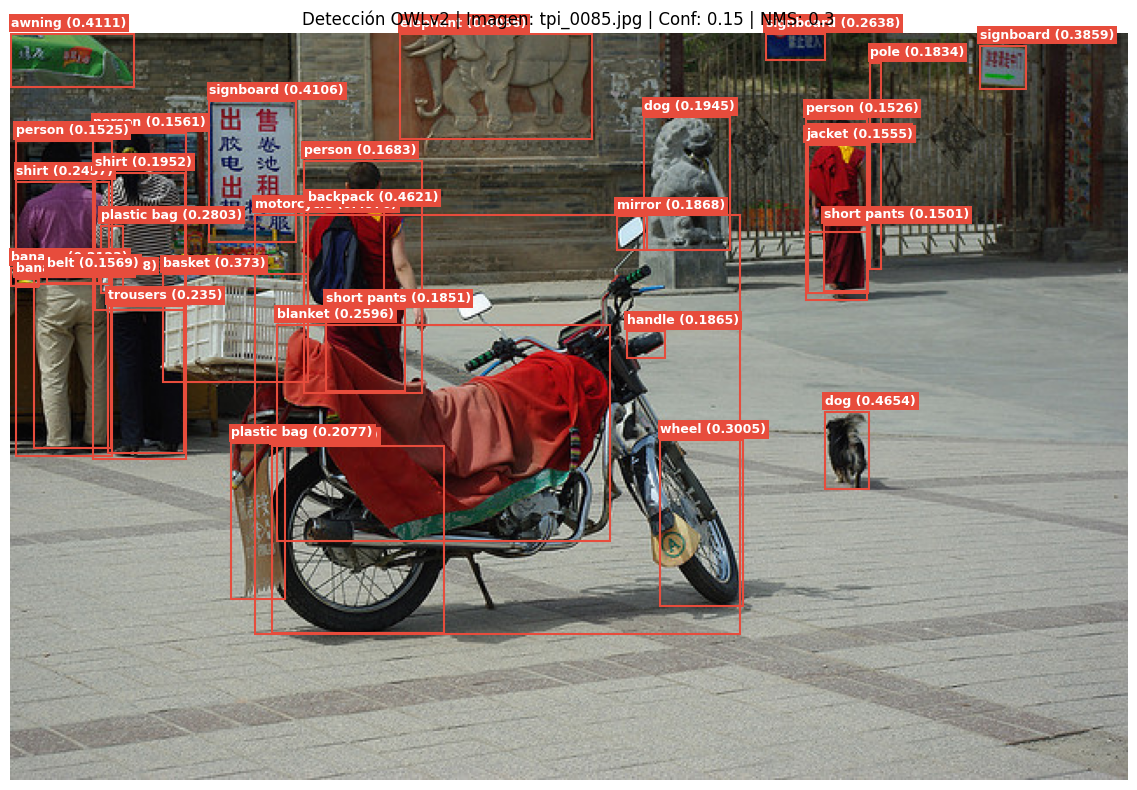

Total de instancias detectadas post-NMS: 33


In [9]:
# Instanciamos el modelo de detección Open-Vocabulary
detector = OpenVocabDetector()

# 1. Carga de vocabulario
# Extraemos las 120 categorías evaluables identificadas durante el EDA.
eval_vocabulary = [cat['name'] for cat in coco_data.get('categories', [])]
#creo que este cat name to id esta mal porque no podemos consumir de las anotaciones? puede ser?
CAT_NAME_TO_ID = {c["name"]: c["id"] for c in coco_data["categories"]}

# Seleccionamos una imagen específica para garantizar la reproducibilidad del análisis cualitativo
target_file = "tpi_0085.jpg"
random_img_info = next((img for img in coco_data['images'] if img['file_name'] == target_file), None)
sample_img_path = os.path.join(dev_images_dir, random_img_info['file_name'])

# 2. Inferencia y calibración de umbrales
# Fijamos un umbral de confianza intencionalmente bajo (0.15) basándonos en la distribución de áreas relativas observada en el EDA (sección 2.3).
# El objetivo es minimizar falsos negativos en objetos pequeños.
# Los falsos positivos por duplicación se mitigan internamente mediante NMS (IoU=0.3).
CONFIDENCE_THRESHOLD = 0.15
NMS_THRESHOLD = 0.30

detections, img_size = detector.detect(
    image_path=sample_img_path,
    vocabulary=eval_vocabulary,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    nms_threshold=NMS_THRESHOLD
)

# 3. Inspección visual de las predicciones (Grounding)
img = Image.open(sample_img_path)
fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(img)

for det in detections:
    box = det["bbox"]
    xmin, ymin, xmax, ymax = box
    width, height = xmax - xmin, ymax - ymin

    # Dibujar la caja delimitadora (Bounding Box)
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=1.5, edgecolor='#e74c3c', facecolor='none')
    ax.add_patch(rect)

    # Etiqueta de clase y score
    label_text = f"{det['category']} ({det['confidence']})"
    ax.text(xmin, ymin - 4, label_text, color='white', fontsize=9, weight='bold',
            backgroundcolor='#e74c3c', bbox=dict(facecolor='#e74c3c', edgecolor='none', pad=2))

plt.title(f"Detección OWLv2 | Imagen: {random_img_info['file_name']} | Conf: {CONFIDENCE_THRESHOLD} | NMS: {NMS_THRESHOLD}")
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"Total de instancias detectadas post-NMS: {len(detections)}")

### 2.2. Análisis Cualitativo del Experimento Base

La ejecución del detector OWLv2 sobre la imagen de prueba (`tpi_0085.jpg`) arrojó **33 instancias detectadas**. Es fundamental destacar que esta inferencia se realizó de manera autónoma utilizando los *prompts* de texto del vocabulario (120 clases), sin consultar ni proveer al modelo las anotaciones de *ground truth* en ningún momento, respetando la política de desarrollo del trabajo. *(Nota: el valor numérico junto a cada clase detectada representa el puntaje de confianza o "confidence score" de la predicción).*

De la inspección cualitativa extraemos las siguientes conclusiones que impactarán en la etapa de segmentación:

1. **Validación del umbral permisivo (Recall sobre Precisión):** La decisión de utilizar un `CONFIDENCE_THRESHOLD = 0.15` resultó exitosa para abordar el problema de la variabilidad de escalas analizado en el EDA. El modelo logró capturar objetos pequeños o lejanos, como el perro (`dog` - 0.4655) en segundo plano y el cartel (`signboard` - 0.3859) en la estructura del fondo.
2. **Anidamiento semántico (Jerarquías visuales):** Se observa una alta densidad de detecciones superpuestas válidas. Por ejemplo, en los transeúntes, el modelo no solo detecta la instancia contenedora (`person`), sino también los atributos que la componen (`shirt`, `trousers`, `backpack`). Esto confirma que la Supresión de No Máximos (NMS) por clase funcionó correctamente (permitiendo cajas superpuestas de distintas categorías), pero representará un desafío para SAM2, ya que los *prompts* de las prendas estarán contenidos geométricamente dentro del *prompt* de la persona.
3. **Ambigüedad y ruidos del modelo:** El detector *open-vocabulary* confía puramente en los patrones visuales, lo que genera detecciones técnicamente correctas pero semánticamente erróneas según el contexto humano. Un caso notable es la estatua de piedra en el fondo, detectada como `dog` (0.1945), y el relieve en la pared, detectado como `elephant`. Este comportamiento es esperado y será documentado en la sección final de análisis de errores.

**Conclusión de la etapa:** El nivel de exhaustividad espacial del detector es adecuado. Las 33 *bounding boxes* obtenidas, con sus respectivos recortes, constituyen un punto de partida robusto para ser utilizadas como *prompts* geométricos en el módulo de segmentación de instancias (SAM2).

## 3. Segmentación de Instancias con SAM2

Con las *bounding boxes* obtenidas y validadas cualitativamente, procedemos a la etapa de segmentación. Para esto, implementamos una clase encapsulada que instancia *Segment Anything 2* (SAM2).

La estrategia consiste en utilizar las cajas generadas por OWLv2 como *prompts* geométricos directos. Para optimizar el rendimiento, el *embedding* de la imagen se calcula una única vez (`set_image`), y luego se itera sobre las detecciones solicitando a SAM2 que devuelva exclusivamente la máscara con mayor puntaje de confianza (`multimask_output=False`).

In [10]:
class SAM2Segmenter:
    def __init__(self, checkpoint_path, model_cfg, device=None):
        self.device = device if device else ("cuda" if torch.cuda.is_available() else "cpu")
        print(f"Cargando SAM2 en: {self.device}...")

        # Construcción del modelo base y el predictor de imágenes
        self.sam2_model = build_sam2(model_cfg, checkpoint_path, device=self.device)
        self.predictor = SAM2ImagePredictor(self.sam2_model)

    def predict_masks(self, image_rgb, detections):
        """
        Recibe la imagen y las detecciones de OWLv2, devuelve las detecciones enriquecidas con máscaras.
        """
        # 1. Computar los embeddings de la imagen (una sola vez por imagen)
        self.predictor.set_image(image_rgb)

        results = []

        # 2. Iterar sobre cada bounding box detectada
        for det in detections:
            input_box = np.array(det['box'])

            # 3. Predecir la máscara usando la caja como prompt
            masks, scores, _ = self.predictor.predict(
                point_coords=None,
                point_labels=None,
                box=input_box[None, :],
                multimask_output=False
            )

            # 4. Enriquecer el diccionario original
            det_with_mask = det.copy()
            det_with_mask['mask'] = masks[0]           # Máscara binaria (True/False)
            det_with_mask['mask_score'] = float(scores[0])    # Confianza de SAM2

            results.append(det_with_mask)

        return results

### 3.1. Ejecución y Validación Visual

Con la arquitectura del segmentador definida, el siguiente paso es instanciar el modelo cargando los pesos correspondientes y procesar las 33 detecciones generadas previamente por OWLv2.

En esta etapa, el sistema evalúa la imagen base de forma unificada y luego iterativamente utiliza cada *bounding box* como una sugerencia espacial (*prompt*) para extraer el objeto contenido.

Para confirmar que la integración entre ambos modelos funciona correctamente, graficaremos el resultado de la primera detección. Esto nos permitirá validar de forma visual que la máscara binaria generada por SAM2 se ajusta con precisión a los contornos del objeto indicado.

Cargando SAM2 en: cuda...
¡Éxito! Se generaron 33 máscaras.


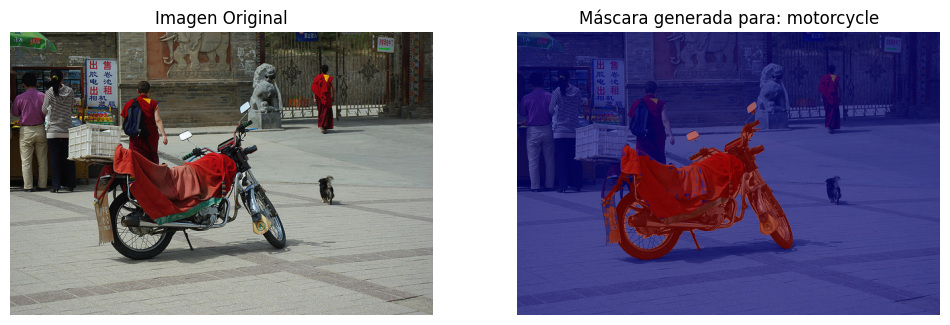

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# 1. Definir rutas
#SAM2_CHECKPOINT = "sam2_hiera_small.pt"
SAM2_CHECKPOINT = "/kaggle/working/sam2_hiera_small.pt"
SAM2_MODEL_CFG = "sam2_hiera_s.yaml"

# 2. Instanciar el segmentador
segmenter = SAM2Segmenter(checkpoint_path=SAM2_CHECKPOINT, model_cfg=SAM2_MODEL_CFG)

# 3. Ruta de la imagen y ejecución del detector
ruta_imagen = "/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/development/images/tpi_0085.jpg"
resultado_deteccion = detector.detect(ruta_imagen, eval_vocabulary, CONFIDENCE_THRESHOLD, NMS_THRESHOLD)

# Como 'resultado_deteccion' es una tupla, extraemos la lista de diccionarios (usualmente el elemento 0)
# Ajusta el índice si la lista está en otra posición de la tupla devuelta por tu detector.
lista_de_detecciones = resultado_deteccion[0] if isinstance(resultado_deteccion, tuple) else resultado_deteccion

# 4. Cargar la imagen en memoria en formato RGB para SAM2 y la visualización
image_rgb = np.array(Image.open(ruta_imagen).convert("RGB"))

# 5. Ejecutar la segmentación adaptando temporalmente las claves si es necesario,
# o asegurándonos de que SAM2Segmenter lea 'bbox'.
# Si tu SAM2Segmenter busca 'box', podemos mapearlo rápido antes de dárselo:
##detecciones_para_sam = [{'box': d['bbox'], 'label': d['category']} for d in lista_de_detecciones]
detecciones_para_sam = [{'box': d['bbox'], 'label': d['category'], 'confidence': d['confidence']}
                        for d in lista_de_detecciones]
detecciones_con_mascaras = segmenter.predict_masks(image_rgb, detecciones_para_sam)
print(f"¡Éxito! Se generaron {len(detecciones_con_mascaras)} máscaras.")

# 6. Visualización rápida de prueba
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image_rgb)
ax[0].set_title("Imagen Original")
ax[0].axis('off')

primera_deteccion = detecciones_con_mascaras[0]
ax[1].imshow(image_rgb)
ax[1].imshow(primera_deteccion['mask'], alpha=0.6, cmap='jet')
ax[1].set_title(f"Máscara generada para: {primera_deteccion['label']}")
ax[1].axis('off')

plt.show()

### Etapa de Segmentación con Segment Anything 2 (SAM2)

En esta etapa se integraron los resultados del detector de vocabulario abierto (OWLv2) con el modelo de segmentación de alta precisión **SAM2** (`SAM2ImagePredictor`). El proceso consistió en:

1. **Carga del Modelo:** Se inicializó el segmentador utilizando los pesos preentrenados y la configuración de la arquitectura (`sam2_hiera_small.pt`).
2. **Procesamiento de Prompts Geométricos:** Las coordenadas de las *bounding boxes* obtenidas por OWLv2 (que actúan como cajas delimitadoras o *prompts*) fueron suministradas como entradas espaciales a SAM2.
3. **Generación de Máscaras:** SAM2 procesó la imagen original a nivel de píxel para cada una de las detecciones, logrando aislar con exactitud los objetos detectados (generando un total de 33 máscaras en esta imagen de prueba).
4. **Validación Visual:** Se visualizó de forma comparativa la imagen original frente a la máscara generada (por ejemplo, para la categoría *motorcycle*), comprobando la correcta correspondencia entre la detección inicial y el recorte segmentado.

## 4. Representación estructurada de la escena

### 4.1. Fundamentos de la Representación Estructurada (SceneJSON)

La conversión de las predicciones crudas de los modelos de Deep Learning (OWLv2 y SAM2) en una estructura jerárquica de grafo de escena (`SceneJSON`) responde a la necesidad de dotar de semántica física e interpretable al razonamiento computacional. Este proceso de estructuración se fundamenta en tres pilares:

#### 1. Discretización Espacial y Centroides
Para evitar que el motor de consultas dependa de coordenadas de píxeles continuas (altamente variables según la resolución de la cámara), normalizamos la ubicación del objeto proyectando su centroide de masa $(\bar{x}, \bar{y})$ sobre una grilla virtual de $3 \times 3$. 
El centroide de masa se calcula sobre la máscara binaria real del objeto:
$$\bar{x} = \frac{1}{A} \sum_{i=1}^{H} \sum_{j=1}^{W} j \cdot M(i,j), \quad \bar{y} = \frac{1}{A} \sum_{i=1}^{H} \sum_{j=1}^{W} i \cdot M(i,j)$$
Donde $M(i,j) \in \{0,1\}$ representa el valor del píxel en la máscara y $A$ es el área total en píxeles ($A = \sum M(i,j)$). Si la segmentación falla y devuelve una máscara vacía, el sistema activa un mecanismo de seguridad (*fallback*) que aproxima el centro geométrico directamente desde la caja delimitadora (*bounding box*).

#### 2. Clasificación Geométrica de Escalas (Tamaño)
Clasificar los objetos como `small` (pequeño), `medium` (mediano) o `large` (grande) no es una decisión arbitraria. El umbral se define analíticamente a partir de los cuantiles del tamaño relativo de los objetos obtenidos en nuestro EDA (Sección 1.3):
- **small (área < 1 %):** con la mediana del área relativa en 0,61 % (EDA, sección 1.3), este umbral agrupa a la mayoría de las instancias: el 71 % de las anotaciones (1272 de 1790) es *small*. Son los objetos más sensibles a oclusión y ruido.
- **medium (1 % ≤ área < 10 %):** objetos de escala humana (24 % de las instancias).
- **large (área ≥ 10 %):** elementos dominantes de la escena (5 % de las instancias).

Nota: el EDA calcula el área relativa con la caja; en el SceneJSON, `size` se calcula con el área de la máscara, que es una medida más fiel del objeto. Por eso las proporciones difieren levemente.

#### 3. Compresión RLE (Run-Length Encoding) para Máscaras binarias
Almacenar una máscara binaria de $640 \times 480$ píxeles como una matriz de booleanos requeriría transferir matrices masivas en formato JSON, haciéndolo inviable a nivel de red y almacenamiento. Para resolver esto, implementamos la codificación RLE de COCO, que comprime la matriz aplanada en una secuencia ordenada de conteos de alternancia entre píxeles de fondo (0) y objeto (1). Esto reduce drásticamente el tamaño del archivo de entrega final (submission) manteniendo una fidelidad del 100% en la geometría del objeto.

In [12]:
def mask_to_rle(mask):
    m = mask.ravel(order="F").astype(np.uint8)
    bounds = np.concatenate([[0], np.flatnonzero(np.diff(m)) + 1, [m.size]])
    counts = np.diff(bounds).tolist()
    if m[0] == 1:
        counts = [0] + counts   # COCO siempre arranca contando ceros
    return {"size": [int(mask.shape[0]), int(mask.shape[1])], "counts": counts}

In [13]:
POSITIONS = [["top_left", "top_center", "top_right"],
             ["middle_left", "center", "middle_right"],
             ["bottom_left", "bottom_center", "bottom_right"]]

PALETTE = {"black": (20, 20, 20), "white": (240, 240, 240), "gray": (128, 128, 128),
           "red": (200, 30, 30), "orange": (240, 140, 30), "yellow": (240, 220, 40),
           "green": (40, 160, 60), "blue": (40, 80, 200), "purple": (130, 50, 160),
           "pink": (240, 150, 180), "brown": (120, 75, 40)}

def grid_position(cx, cy, W, H):
    col = min(int(3 * cx / W), 2)
    row = min(int(3 * cy / H), 2)
    return POSITIONS[row][col]

def size_label(rel_area, small_thr=0.01, large_thr=0.10):
    # Umbrales a justificar con los cuantiles de área relativa del EDA
    if rel_area < small_thr:
        return "small"
    return "medium" if rel_area < large_thr else "large"

def dominant_color(image_rgb, mask):
    pix = image_rgb[mask]
    if len(pix) == 0:
        return None
    med = np.median(pix, axis=0)  # la mediana es más robusta que la media ante bordes
    return min(PALETTE, key=lambda k: np.sum((np.array(PALETTE[k]) - med) ** 2))

def object_properties(det, image_rgb):
    mask = det["mask"].astype(bool)
    H, W = mask.shape
    area = int(mask.sum())
    if area > 0:
        ys, xs = np.nonzero(mask)
        cx, cy = xs.mean(), ys.mean()
    else:  # máscara vacía: caemos al centro de la caja y lo dejamos registrado
        x0, y0, x1, y1 = det["box"]
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    rel = area / (W * H)
    cx_r, cy_r = round(float(cx), 2), round(float(cy), 2)
    return {"area": area,
            "area_ratio": float(rel),
            "centroid": [cx_r, cy_r],
            "position": grid_position(cx_r, cy_r, W, H),
            "size": size_label(rel),
            "color": dominant_color(image_rgb, mask)}

In [14]:
def spatial_relations(objects, masks, W, H, margin=0.05, overlap_thr=0.05):
    """Predicados oficiales del schema: left_of, right_of, above, below, overlaps."""
    rels = []
    for i in range(len(objects)):
        for j in range(i + 1, len(objects)):
            a, b = objects[i], objects[j]
            (ax, ay), (bx, by) = a["centroid"], b["centroid"]
            dx, dy = bx - ax, by - ay
            if abs(dx) > margin * W:
                rels.append({"subject": a["id"], "predicate": "left_of" if dx > 0 else "right_of", "object": b["id"]})
            if abs(dy) > margin * H:
                rels.append({"subject": a["id"], "predicate": "above" if dy > 0 else "below", "object": b["id"]})
            inter = np.logical_and(masks[i], masks[j]).sum()
            if inter / max(min(a["area"], b["area"]), 1) > overlap_thr:
                rels.append({"subject": a["id"], "predicate": "overlaps", "object": b["id"]})
    return rels

In [15]:
def check_scene_consistency(scene):
    """Verifica que los valores del SceneJSON sean coherentes entre sí."""
    errors = []
    W, H = scene["image"]["width"], scene["image"]["height"]
    ids = [o["id"] for o in scene["objects"]]
    if len(ids) != len(set(ids)):
        errors.append("ids duplicados")
    for o in scene["objects"]:
        x0, y0, x1, y1 = o["bbox"]
        if not (0 <= x0 < x1 <= W + 1 and 0 <= y0 < y1 <= H + 1):
            errors.append(f"{o['id']}: bbox inválida (debe cumplir 0 <= xmin < xmax y 0 <= ymin < ymax)")
        counts = o["mask"]["counts"]
        if o["mask"]["size"] != [H, W] or sum(counts) != H * W:
            errors.append(f"{o['id']}: RLE con tamaño inconsistente")
        if sum(counts[1::2]) != o["area"]:
            errors.append(f"{o['id']}: el área no coincide con la máscara")
        if abs(o["area"] / (W * H) - o["area_ratio"]) > 1e-9:
            errors.append(f"{o['id']}: area_ratio no coincide con el área")
        if grid_position(*o["centroid"], W, H) != o["position"]:
            errors.append(f"{o['id']}: posición no coincide con el centroide")
        if size_label(o["area_ratio"]) != o["size"]:
            errors.append(f"{o['id']}: tamaño no coincide con area_ratio")
        if not 0 <= o["confidence"] <= 1:
            errors.append(f"{o['id']}: confianza fuera de [0, 1]")
        if o["category_id"] not in CAT_NAME_TO_ID.values():
            errors.append(f"{o['id']}: category_id fuera del vocabulario")
    valid_ids = set(ids)
    for r in scene["relations"]:
        if r["subject"] not in valid_ids or r["object"] not in valid_ids:
            errors.append(f"relación con id inexistente: {r}")
    return errors

In [16]:
import os, json

def build_scene_json(file_name, image_rgb, dets_with_masks):
    H, W = image_rgb.shape[:2]
    dets = sorted(dets_with_masks, key=lambda d: -d["confidence"])
    objects, masks = [], []
    for k, det in enumerate(dets):
        # Caja recortada a los límites de la imagen
        x0, y0, x1, y1 = det["box"]
        x0, y0 = max(0.0, x0), max(0.0, y0)
        x1, y1 = min(float(W), x1), min(float(H), y1)
        if x1 - x0 < 1 or y1 - y0 < 1:   # Kaggle exige xmin < xmax e ymin < ymax
            continue
        # Máscara de respaldo si SAM2 devolvió una vacía
        mask = det["mask"].astype(bool)
        mask_source = "sam2"
        if not mask.any():
            mask = np.zeros((H, W), dtype=bool)
            mask[int(y0):int(np.ceil(y1)), int(x0):int(np.ceil(x1))] = True
            mask_source = "bbox_fallback"
        det = {**det, "box": [x0, y0, x1, y1], "mask": mask}

        objects.append({
            "id": f"obj_{len(objects)}",
            "category_id": CAT_NAME_TO_ID[det["label"]],
            "confidence": round(float(det["confidence"]), 4),
            "bbox": [round(x0, 2), round(y0, 2), round(x1, 2), round(y1, 2)],
            "mask": mask_to_rle(mask),
            **object_properties(det, image_rgb),
            "category_name": det["label"],
            "mask_score": round(det["mask_score"], 4),
            "mask_source": mask_source,
        })
        masks.append(mask)

    return {"image": {"id": os.path.splitext(file_name)[0], "width": W, "height": H},
            "objects": objects,
            "relations": spatial_relations(objects, masks, W, H),
            "questions": [],
            "questions_llm": []}

scene = build_scene_json(target_file, image_rgb, detecciones_con_mascaras)

errores = check_scene_consistency(scene)
print("Consistencia:", "OK" if not errores else errores[:10])
print("Objetos con máscara de respaldo:", sum(o["mask_source"] == "bbox_fallback" for o in scene["objects"]))

# Vista legible, sin los counts del RLE que son enormes
preview = {**scene, "objects": [{k: v for k, v in o.items() if k != "mask"} for o in scene["objects"]]}
print(json.dumps(preview, indent=2, ensure_ascii=False)[:3000])
print("JSON serializable:", len(json.dumps(scene)) > 0)

Consistencia: OK
Objetos con máscara de respaldo: 0
{
  "image": {
    "id": "tpi_0085",
    "width": 640,
    "height": 428
  },
  "objects": [
    {
      "id": "obj_0",
      "category_id": 73,
      "confidence": 0.4976,
      "bbox": [
        139.82,
        103.61,
        417.5,
        343.64
      ],
      "area": 30316,
      "area_ratio": 0.11067464953271028,
      "centroid": [
        267.72,
        248.35
      ],
      "position": "center",
      "size": "large",
      "color": "brown",
      "category_name": "motorcycle",
      "mask_score": 0.9093,
      "mask_source": "sam2"
    },
    {
      "id": "obj_1",
      "category_id": 34,
      "confidence": 0.4654,
      "bbox": [
        466.49,
        216.46,
        491.72,
        261.06
      ],
      "area": 772,
      "area_ratio": 0.002818341121495327,
      "centroid": [
        478.64,
        237.9
      ],
      "position": "middle_right",
      "size": "small",
      "color": "black",
      "category_name":

In [17]:
def process_image(image_path, vocabulary, conf_thr, nms_thr):
    """Inferencia pura: recibe solo la imagen y la configuración, nunca anotaciones."""
    detections, _ = detector.detect(image_path, vocabulary, conf_thr, nms_thr)
    image_rgb = np.array(Image.open(image_path).convert("RGB"))
    dets = [{"box": d["bbox"], "label": d["category"], "confidence": d["confidence"]} for d in detections]
    dets_with_masks = segmenter.predict_masks(image_rgb, dets) if dets else []
    return build_scene_json(os.path.basename(image_path), image_rgb, dets_with_masks)

# Prueba: debe coincidir con el SceneJSON construido paso a paso
sc = process_image(os.path.join(dev_images_dir, target_file), eval_vocabulary, CONFIDENCE_THRESHOLD, NMS_THRESHOLD)
print(sc["image"], "|", len(sc["objects"]), "objetos | consistencia:", check_scene_consistency(sc) or "OK")

{'id': 'tpi_0085', 'width': 640, 'height': 428} | 33 objetos | consistencia: OK


In [18]:
from jsonschema import Draft7Validator

schema_files = [os.path.join(r, f) for r, _, fs in os.walk(base_dir) for f in fs if "schema" in f.lower()]
print("Schemas encontrados:", schema_files)

with open(schema_files[0]) as f:
    scene_schema = json.load(f)

errs = [f"{'/'.join(map(str, e.path))}: {e.message}" for e in Draft7Validator(scene_schema).iter_errors(scene)]
print("Válido según scene_schema.json" if not errs else "\n".join(errs[:20]))

Schemas encontrados: ['/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/scene_schema.json']
Válido según scene_schema.json


## 5. Auditoría y Trazabilidad de Errores (PipelineTracer)

### 5.1 Metodología de Auditoría de Ejecución y Errores
Para garantizar la **modularidad, reproducibilidad y robustez** exigidas por la cátedra, diseñamos e implementamos un sistema automatizado de auditoría end-to-end basado en la clase `PipelineTracer`.

#### 1. Origen de los Logs de Auditoría
Los logs provienen de la instrumentación activa de cada etapa del pipeline de inferencia sobre el dataset. No confiamos en salidas estándar de consola o capturas parciales de errores; en su lugar, capturamos de manera estructurada los siguientes datos:
* **Metadatos de Entorno y Configuración General (`run_config.json`):** Al inicio de cada corrida, se guarda un archivo único con la versión de PyTorch, Transformers, hardware activo (GPU/CPU), semillas aleatorias (`seed`) y hashes del vocabulario evaluable para asegurar consistencia.
* **Logs de Trazabilidad por Imagen (`trace.jsonl`):** Un archivo JSON Lines donde cada fila representa el ciclo de vida completo de una imagen en el pipeline. Cada etapa (`load_image`, `detection`, `segmentation`, `scene_json`, `validation`) se ejecuta dentro de un contexto seguro (`@contextmanager`).

#### 2. Metodología de Captura e Inspección de Errores
El flujo de auditoría opera bajo las siguientes directrices:
* **Aislamiento de Fallos por Contexto:** Si una etapa falla (por ejemplo, si SAM2 produce un error inesperado al procesar una caja ruidosa), el decorador contextual intercepta la excepción, guarda el traceback acotado a los últimos 3 niveles, cataloga el estado de la imagen como `error` y permite que el bucle continúe con la siguiente imagen sin detener la corrida masiva.
* **Validación contra Esquemas Oficiales:** En la etapa final de `validation`, consumimos directamente las especificaciones de `scene_schema.json` utilizando la librería `jsonschema` (`Draft7Validator`). Cualquier desvío del formato requerido o inconsistencia interna (ej. desajuste de centroides o inconsistencia RLE) se registra automáticamente como un `warning` o `error` dentro de la etapa de validación en la traza.
* **Análisis Estadístico de Robustez:** Mediante el análisis posterior de la traza estructurada (empleando `pandas` para normalizar el archivo `.jsonl`), auditamos los tiempos medios de ejecución por etapa, la tasa de descarte de NMS y verificamos que el 100% de las imágenes procesadas cumplan de forma estricta con el esquema unificado (logrando un `120/120` de validaciones exitosas en la baseline).|

### 5.2. Diseño de Resiliencia del PipelineTracer

El procesamiento por lotes (*batch processing*) en visión computacional a menudo se ve interrumpido por excepciones de hardware (ej. desbordamiento de memoria de la GPU con imágenes de extrema resolución) o inconsistencias inesperadas en la salida de los modelos (ej. SAM2 produciendo máscaras nulas para cajas extremadamente elongadas).

Para evitar que un fallo puntual detenga una corrida costosa sobre el conjunto de test (60 imágenes), implementamos el patrón de diseño contextual en la clase `PipelineTracer` mediante decoradores `@contextmanager`. Esta arquitectura de software garantiza:
- **Aislamiento de excepciones:** cada etapa (`load_image`, `detection`, `segmentation`, `scene_json`, `validation`) se ejecuta dentro de un contexto seguro. Si ocurre una excepción, se registran el tipo de error y el *traceback* acotado a 3 niveles, la imagen queda marcada como `error` y el bucle continúa con la siguiente.
- **Auditabilidad del entorno:** al inicio de cada corrida, `run_config.json` registra la configuración completa (modelo, umbrales, plantilla de prompt, hash del vocabulario, semilla) y el entorno (versiones de Python, PyTorch y Transformers, dispositivo y modelo de GPU).

In [19]:
import time, datetime, platform, traceback, hashlib
from contextlib import contextmanager
import transformers

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

class PipelineTracer:
    """Registra por imagen cada etapa con parámetros, salidas, tiempos, estado y errores."""

    def __init__(self, out_dir, config):
        self.run_id = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        self.dir = os.path.join(out_dir, f"run_{self.run_id}")
        for sub in ("detections", "scenes"):
            os.makedirs(os.path.join(self.dir, sub), exist_ok=True)
        self.trace_path = os.path.join(self.dir, "trace.jsonl")
        meta = {"run_id": self.run_id,
                "config": config,
                "environment": {"python": platform.python_version(), "torch": torch.__version__,
                                "transformers": transformers.__version__,
                                "device": "cuda" if torch.cuda.is_available() else "cpu",
                                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}}
        with open(os.path.join(self.dir, "run_config.json"), "w") as f:
            json.dump(meta, f, indent=2)
        self.current = None

    def start_image(self, image_path):
        self.current = {"run_id": self.run_id, "image": os.path.basename(image_path),
                        "status": "ok", "stages": []}

    @contextmanager
    def stage(self, name, **params):
        rec = {"stage": name, "params": params, "status": "ok"}
        t0 = time.perf_counter()
        try:
            yield rec
        except Exception as e:
            rec["status"] = "error"
            rec["error"] = f"{type(e).__name__}: {e}"
            rec["traceback"] = traceback.format_exc(limit=3)
            self.current["status"] = "error"
            raise
        finally:
            rec["time_s"] = round(time.perf_counter() - t0, 3)
            self.current["stages"].append(rec)
            if rec["status"] == "warning" and self.current["status"] == "ok":
                self.current["status"] = "warning"

    def end_image(self, artifacts=None):
        self.current["artifacts"] = artifacts or {}
        self.current["total_time_s"] = round(sum(s["time_s"] for s in self.current["stages"]), 3)
        with open(self.trace_path, "a") as f:
            f.write(json.dumps(self.current) + "\n")

In [20]:
validator = Draft7Validator(scene_schema)

def process_image_traced(image_path, vocabulary, conf_thr, nms_thr, tracer):
    tracer.start_image(image_path)
    stem = os.path.splitext(os.path.basename(image_path))[0]
    artifacts, scene = {}, None
    try:
        with tracer.stage("load_image") as s:
            image_rgb = np.array(Image.open(image_path).convert("RGB"))
            s["outputs"] = {"width": image_rgb.shape[1], "height": image_rgb.shape[0]}

        with tracer.stage("detection", model=detector.config["model_id"],
                          conf_thr=conf_thr, nms_thr=nms_thr, vocab_size=len(vocabulary)) as s:
            detections, _ = detector.detect(image_path, vocabulary, conf_thr, nms_thr)
            confs = [d["confidence"] for d in detections]
            s["outputs"] = {**detector.last_stats,
                            "conf_median": float(np.median(confs)) if confs else None}
            artifacts["detections"] = os.path.join(tracer.dir, "detections", f"{stem}.json")
            with open(artifacts["detections"], "w") as f:
                json.dump(detections, f)

        with tracer.stage("segmentation", model="sam2_hiera_small") as s:
            dets = [{"box": d["bbox"], "label": d["category"], "confidence": d["confidence"]} for d in detections]
            dets_with_masks = segmenter.predict_masks(image_rgb, dets) if dets else []
            ms = [d["mask_score"] for d in dets_with_masks]
            s["outputs"] = {"n_masks": len(dets_with_masks),
                            "mask_score_median": float(np.median(ms)) if ms else None,
                            "empty_masks": int(sum(not d["mask"].any() for d in dets_with_masks))}

        with tracer.stage("scene_json") as s:
            scene = build_scene_json(os.path.basename(image_path), image_rgb, dets_with_masks)
            s["outputs"] = {"n_objects": len(scene["objects"]), "n_relations": len(scene["relations"]),
                            "fallback_masks": sum(o["mask_source"] == "bbox_fallback" for o in scene["objects"])}

        with tracer.stage("validation") as s:
            schema_errs = [e.message for e in validator.iter_errors(scene)]
            cons_errs = check_scene_consistency(scene)
            s["outputs"] = {"schema_errors": len(schema_errs), "consistency_errors": len(cons_errs),
                            "examples": (schema_errs + cons_errs)[:3]}
            if schema_errs or cons_errs:
                s["status"] = "warning"

        artifacts["scene_json"] = os.path.join(tracer.dir, "scenes", f"{stem}.json")
        with open(artifacts["scene_json"], "w") as f:
            json.dump(scene, f)
    except Exception:
        scene = None   # el error ya quedó registrado en la etapa que falló
    tracer.end_image(artifacts)
    return scene

In [21]:
run_config = {"detector": detector.config["model_id"], "segmenter": "sam2_hiera_small",
              "conf_thr": CONFIDENCE_THRESHOLD, "nms_thr": NMS_THRESHOLD,
              "prompt_template": "a photo of a {cat}", "vocab_size": len(eval_vocabulary),
              "vocab_hash": hashlib.md5(json.dumps(eval_vocabulary).encode()).hexdigest()[:10],
              "size_thresholds": [0.01, 0.10], "relation_margin": 0.05, "overlap_thr": 0.05,
              "seed": SEED, "split": "development"}

tracer = PipelineTracer("/kaggle/working/runs", run_config)
files = sorted(f for f in os.listdir(dev_images_dir) if f.lower().endswith((".jpg", ".jpeg", ".png")))

for i, fname in enumerate(files):
    process_image_traced(os.path.join(dev_images_dir, fname), eval_vocabulary,
                         CONFIDENCE_THRESHOLD, NMS_THRESHOLD, tracer)
    if (i + 1) % 20 == 0:
        print(f"{i + 1}/{len(files)}")
print("Traza guardada en:", tracer.dir)

20/120
40/120
60/120
80/120
100/120
120/120
Traza guardada en: /kaggle/working/runs/run_20261031_022946


In [22]:
import inspect

print("detect() actual incluye last_stats:", "last_stats" in inspect.getsource(type(detector).detect))

debug_tracer = PipelineTracer("/kaggle/working/runs_debug", {"debug": True})
sc = process_image_traced(os.path.join(dev_images_dir, target_file), eval_vocabulary,
                          CONFIDENCE_THRESHOLD, NMS_THRESHOLD, debug_tracer)
print("Clase actual incluye last_stats:", "last_stats" in inspect.getsource(OpenVocabDetector.detect))
for s in debug_tracer.current["stages"]:
    print(f"{s['stage']:14s} {s['status']:8s} {s.get('error', '')}")

detect() actual incluye last_stats: True
Clase actual incluye last_stats: True
load_image     ok       
detection      ok       
segmentation   ok       
scene_json     ok       
validation     ok       


In [23]:
print("Analizando:", tracer.trace_path)
rows = [json.loads(l) for l in open(tracer.trace_path)]
stages = pd.json_normalize([{"image": r["image"], **s} for r in rows for s in r["stages"]])

errors = stages[stages["status"] == "error"]
if len(errors):
    print(f"Errores registrados en {errors['image'].nunique()} imágenes:")
    print(errors[["stage", "error"]].drop_duplicates().to_string(index=False))

print("Estado por imagen:", dict(pd.Series([r["status"] for r in rows]).value_counts()))
# ... el resto de la celda queda igual
print("\nTiempo por etapa (s):")
print(stages.groupby("stage")["time_s"].agg(["mean", "max", "sum"]).round(2))

det = stages[stages["stage"] == "detection"]
removed = det["outputs.n_above_threshold"] - det["outputs.n_after_nms"]
print(f"\nDetección: {det['outputs.n_after_nms'].mean():.1f} objetos/imagen en promedio; "
      f"el NMS elimina {removed.mean():.1f} por imagen ({removed.sum() / det['outputs.n_above_threshold'].sum():.0%})")

seg = stages[stages["stage"] == "segmentation"]
print(f"Segmentación: score SAM2 mediano {seg['outputs.mask_score_median'].median():.3f}; "
      f"máscaras vacías totales {int(seg['outputs.empty_masks'].sum())}")

val = stages[stages["stage"] == "validation"]
print(f"Validación: {(val['status'] == 'ok').sum()}/{len(val)} imágenes sin errores de schema ni consistencia")


Analizando: /kaggle/working/runs/run_20261031_022946/trace.jsonl
Estado por imagen: {'ok': np.int64(120)}

Tiempo por etapa (s):
              mean   max    sum
stage                          
detection     0.45  0.52  54.06
load_image    0.01  0.05   1.68
scene_json    0.28  2.20  34.09
segmentation  0.44  1.06  52.24
validation    0.09  0.54  10.90

Detección: 36.2 objetos/imagen en promedio; el NMS elimina 6.7 por imagen (16%)
Segmentación: score SAM2 mediano 0.905; máscaras vacías totales 0
Validación: 120/120 imágenes sin errores de schema ni consistencia


## 6. Preguntas y Respuestas sobre la Escena (VQA Estructurado)

### Metodología de Razonamiento e Interacción sobre el SceneJSON

Para el desarrollo de esta etapa, diseñamos e implementamos un sistema de Preguntas y Respuestas Visuales (VQA) estructurado bajo una **arquitectura unificada de tres capas**. El principio fundamental de este diseño es garantizar la trazabilidad absoluta de la respuesta, separando la interpretación del lenguaje natural de la evaluación física de la escena, eliminando así cualquier posibilidad de alucinación no controlada.

```
Entrada de Consulta (Texto) ──> [Capa 1: Intérprete] ──> JSON Intermedio Validado ──> [Capa 2: Motor Determinista] ──> Respuesta + Evidencia ──> [Capa 3: Verbalizador] ──> Respuesta Final
```

#### Capa 1: Intérprete y Normalización de Consultas
Esta capa actúa como el punto de entrada al sistema, abstrayendo la variabilidad lingüística de las preguntas en español y transformándolas en una representación intermedia estructurada y tipada bajo las especificaciones de `QUERY_SPEC`:
*   **Modo Determinista (Nivel Aprobado):** usa los campos estructurados provistos por la cátedra, como permite la consigna: el tipo de pregunta define la operación y `class_en` define las categorías. El diccionario `CATEGORY_ALIASES` normaliza variantes en inglés del vocabulario (plurales regulares, guiones bajos, irregulares como "people" → person). El único dato que no viene estructurado es el predicado espacial de las relaciones, que se extrae del texto con expresiones regulares (`RELATION_PATTERNS`, por ejemplo "por encima de" → above).
*   **Modo con LLM (Nivel Promoción):** Para flexibilizar el entendimiento semántico sin comprometer la veracidad, implementamos el modelo local `Qwen2.5-1.5B-Instruct` como un **Traductor de Intención (NLI)** estructurado. Mediante un prompt de sistema restrictivo (`INTERP_SYSTEM`) y ejemplos *few-shot*, instruimos al modelo para que **nunca intente responder la pregunta directamente desde la imagen**. Su única tarea es procesar el texto y devolver un objeto JSON que especifique la operación, el objetivo (`target`), el objeto de referencia (`reference`) y la relación. Este output es validado sintácticamente contra nuestro esquema por `validate_query` antes de continuar.

#### Capa 2: Motor de Ejecución Determinista
El JSON estructurado y normalizado de la consulta es procesado directamente sobre los nodos del `SceneJSON` (`objects` y `relations`) mediante la función `execute_query`:
- **Búsqueda y umbral de confianza:** el motor localiza los objetos de la categoría pedida con confianza ≥ `min_conf`. En la línea base, `min_conf` coincide con el umbral de detección (0,15); en la versión final se fijó en 0,23 tras el barrido de la sección 12.
- **Manejo de ambigüedad:** si una pregunta de posición, tamaño o atributo encuentra varias instancias con valores distintos, el motor no elige una arbitrariamente: devuelve `ambiguous` sin respuesta normalizada, con las instancias como evidencia.
- **Información insuficiente:** si no se detecta el objeto pedido, la línea base responde `insufficient_information` con confianza 0, porque "no detectado" no equivale a "ausente". La versión final (sección 12) agrega una política alternativa, evaluada experimentalmente, que responde "no" o 0 como dato **derivado**, con confianza 0,5 y una nota explícita de que la ausencia no está verificada.

#### Capa 3: Verbalizador y Filtro de Fidelidad
Es la capa encargada de traducir la respuesta normalizada del motor y el vector de soporte físico (`evidence`) a lenguaje natural fluido en español:
*   **Modo Determinista:** Emplea una plantilla rígida en español (`verbalize_template`) que garantiza una consistencia formal e inequívoca de la respuesta ante aplicaciones críticas.
*   **Modo con LLM (Fusión Controlada):** Invocamos nuevamente al modelo `Qwen2.5` bajo el prompt `VERB_SYSTEM`. En lugar de dejar libre al LLM, **solo le suministramos la pregunta original y el payload JSON cerrado con el resultado del motor y su evidencia física**. El LLM simplemente actúa como un sintetizador de estilo gramatical.
*   **Filtro de Fidelidad Estricto (`is_faithful`):** Para anular la alucinación pasiva del LLM (ej. que altere un número de conteo o una zona espacial en su redacción), implementamos un validador sintáctico estricto. Este filtro analiza la respuesta generada por el LLM y comprueba de forma algorítmica que los valores exactos devueltos por el motor determinista estén contenidos explícitamente en el texto. **Si el LLM altera la verdad matemática del motor, la validación falla (`faithful = False`) y el sistema realiza un *fallback* automático, transparente y seguro hacia la plantilla rígida determinista**.

In [24]:
cands = [os.path.join(r, f) for r, _, fs in os.walk(base_dir) for f in fs
         if f.lower().endswith((".json", ".jsonl", ".csv"))
         and f not in ("annotations.json", "scene_schema.json")]
print("\n".join(cands))

/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/sample_submission.csv
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_ia_2026_competition_public/categories.csv
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_ia_2026_competition_public/attribution.csv
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_ia_2026_competition_public/test_images.csv
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/development/attribution.csv
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/development/dataset-metadata.json
/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_2026_qa_public/questions_dev.jsonl


In [25]:
BENCH_PATH = os.path.join(base_dir, "tpi_2026_qa_public", "questions_dev.jsonl")

with open(BENCH_PATH) as f:
    bench = [json.loads(l) for l in f]

bench_by_image = {}
for it in bench:
    bench_by_image.setdefault(os.path.splitext(it["image_file"])[0], []).append(it)

print(f"{len(bench)} consignas en {len(bench_by_image)} imágenes:",
      dict(Counter(it["type"] for it in bench)))

60 consignas en 20 imágenes: {'description': 20, 'count': 10, 'existence': 10, 'relation': 10, 'position': 5, 'size': 5}


In [26]:
BENCH_PATH = "/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_2026_qa_public/questions_dev.jsonl"

if BENCH_PATH.endswith(".csv"):
    print(pd.read_csv(BENCH_PATH).head(3).to_string())
else:
    with open(BENCH_PATH) as f:
        print(f.read()[:2000])

def show_schema_key(obj, key, path=""):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k == key:
                print(f"{path}/{k}:\n{json.dumps(v, indent=2)[:2500]}\n")
            show_schema_key(v, key, f"{path}/{k}")
    elif isinstance(obj, list):
        for i, v in enumerate(obj):
            show_schema_key(v, key, f"{path}/{i}")

show_schema_key(scene_schema, "questions")

{"schema_version": "1.0", "question_id": "DEV-1-DESC", "image_id": 1, "image_file": "tpi_0001.jpg", "type": "description", "question": "Describí brevemente la escena usando sólo información sustentada por el SceneJSON.", "answer_format": "free_text", "class_en": [], "class_es": []}
{"schema_version": "1.0", "question_id": "DEV-1-Q1", "image_id": 1, "image_file": "tpi_0001.jpg", "type": "count", "question": "¿Cuántas instancias de la categoría \"pomo de puerta\" aparecen en la imagen?", "answer_format": "integer", "class_en": ["doorknob"], "class_es": ["pomo de puerta"]}
{"schema_version": "1.0", "question_id": "DEV-1-Q2", "image_id": 1, "image_file": "tpi_0001.jpg", "type": "existence", "question": "¿Hay al menos una instancia de la categoría \"tomacorriente\" en la imagen?", "answer_format": "boolean", "allowed_answers": ["yes", "no"], "class_en": ["wall socket"], "class_es": ["tomacorriente"]}
{"schema_version": "1.0", "question_id": "DEV-2-DESC", "image_id": 2, "image_file": "tpi_00

In [27]:
import re
from collections import Counter

OFFICIAL_RELATIONS = {"left_of", "right_of", "above", "below", "overlaps"}
INVERSE_RELATION = {"left_of": "right_of", "right_of": "left_of",
                    "above": "below", "below": "above", "overlaps": "overlaps"}
COLORS = set(PALETTE)
ATTRIBUTES = {"color"}

QUERY_SPEC = {
    "exists":        {"needs": ["target"],                          "output": "yes_no"},
    "count":         {"needs": ["target"],                          "output": "integer"},
    "position":      {"needs": ["target"],                          "output": "region"},
    "size":          {"needs": ["target"],                          "output": "size_label"},
    "relation":      {"needs": ["target", "relation", "reference"], "output": "yes_no"},
    "attribute":     {"needs": ["target", "attribute"],             "output": "text"},
    "compare_count": {"needs": ["target", "reference"],             "output": "yes_no"},
    "describe":      {"needs": [],                                  "output": "text"},
}

def _base_name(name):
    return re.sub(r"_?\(.*?\)", "", name).replace("_", " ").strip().lower()

# Alias de categorías: nombres exactos primero, plurales después (no pisan nombres exactos)
CATEGORY_ALIASES = {}
for name in eval_vocabulary:
    for f in {name.lower(), name.lower().replace("_", " "), _base_name(name)}:
        CATEGORY_ALIASES.setdefault(f, name)
for name in eval_vocabulary:
    b = _base_name(name)
    for f in {b + "s", b + "es", (b[:-1] + "ies") if b.endswith("y") else b + "s"}:
        CATEGORY_ALIASES.setdefault(f, name)
IRREGULAR = {"people": "person", "men": "man", "women": "woman", "children": "child", "mice": "mouse"}

def normalize_category(text):
    if not text:
        return None
    t = re.sub(r"^(a|an|the|any)\s+", "", str(text).strip().lower().replace("_", " "))
    return CATEGORY_ALIASES.get(IRREGULAR.get(t, t))

def _spec(x):
    if isinstance(x, str):
        return {"category": x}
    if isinstance(x, dict):
        return {k: v for k, v in x.items() if v not in (None, "")}
    return None

def validate_query(q):
    """Devuelve (consulta_normalizada, errores). Con errores, el motor no ejecuta nada."""
    if not isinstance(q, dict):
        return None, ["la consulta no es un objeto JSON"]
    q = dict(q)
    if q.get("status") in ("ambiguous", "unsupported"):
        return q, [q["status"]]
    op = q.get("operation")
    if op not in QUERY_SPEC:
        return q, [f"operación no soportada: {op}"]
    errors = []
    for role in ("target", "reference"):
        if role in q:
            s = _spec(q[role])
            if not s or "category" not in s:
                errors.append(f"'{role}' sin categoría")
                continue
            cat = normalize_category(s["category"])
            if cat is None:
                errors.append(f"categoría fuera del vocabulario: {s['category']}")
            else:
                s["category"] = cat
            if "color" in s and s["color"] not in COLORS:
                errors.append(f"color no soportado: {s['color']}")
            q[role] = s
    for field in QUERY_SPEC[op]["needs"]:
        if not q.get(field):
            errors.append(f"falta '{field}'")
    if op == "relation" and q.get("relation") not in OFFICIAL_RELATIONS:
        errors.append(f"relación no soportada: {q.get('relation')}")
    if op == "attribute" and q.get("attribute") not in ATTRIBUTES:
        errors.append(f"atributo no soportado: {q.get('attribute')}")
    q["output_type"] = QUERY_SPEC[op]["output"]
    return q, errors

In [28]:
ENGINE_MIN_CONF = float(CONFIDENCE_THRESHOLD)


def find_objects(scene, spec, min_conf=None):
    """Busca instancias de una categoría, aplicando filtros estructurados."""
    if min_conf is None:
        min_conf = ENGINE_MIN_CONF

    category = spec.get("category")
    category_id = CAT_NAME_TO_ID.get(category)

    if category_id is None:
        return []

    objects = [
        obj for obj in scene.get("objects", [])
        if obj.get("category_id") == category_id
        and float(obj.get("confidence", 0.0)) >= min_conf
    ]

    for attr in ("color", "size", "position"):
        if spec.get(attr):
            objects = [
                obj for obj in objects
                if obj.get(attr) == spec[attr]
            ]

    return sorted(
        objects,
        key=lambda obj: -float(obj.get("confidence", 0.0))
    )


def relation_index(scene):
    """Construye un índice bidireccional de las relaciones del SceneJSON."""
    index = set()

    for relation in scene.get("relations", []):
        subject = relation["subject"]
        predicate = relation["predicate"]
        obj = relation["object"]

        index.add((subject, predicate, obj))

        inverse = INVERSE_RELATION.get(predicate)
        if inverse is not None:
            index.add((obj, inverse, subject))

    return index


def _single_value(objects, key):
    """
    Obtiene un atributo cuando existe información suficiente.
    Si las instancias discrepan, informa explícitamente la ambigüedad.
    """
    if not objects:
        return None, 0.0, "sin instancias disponibles"

    values = [obj.get(key) for obj in objects]

    if any(value is None for value in values):
        return None, 0.0, f"el atributo {key} no está disponible"

    unique_values = set(values)

    if len(unique_values) > 1:
        best_value = values[0]
        agreement = sum(
            value == best_value for value in values
        ) / len(values)

        confidence = (
            float(objects[0]["confidence"]) * agreement
        )

        note = (
            f"ambiguous: {len(objects)} instancias presentan "
            f"distintos valores para {key}"
        )

        return best_value, confidence, note

    confidence = float(np.mean([
        obj["confidence"] for obj in objects
    ]))

    return values[0], confidence, ""


def execute_query(scene, q, min_conf=None):
    """
    Ejecuta una consulta validada exclusivamente sobre el SceneJSON.
    No usa anotaciones ni campos estructurados del benchmark.
    """
    if min_conf is None:
        min_conf = ENGINE_MIN_CONF

    result = {
        "status": "ok",
        "normalized_answer": None,
        "evidence": [],
        "confidence": 0.0,
        "note": ""
    }

    operation = q["operation"]

    targets = (
        find_objects(scene, q["target"], min_conf)
        if "target" in q else []
    )

    if operation == "exists":
        if targets:
            result.update(
                normalized_answer="yes",
                evidence=[targets[0]["id"]],
                confidence=targets[0]["confidence"]
            )
        else:
            result.update(
                status="insufficient_information",
                normalized_answer=None,
                evidence=[],
                confidence=0.0,
                note=(
                    "No se detectaron instancias; "
                    "esto no permite confirmar su ausencia."
                )
            )

    elif operation == "count":
        if targets:
            result.update(
                normalized_answer=len(targets),
                evidence=[obj["id"] for obj in targets],
                confidence=float(np.mean([
                    obj["confidence"] for obj in targets
                ])),
                note=(
                    "Cantidad de instancias detectadas; "
                    "puede haber objetos omitidos por el detector."
                )
            )
        else:
            result.update(
                status="insufficient_information",
                normalized_answer=None,
                evidence=[],
                confidence=0.0,
                note=(
                    "No se detectaron instancias; "
                    "el conteo real no puede confirmarse."
                )
            )

    elif operation in ("position", "size", "attribute"):
        key = q["attribute"] if operation == "attribute" else operation

        if not targets:
            result.update(
                status="insufficient_information",
                normalized_answer=None,
                evidence=[],
                note=(
                    f"No se detectó ninguna instancia de "
                    f"{q['target']['category']}."
                )
            )
        else:
            value, confidence, note = _single_value(targets, key)

            if note.startswith("ambiguous:"):
                result.update(
                    status="ambiguous",
                    normalized_answer=None,
                    evidence=[obj["id"] for obj in targets],
                    confidence=confidence,
                    note=note
                )

            elif note:
                result.update(
                    status="insufficient_information",
                    normalized_answer=None,
                    evidence=[obj["id"] for obj in targets],
                    confidence=0.0,
                    note=note
                )

            else:
                result.update(
                    normalized_answer=value,
                    evidence=[obj["id"] for obj in targets],
                    confidence=confidence,
                    note=""
                )

    elif operation == "relation":
        references = find_objects(
            scene, q["reference"], min_conf
        )

        if not targets or not references:
            missing = (
                q["target"]["category"]
                if not targets
                else q["reference"]["category"]
            )

            result.update(
                status="insufficient_information",
                normalized_answer=None,
                evidence=[],
                note=f"No se detectaron instancias suficientes de {missing}."
            )

        else:
            index = relation_index(scene)

            pairs = [
                (target, reference)
                for target in targets
                for reference in references
                if target["id"] != reference["id"]
                and (
                    target["id"],
                    q["relation"],
                    reference["id"]
                ) in index
            ]

            if pairs:
                target, reference = max(
                    pairs,
                    key=lambda pair: min(
                        pair[0]["confidence"],
                        pair[1]["confidence"]
                    )
                )

                result.update(
                    normalized_answer="yes",
                    evidence=[target["id"], reference["id"]],
                    confidence=min(
                        target["confidence"],
                        reference["confidence"]
                    )
                )

            else:
                target = targets[0]
                reference = references[0]

                result.update(
                    normalized_answer="no",
                    evidence=[target["id"], reference["id"]],
                    confidence=min(
                        target["confidence"],
                        reference["confidence"]
                    ),
                    note=(
                        "No se encontró esa relación entre "
                        "las instancias detectadas."
                    )
                )

    elif operation == "compare_count":
        references = find_objects(
            scene, q["reference"], min_conf
        )

        if not targets or not references:
            result.update(
                status="insufficient_information",
                normalized_answer=None,
                evidence=[],
                confidence=0.0,
                note=(
                    "No hay instancias detectadas de ambas categorías; "
                    "la comparación no puede resolverse con seguridad."
                )
            )

        else:
            count_a = len(targets)
            count_b = len(references)

            comparator = q.get("comparator", "more")

            holds = {
                "more": count_a > count_b,
                "fewer": count_a < count_b,
                "equal": count_a == count_b
            }.get(comparator)

            if holds is None:
                result.update(
                    status="unsupported",
                    normalized_answer=None,
                    evidence=[],
                    note=f"Comparador no soportado: {comparator}"
                )
            else:
                all_objects = targets + references

                result.update(
                    normalized_answer="yes" if holds else "no",
                    evidence=[
                        obj["id"] for obj in all_objects
                    ],
                    confidence=float(np.mean([
                        obj["confidence"] for obj in all_objects
                    ])),
                    note=(
                        f"{count_a} instancias detectadas frente a "
                        f"{count_b} instancias detectadas; "
                        "puede haber omisiones del detector."
                    )
                )

    else:
        result.update(
            status="unsupported",
            normalized_answer=None,
            note=f"Operación no soportada: {operation}"
        )

    result["confidence"] = round(
        float(result["confidence"]), 4
    )

    return result

In [29]:
ID_TO_CAT = {v: k for k, v in CAT_NAME_TO_ID.items()}
DESC_MIN_CONF = 0.30   # en las descripciones solo entran objetos confiables

CAT_ES = {}

def display(cat):
    """Nombre del objeto para las respuestas (sin traducción al español)."""
    return _base_name(cat)

REGION_ES = {"top_left": "superior izquierda", "top_center": "superior central", "top_right": "superior derecha",
             "middle_left": "central izquierda", "center": "central", "middle_right": "central derecha",
             "bottom_left": "inferior izquierda", "bottom_center": "inferior central", "bottom_right": "inferior derecha"}
SIZE_ES = {"small": "pequeño", "medium": "mediano", "large": "grande"}
COLOR_ES = {"black": "negro", "white": "blanco", "gray": "gris", "red": "rojo", "orange": "naranja",
            "yellow": "amarillo", "green": "verde", "blue": "azul", "purple": "violeta",
            "pink": "rosa", "brown": "marrón"}
REL_ES = {"left_of": "a la izquierda de", "right_of": "a la derecha de", "above": "por encima de",
          "below": "por debajo de", "overlaps": "superpuesta con"}
ANSWER_ES = {**REGION_ES, **SIZE_ES, **COLOR_ES, "yes": "sí", "no": "no"}

def verbalize_template(q, res):
    if res["status"] != "ok":
        return f"No se puede responder a partir del SceneJSON ({res['status']}: {res['note'] or 'sin detalle'})."
    a, op = res["normalized_answer"], q["operation"]
    t = f"«{display(q['target']['category'])}»"
    if op == "exists":
        return (f"Sí, hay al menos una instancia de {t} en la imagen." if a == "yes"
                else f"No, no se detectó ninguna instancia de {t} en la imagen.")
    if op == "count":
        return f"Hay {a} instancia{'' if a == 1 else 's'} de {t} en la imagen."
    if op == "position":
        return f"La instancia de {t} está en la zona {REGION_ES[a]} de la imagen."
    if op == "size":
        return f"La instancia de {t} tiene un tamaño relativo {SIZE_ES[a]}."
    if op == "attribute":
        return f"La instancia de {t} es mayormente de color {COLOR_ES.get(a, a)}."
    if op == "relation":
        r = f"«{display(q['reference']['category'])}»"
        neg = "" if a == "yes" else "no "
        return f"{'Sí' if a == 'yes' else 'No'}, la instancia de {t} {neg}está {REL_ES[q['relation']]} la instancia de {r}."
    if op == "compare_count":
        return f"{'Sí' if a == 'yes' else 'No'} ({res['note']})."
    return str(a)

def scene_facts(scene, min_conf=DESC_MIN_CONF, max_relations=6):
    """Resumen factual del SceneJSON: es lo único que ve el LLM al describir."""
    objs = [o for o in scene["objects"] if o["confidence"] >= min_conf]
    groups = {}
    for o in objs:
        groups.setdefault(ID_TO_CAT[o["category_id"]], []).append(o)
    lines = []
    for cat, g in sorted(groups.items(), key=lambda kv: -len(kv[1])):
        o = g[0]
        lines.append(f"- {len(g)} × {display(cat)} (la más confiable: zona {REGION_ES[o['position']]}, "
                     f"tamaño {SIZE_ES[o['size']]}, color {COLOR_ES.get(o['color'], o['color'])})")
    names = {o["id"]: display(ID_TO_CAT[o["category_id"]]) for o in objs}
    rels = [r for r in scene["relations"] if r["subject"] in names and r["object"] in names
            and r["predicate"] != "overlaps" and names[r["subject"]] != names[r["object"]]][:max_relations]
    lines += [f"- {names[r['subject']]} está {REL_ES[r['predicate']]} {names[r['object']]}" for r in rels]
    return lines, [o["id"] for o in objs], set(groups), {c: len(g) for c, g in groups.items()}

def describe_template(scene):
    _, ids, _, counts = scene_facts(scene)
    if not ids:
        return "No se detectaron objetos con confianza suficiente para describir la escena.", ids
    parts = [f"{n} × {display(c)}" for c, n in sorted(counts.items(), key=lambda kv: -kv[1])]
    return "La escena contiene: " + ", ".join(parts) + ".", ids

def description_result(scene, text, ids):
    confs = [o["confidence"] for o in scene["objects"] if o["id"] in set(ids)]
    return {"status": "ok", "normalized_answer": text, "evidence": ids,
            "confidence": round(float(np.mean(confs)), 4) if confs else 0.0, "note": ""}

def failed_result(errors):
    status = "ambiguous" if "ambiguous" in errors else "unsupported"
    return {"status": status, "normalized_answer": None, "evidence": [], "confidence": 0.0, "note": "; ".join(errors)}

def make_item(src, res, answer_text, interpreted_query=None):
    item = {"question_id": src.get("question_id"), "type": src.get("type"), "question": src.get("question"),
            "answer": answer_text,
            "normalized_answer": res["normalized_answer"] if res["status"] == "ok" else res["status"],
            "evidence": res["evidence"], "confidence": res["confidence"]}
    if interpreted_query is not None:
        item["interpreted_query"] = interpreted_query
    return item

In [30]:
TYPE_TO_OP = {"count": "count", "existence": "exists", "position": "position",
              "size": "size", "relation": "relation", "description": "describe"}

# El predicado no viene estructurado: se extrae del texto con reglas fijas (sin LLM)
RELATION_PATTERNS = [
    (r"a la izquierda de|left of", "left_of"),
    (r"a la derecha de|right of", "right_of"),
    (r"por encima de|encima de|arriba de|above", "above"),
    (r"por debajo de|debajo de|abajo de|below", "below"),
    (r"superpone|solapa|overlap", "overlaps"),
]

def relation_from_text(text):
    t = text.lower()
    return next((rel for pat, rel in RELATION_PATTERNS if re.search(pat, t)), None)

def structured_to_query(item):
    """Modo determinista: usa type y class_en; el predicado sale del texto por reglas."""
    q = {"operation": TYPE_TO_OP.get(item["type"], item["type"])}
    classes = item.get("class_en") or []
    if classes:
        q["target"] = {"category": classes[0]}
    if q["operation"] == "relation":
        if len(classes) > 1:
            q["reference"] = {"category": classes[1]}
        rel = relation_from_text(item["question"])
        if rel:
            q["relation"] = rel
    return q

# Verificación: todas las preguntas de relación deben dar un predicado
for it in bench:
    if it["type"] == "relation":
        print(f"{relation_from_text(it['question'])!s:9s} | {it['question']}")

def answer_deterministic(scene, item):
    q, errors = validate_query(structured_to_query(item))
    if errors:
        res = failed_result(errors)
        return make_item(item, res, verbalize_template(q, res))
    if q["operation"] == "describe":
        text, ids = describe_template(scene)
        return make_item(item, description_result(scene, text, ids), text)
    res = execute_query(
        scene,
        q,
        min_conf=ENGINE_MIN_CONF
    )
    return make_item(item, res, verbalize_template(q, res))

above     | ¿La instancia de "reloj" está por encima de la instancia de "anillo"?
above     | ¿La instancia de "camisa" está por encima de la instancia de "patineta"?
above     | ¿La instancia de "gorra de béisbol" está por encima de la instancia de "guante de béisbol"?
right_of  | ¿La instancia de "teclado de computadora" está a la derecha de la instancia de "maceta"?
right_of  | ¿La instancia de "computadora portátil" está a la derecha de la instancia de "jean"?
left_of   | ¿La instancia de "botella" está a la izquierda de la instancia de "correa"?
left_of   | ¿La instancia de "bolsa de plástico" está a la izquierda de la instancia de "cama"?
below     | ¿La instancia de "toldo" está por debajo de la instancia de "vaca"?
right_of  | ¿La instancia de "refrigerador" está a la derecha de la instancia de "cuenco"?
below     | ¿La instancia de "caja" está por debajo de la instancia de "pancarta"?


In [31]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, torch_dtype=torch.float16).to("cuda").eval()

def llm_generate(system, user, max_new_tokens=150):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    inputs = llm_tok.apply_chat_template(messages, add_generation_prompt=True,
                                         return_tensors="pt", return_dict=True).to(llm.device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=llm_tok.eos_token_id)
    n_prompt = inputs["input_ids"].shape[1]
    return llm_tok.decode(out[0, n_prompt:], skip_special_tokens=True).strip()

print(llm_generate("Reply with one word.", "Say ok."))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Ok.


In [32]:
VOCAB_TEXT = ", ".join(sorted({_base_name(n) for n in eval_vocabulary}))

FEW_SHOT = [
    ('¿Cuántas instancias de la categoría "perro" aparecen en la imagen?',
     {"operation": "count", "target": {"category": "dog"}, "status": "ok"}),
    ('¿Hay al menos una instancia de la categoría "silla" en la imagen?',
     {"operation": "exists", "target": {"category": "chair"}, "status": "ok"}),
    ('¿En qué zona de la imagen está la instancia de "bicicleta"?',
     {"operation": "position", "target": {"category": "bicycle"}, "status": "ok"}),
    ('¿Qué tamaño relativo tiene la instancia de "autobús"?',
     {"operation": "size", "target": {"category": "bus"}, "status": "ok"}),
    ('¿La instancia de "lámpara" está por encima de la instancia de "mesa"?',
     {"operation": "relation", "target": {"category": "lamp"}, "relation": "above",
      "reference": {"category": "table"}, "status": "ok"}),
    ('¿La instancia de "gato" está a la izquierda de la instancia de "sofá"?',
     {"operation": "relation", "target": {"category": "cat"}, "relation": "left_of",
      "reference": {"category": "sofa"}, "status": "ok"}),
    ("¿De qué color es el auto?",
     {"operation": "attribute", "target": {"category": "car"}, "attribute": "color", "status": "ok"}),
    ("¿Hay más tazas que platos?",
     {"operation": "compare_count", "target": {"category": "cup"}, "reference": {"category": "plate"},
      "comparator": "more", "status": "ok"}),
    ("Describí la escena en pocas palabras.", {"operation": "describe", "status": "ok"}),
    ("¿En qué está pensando el hombre?", {"operation": None, "status": "unsupported"}),
    ("¿Está a la izquierda?", {"operation": None, "status": "ambiguous"}),
]

INTERP_SYSTEM = (
    "You translate a question about an image into a JSON query. You NEVER answer the question.\n"
    "Questions are usually in Spanish. Object names appear between quotes: translate them to English.\n"
    "Return ONLY one JSON object with these keys:\n"
    '- "operation": exists, count, position, size, relation, attribute, compare_count or describe\n'
    '- "target": {"category": <English singular object name>} (may include "color")\n'
    '- "reference": {"category": <object>} only for relation and compare_count\n'
    '- "relation": left_of, right_of, above, below or overlaps (only for relation)\n'
    '- "attribute": "color" (only for attribute)\n'
    '- "comparator": more, fewer or equal (only for compare_count)\n'
    '- "status": "ok"; "ambiguous" if the object is not identified; "unsupported" if the question '
    "asks about anything else (actions, materials, emotions, text, weather...)\n"
    f"Prefer object names from this list: {VOCAB_TEXT}\n\nExamples:\n"
    + "\n".join(f"Q: {q}\nA: {json.dumps(a, ensure_ascii=False)}" for q, a in FEW_SHOT)
)
def parse_json(text):
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        return None
    try:
        return json.loads(m.group(0))
    except json.JSONDecodeError:
        return None

def interpret_question(question_text):
    """Devuelve (JSON generado por el LLM, consulta validada y normalizada, errores)."""
    raw = llm_generate(INTERP_SYSTEM, f"Q: {question_text}\nA:", max_new_tokens=120)
    parsed = parse_json(raw)
    if parsed is None:
        return {"raw_output": raw}, None, ["el LLM no devolvió un JSON válido"]
    q, errors = validate_query(parsed)
    return parsed, q, errors

for t in ["count", "existence", "position", "size", "relation"]:
    print(next(it for it in bench if it["type"] == t), "\n")

{'schema_version': '1.0', 'question_id': 'DEV-1-Q1', 'image_id': 1, 'image_file': 'tpi_0001.jpg', 'type': 'count', 'question': '¿Cuántas instancias de la categoría "pomo de puerta" aparecen en la imagen?', 'answer_format': 'integer', 'class_en': ['doorknob'], 'class_es': ['pomo de puerta']} 

{'schema_version': '1.0', 'question_id': 'DEV-1-Q2', 'image_id': 1, 'image_file': 'tpi_0001.jpg', 'type': 'existence', 'question': '¿Hay al menos una instancia de la categoría "tomacorriente" en la imagen?', 'answer_format': 'boolean', 'allowed_answers': ['yes', 'no'], 'class_en': ['wall socket'], 'class_es': ['tomacorriente']} 

{'schema_version': '1.0', 'question_id': 'DEV-11-Q2', 'image_id': 11, 'image_file': 'tpi_0011.jpg', 'type': 'position', 'question': '¿En qué zona de la imagen está la instancia de "teléfono celular"?', 'answer_format': 'position_3x3', 'allowed_answers': ['top_left', 'top_center', 'top_right', 'middle_left', 'center', 'middle_right', 'bottom_left', 'bottom_center', 'bottom

In [33]:
NUM_WORDS = [
    "zero", "one", "two", "three", "four", "five", "six",
    "seven", "eight", "nine", "ten", "eleven", "twelve",
    "thirteen", "fourteen", "fifteen", "sixteen", "seventeen",
    "eighteen", "nineteen", "twenty"
]

VERB_SYSTEM = (
    "Escribe UNA oración breve en español que responda la pregunta "
    "usando SOLO el resultado dado. "
    "Nunca cambies el resultado ni agregues objetos, cantidades o detalles. "
    "Escribe los números con dígitos. "
    "Si el estado no es ok, explica que no se puede responder "
    "a partir del SceneJSON y menciona el motivo."
)


def is_faithful(text, res, q=None):
    """
    Comprueba que la verbalización respete la respuesta determinista.
    Para relaciones también verifica el predicado espacial esperado.
    """
    text_normalized = str(text).strip().lower()
    answer = res.get("normalized_answer")
    status = res.get("status")

    if status != "ok":
        indicators = (
            "no se puede",
            "no es posible",
            "insuficiente",
            "no soportad",
            "ambigu",
            "falta información",
            "información insuficiente"
        )
        return any(indicator in text_normalized for indicator in indicators)

    operation = q.get("operation") if q else None

    if operation == "relation":
        expected_relation = REL_ES.get(q.get("relation"))

        if not expected_relation:
            return False

        starts_correctly = (
            text_normalized.startswith(("sí", "si"))
            if answer == "yes"
            else text_normalized.startswith("no")
        )

        return (
            starts_correctly
            and expected_relation in text_normalized
        )

    if operation == "compare_count":
        starts_correctly = (
            text_normalized.startswith(("sí", "si"))
            if answer == "yes"
            else text_normalized.startswith("no")
        )

        expected_numbers = re.findall(
            r"\d+", res.get("note", "")
        )

        return (
            starts_correctly
            and bool(expected_numbers)
            and all(
                re.search(
                    rf"(?<!\d){re.escape(number)}(?!\d)",
                    text_normalized
                )
                for number in expected_numbers
            )
        )

    if isinstance(answer, (int, np.integer)):
        return (
            re.search(
                rf"(?<!\d){int(answer)}(?!\d)",
                text_normalized
            ) is not None
        )

    if answer == "yes":
        return text_normalized.startswith(("sí", "si"))

    if answer == "no":
        return text_normalized.startswith("no")

    if answer is None:
        return False

    expected_text = ANSWER_ES.get(answer, answer)

    return (
        isinstance(expected_text, str)
        and expected_text.lower() in text_normalized
    )


def verbalize_llm(question_text, q, res, scene):
    """
    El LLM solo verbaliza una respuesta calculada por el motor.
    Si modifica el resultado, se utiliza la plantilla determinista.
    """
    id_to_object = {
        obj["id"]: obj for obj in scene.get("objects", [])
    }

    evidence = []

    for obj_id in res.get("evidence", [])[:5]:
        obj = id_to_object.get(obj_id)

        if obj is None:
            continue

        category = ID_TO_CAT.get(
            obj["category_id"],
            str(obj["category_id"])
        )

        evidence.append({
            "objeto": display(category),
            "zona": REGION_ES.get(
                obj.get("position"), "desconocida"
            ),
            "tamaño": SIZE_ES.get(
                obj.get("size"), "desconocido"
            ),
            "color": COLOR_ES.get(
                obj.get("color"), obj.get("color")
            )
        })

    payload = {
        "estado": res["status"],
        "respuesta": ANSWER_ES.get(
            res.get("normalized_answer"),
            res.get("normalized_answer")
        ),
        "nota": res.get("note", ""),
        "evidencia": evidence
    }

    text = llm_generate(
        VERB_SYSTEM,
        (
            f"Pregunta: {question_text}\n"
            f"Resultado: {json.dumps(payload, ensure_ascii=False)}"
        ),
        max_new_tokens=60
    )

    faithful = is_faithful(text, res, q)

    if faithful:
        return text, True

    return verbalize_template(q, res), False


DESC_SYSTEM = (
    "Escribe una descripción breve y factual (2 oraciones) en español "
    "usando SOLO los hechos listados. "
    "Menciona solo los objetos listados. "
    "No inventes acciones, lugares, clima, emociones ni nada "
    "que no esté en la lista."
)


def _names(cats):
    return {
        name.lower()
        for category in cats
        for name in (display(category), _base_name(category))
    }


ALL_NAMES = _names(eval_vocabulary)


def describe_llm(scene):
    """Genera una descripción basada únicamente en hechos del SceneJSON."""
    lines, ids, present_categories, _ = scene_facts(scene)

    if not ids:
        return (
            "No se detectaron objetos con confianza suficiente "
            "para describir la escena.",
            ids,
            True
        )

    text = llm_generate(
        DESC_SYSTEM,
        "Hechos:\n" + "\n".join(lines),
        max_new_tokens=90
    )

    mentioned = {
        name
        for name in ALL_NAMES
        if re.search(
            rf"\b{re.escape(name)}(s|es)?\b",
            text.lower()
        )
    }

    if mentioned - _names(present_categories):
        fallback, fallback_ids = describe_template(scene)
        return fallback, fallback_ids, False

    return text, ids, True

In [34]:
def answer_llm(scene, item):
    """
    El modo LLM interpreta exclusivamente el texto de la pregunta.
    Los campos estructurados del benchmark no intervienen en la consulta.
    """
    parsed, q, errors = interpret_question(item["question"])

    faithful = True

    if errors:
        res = failed_result(errors)
        answer = verbalize_template(q or {}, res)
        faithful = False

    elif q["operation"] == "describe":
        answer, ids, faithful = describe_llm(scene)
        res = description_result(scene, answer, ids)

    else:
        res = execute_query(
            scene,
            q,
            min_conf=ENGINE_MIN_CONF
        )

        answer, faithful = verbalize_llm(
            item["question"],
            q,
            res,
            scene
        )

    log = {
        "question_id": item.get("question_id"),
        "llm_query": parsed,
        "normalized_query": q,
        "errors": errors,
        "faithful_output": faithful
    }

    return make_item(
        item,
        res,
        answer,
        interpreted_query=parsed
    ), log

In [35]:
import shutil
shutil.rmtree(os.path.join(tracer.dir, "scenes_qa"), ignore_errors=True)
if os.path.exists(os.path.join(tracer.dir, "qa_trace.jsonl")):
    os.remove(os.path.join(tracer.dir, "qa_trace.jsonl"))

In [36]:
print(bench[0])
print(pd.read_csv(os.path.join(base_dir, "development", "attribution.csv")).head(3).to_string())
print([(img["id"], img["file_name"]) for img in coco_data["images"][:5]])

def load_benchmark(path):
    """AJUSTAR según el formato real que muestre el bloque 0."""
    if path.endswith(".csv"):
        data = pd.read_csv(path).to_dict("records")
    elif path.endswith(".jsonl"):
        data = [json.loads(l) for l in open(path)]
    else:
        data = json.load(open(path))
    if isinstance(data, dict):
        data = data.get("questions") or [dict(q, image_id=k) for k, v in data.items() for q in v]
    return data

bench = load_benchmark(BENCH_PATH)
bench_by_image = {}
for it in bench:
    stem = os.path.splitext(it["image_file"])[0]   # "tpi_0001"
    bench_by_image.setdefault(stem, []).append(it)
print(f"{len(bench)} consignas en {len(bench_by_image)} imágenes:", dict(Counter(it.get("type") for it in bench)))

qa_dir = os.path.join(tracer.dir, "scenes_qa")
os.makedirs(qa_dir, exist_ok=True)
qa_trace_path = os.path.join(tracer.dir, "qa_trace.jsonl")
benchmark_scenes = {}

for img_id, items in bench_by_image.items():
    with open(os.path.join(tracer.dir, "scenes", f"{img_id}.json")) as f:
        sc = json.load(f)

    t0 = time.perf_counter()
    sc["questions"] = [answer_deterministic(sc, it) for it in items]
    t_det = time.perf_counter() - t0

    t0 = time.perf_counter()
    llm_out = [answer_llm(sc, it) for it in items]
    sc["questions_llm"] = [o for o, _ in llm_out]
    t_llm = time.perf_counter() - t0

    schema_errs = [e.message for e in validator.iter_errors(sc)]
    with open(qa_trace_path, "a") as f:
        f.write(json.dumps({"image": img_id, "time_deterministic_s": round(t_det, 3),
                            "time_llm_s": round(t_llm, 3), "schema_errors": schema_errs[:3],
                            "llm_logs": [l for _, l in llm_out]}) + "\n")
    with open(os.path.join(qa_dir, f"{img_id}.json"), "w") as f:
        json.dump(sc, f)
    benchmark_scenes[img_id] = sc

n_ok = sum(not list(validator.iter_errors(s)) for s in benchmark_scenes.values())
print(f"SceneJSON válidos con preguntas: {n_ok}/{len(benchmark_scenes)}")

{'schema_version': '1.0', 'question_id': 'DEV-1-DESC', 'image_id': 1, 'image_file': 'tpi_0001.jpg', 'type': 'description', 'question': 'Describí brevemente la escena usando sólo información sustentada por el SceneJSON.', 'answer_format': 'free_text', 'class_en': [], 'class_es': []}
      file_name                                license_name                                        license_url                                                     source_page                                               download_url
0  tpi_0001.jpg  Attribution-NonCommercial-NoDerivs License  http://creativecommons.org/licenses/by-nc-nd/2.0/  http://farm5.staticflickr.com/4011/4612393035_3144350213_z.jpg    https://images.cocodataset.org/val2017/000000164637.jpg
1  tpi_0002.jpg  Attribution-NonCommercial-NoDerivs License  http://creativecommons.org/licenses/by-nc-nd/2.0/  http://farm4.staticflickr.com/3003/3009335936_e86d5d24d9_z.jpg  https://images.cocodataset.org/train2017/000000569535.jpg
2  tpi_0003.jpg

In [37]:
NOT_ANSWERED = {
    "unsupported",
    "ambiguous",
    "insufficient_information"
}

llm_logs = {
    log["question_id"]: log
    for line in open(qa_trace_path, encoding="utf-8")
    for log in json.loads(line)["llm_logs"]
}


def _spec_key(spec):
    if not isinstance(spec, dict):
        return None

    return (
        spec.get("category"),
        spec.get("color"),
        spec.get("size"),
        spec.get("position")
    )


def _key(query):
    if not isinstance(query, dict):
        return None

    return (
        query.get("operation"),
        _spec_key(query.get("target")),
        _spec_key(query.get("reference")),
        query.get("relation"),
        query.get("attribute"),
        query.get("comparator")
    )


rows_qa = []

for image_id, scene in benchmark_scenes.items():
    object_ids = {
        obj["id"] for obj in scene.get("objects", [])
    }

    deterministic_by_id = {
        item["question_id"]: item
        for item in scene.get("questions", [])
    }

    llm_by_id = {
        item["question_id"]: item
        for item in scene.get("questions_llm", [])
    }

    for source in bench_by_image[image_id]:
        question_id = source.get("question_id")

        det = deterministic_by_id.get(question_id, {})
        llm_result = llm_by_id.get(question_id, {})

        det_query, _ = validate_query(
            structured_to_query(source)
        )

        log = llm_logs.get(question_id, {})

        det_answer = det.get("normalized_answer")
        llm_answer = llm_result.get("normalized_answer")

        is_count = (
            (det_query or {}).get("operation") == "count"
        )

        count_matches_evidence = None

        if (
            is_count
            and det_answer not in NOT_ANSWERED
            and isinstance(det_answer, (int, np.integer))
        ):
            count_matches_evidence = (
                int(det_answer) == len(det.get("evidence", []))
            )

        rows_qa.append({
            "type": source.get("type"),

            "det_answered": (
                str(det_answer) not in NOT_ANSWERED
            ),

            "llm_answered": (
                str(llm_answer) not in NOT_ANSWERED
            ),

            "evidence_in_json": (
                set(det.get("evidence", [])) <= object_ids
                and set(llm_result.get("evidence", [])) <= object_ids
            ),

            "count_matches_evidence": count_matches_evidence,

            "reproducible": (
                answer_deterministic(scene, source).get(
                    "normalized_answer"
                ) == det_answer
            ),

            "same_query": (
                None
                if (det_query or {}).get("operation") == "describe"
                else _key(det_query)
                == _key(log.get("normalized_query"))
            ),

            "same_answer": (
                None
                if (det_query or {}).get("operation") == "describe"
                else str(det_answer).lower()
                == str(llm_answer).lower()
            ),

            "llm_output_faithful": log.get("faithful_output")
        })


df_qa = pd.DataFrame(rows_qa)

print("Resultados por tipo de pregunta:")
print(
    df_qa.groupby("type")
    .mean(numeric_only=True)
    .round(3)
    .to_string()
)

print("\nResultados globales:")
numeric_qa = df_qa.drop(columns="type").apply(
    pd.to_numeric,
    errors="coerce"
)
print(numeric_qa.mean().round(3).to_string())

Resultados por tipo de pregunta:
             det_answered  llm_answered  evidence_in_json  reproducible  llm_output_faithful
type                                                                                        
count                 0.9           0.6               1.0           1.0                  0.6
description           1.0           0.0               1.0           1.0                  0.0
existence             0.6           0.5               1.0           1.0                  0.5
position              0.8           0.6               1.0           1.0                  0.6
relation              0.8           0.5               1.0           1.0                  0.0
size                  0.6           0.6               1.0           1.0                  0.8

Resultados globales:
det_answered              0.833
llm_answered              0.367
evidence_in_json          1.000
count_matches_evidence    1.000
reproducible              1.000
same_query                0.625
same_answ

## 7. Evaluación y experimentación

### 7.1. Metodología de Evaluación bajo la Política Federada de LVIS

En datasets de vocabulario abierto y gran escala como LVIS, evaluar con la métrica tradicional de COCO (que asume que todo lo no anotado es necesariamente un fondo negativo) induce un fuerte sesgo de penalización. Un modelo excelente que detecte un objeto válido pero no anotado por el etiquetador humano sería castigado injustamente con un Falso Positivo (FP).

Para emular con precisión la métrica oficial de la competencia localmente, implementamos el algoritmo de emparejamiento federado LVIS, el cual opera bajo reglas estrictas de metadatos por imagen:
- **Categoría positiva:** tiene instancias anotadas. Cada instancia no emparejada (IoU ≥ 0,5) es un falso negativo; las predicciones sobrantes son falsos positivos, salvo que la categoría sea no exhaustiva.
- **Categoría negativa verificada (`neg_category_ids`):** toda predicción de esa clase es un falso positivo.
- **Categoría no exhaustiva (`not_exhaustive_category_ids`):** las instancias anotadas se evalúan normalmente, pero las predicciones adicionales sin pareja se **ignoran**.
- **Categoría no verificada** (ni positiva ni negativa): sus predicciones se ignoran, porque no puede saberse si son correctas.
- **Cobertura:** fracción de predicciones que la política LVIS permite juzgar, (TP + FP) / (TP + FP + ignoradas). Una cobertura baja **no** indica falsas alarmas: indica que la precisión se calcula sobre una parte pequeña de las predicciones y, por lo tanto, es menos representativa. Por eso se informa siempre junto a la precisión.

In [38]:
from pycocotools import mask as mask_utils

IMG_BY_FILE = {img["file_name"]: img for img in coco_data["images"]}
IMG_BY_ID = {img["id"]: img for img in coco_data["images"]}
ANN_BY_ID = {a["id"]: a for a in coco_data["annotations"]}
GT_BY_IMAGE = {}
for a in coco_data["annotations"]:
    GT_BY_IMAGE.setdefault(a["image_id"], []).append(a)

def gt_to_rle(ann, h, w):
    """Segmentación GT (polígonos o RLE) -> RLE comprimido de pycocotools."""
    seg = ann["segmentation"]
    if isinstance(seg, list):
        return mask_utils.merge(mask_utils.frPyObjects(seg, h, w))
    if isinstance(seg.get("counts"), list):
        return mask_utils.frPyObjects(seg, h, w)
    return seg

def load_scenes(run_dir, sub="scenes"):
    scenes = {}
    for f in os.listdir(os.path.join(run_dir, sub)):
        with open(os.path.join(run_dir, sub, f)) as fh:
            sc = json.load(fh)
        scenes[sc["image"]["id"] + ".jpg"] = sc
    return scenes

EXP_PATH = "/kaggle/working/experiments.jsonl"

def log_experiment(name, run_dir, config, metrics, notes=""):
    rec = {"experiment": name, "run_dir": run_dir, "config": config, "metrics": metrics, "notes": notes,
           "timestamp": datetime.datetime.now().isoformat(timespec="seconds")}
    with open(EXP_PATH, "a") as f:
        f.write(json.dumps(rec) + "\n")

def show_experiments():
    recs = [json.loads(l) for l in open(EXP_PATH)]
    return pd.DataFrame([{"experiment": r["experiment"], **r["metrics"], "notes": r["notes"]} for r in recs])

Evaluación ocn la politica LVIS

In [39]:
def lvis_match(scenes, kind="bbox", iou_thr=0.5, min_conf=0.0):
    """Matching federado LVIS por imagen y categoría. kind: 'bbox' o 'segm'."""
    TP = FP = FN = ignored = 0
    matches, fns, fps = [], [], []
    for fname, img in IMG_BY_FILE.items():
        h, w = img["height"], img["width"]
        sc = scenes.get(fname)
        preds = [o for o in (sc["objects"] if sc else []) if o["confidence"] >= min_conf]
        gts = GT_BY_IMAGE.get(img["id"], [])
        neg = set(img.get("neg_category_ids", []))
        nex = set(img.get("not_exhaustive_category_ids", []))
        for c in {a["category_id"] for a in gts} | {o["category_id"] for o in preds}:
            g = [a for a in gts if a["category_id"] == c]
            p = sorted([o for o in preds if o["category_id"] == c], key=lambda o: -o["confidence"])
            used_g, used_p = set(), set()
            if g and p:
                if kind == "bbox":
                    pred_xywh = [[b[0], b[1], b[2] - b[0], b[3] - b[1]] for b in (o["bbox"] for o in p)]
                    ious = mask_utils.iou(pred_xywh, [a["bbox"] for a in g], [0] * len(g))
                else:
                    ious = mask_utils.iou([mask_utils.frPyObjects(o["mask"], h, w) for o in p],
                                          [gt_to_rle(a, h, w) for a in g], [0] * len(g))
                ious = np.asarray(ious)
                for i, o in enumerate(p):
                    best_iou, best_j = 0.0, None
                    for j in range(len(g)):
                        if j not in used_g and ious[i, j] > best_iou:
                            best_iou, best_j = float(ious[i, j]), j
                    if best_iou >= iou_thr:
                        used_g.add(best_j)
                        used_p.add(o["id"])
                        matches.append({"image": fname, "pred_id": o["id"], "gt_id": g[best_j]["id"],
                                        "category_id": c, "iou": best_iou, "confidence": o["confidence"]})
            TP += len(used_g)
            FN += len(g) - len(used_g)
            fns += [{"image": fname, "gt_id": a["id"], "category_id": c} for j, a in enumerate(g) if j not in used_g]
            unmatched = [o for o in p if o["id"] not in used_p]
            if c in neg or (g and c not in nex):
                FP += len(unmatched)
                fps += [{"image": fname, "pred_id": o["id"], "category_id": c, "confidence": o["confidence"],
                         "kind": "categoría negativa" if c in neg else "positiva sin match"} for o in unmatched]
            else:
                ignored += len(unmatched)
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    metrics = {"TP": TP, "FP": FP, "FN": FN, "ignored": ignored,
               "precision": round(prec, 4), "recall": round(rec, 4),
               "f1": round(2 * prec * rec / max(prec + rec, 1e-9), 4),
               "coverage": round((TP + FP) / max(TP + FP + ignored, 1), 4)}
    return {"metrics": metrics, "matches": matches, "fns": fns, "fps": fps}

Detección (cajas): {'TP': 1135, 'FP': 587, 'FN': 655, 'ignored': 2628, 'precision': 0.6591, 'recall': 0.6341, 'f1': 0.6464, 'coverage': 0.3959}

Recall por tamaño del objeto:
        instancias  recall
size                      
large           88   0.852
medium         430   0.765
small         1272   0.575

Categorías con peor recall (≥ 5 instancias):
             instancias  recall
category                       
strap                23   0.174
book                 46   0.196
doorknob             10   0.200
curtain              29   0.241
taillight            18   0.278
streetlight           9   0.333
earring               9   0.333
clock                 6   0.333

Tipo de falso positivo: {'positiva sin match': 581, 'categoría negativa': 6}
Categorías con más FP: {'traffic light': 26, 'streetlight': 21, 'ski': 19, 'sock': 16, 'knob': 16, 'baseball bat': 15, 'wall socket': 13, 'pizza': 12}

  conf_thr  precision  recall     f1  coverage
     0.15     0.6591  0.6341 0.6464    0.3959
 

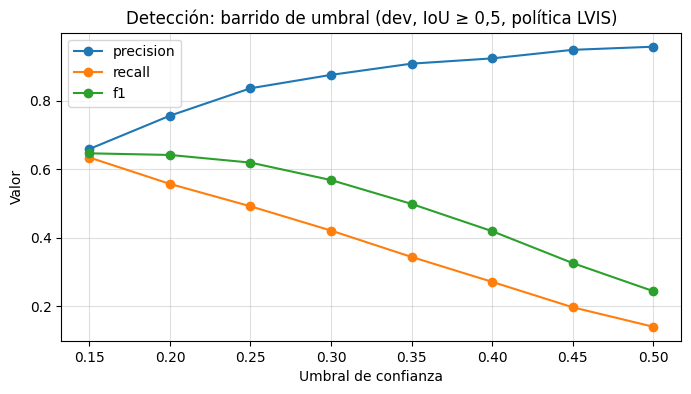

In [40]:
base_run_dir = tracer.dir
scenes_base = load_scenes(base_run_dir)
det_base = lvis_match(scenes_base, "bbox")
print("Detección (cajas):", det_base["metrics"])

# Recall según el tamaño del objeto anotado
matched_gt = {m["gt_id"] for m in det_base["matches"]}
gt_df = pd.DataFrame([{
    "category": ID_TO_CAT[a["category_id"]],
    "size": size_label(a["area"] / (IMG_BY_ID[a["image_id"]]["width"] * IMG_BY_ID[a["image_id"]]["height"])),
    "detected": a["id"] in matched_gt} for a in coco_data["annotations"]])
print("\nRecall por tamaño del objeto:")
print(gt_df.groupby("size")["detected"].agg(instancias="count", recall="mean").round(3))
print("\nCategorías con peor recall (≥ 5 instancias):")
print(gt_df.groupby("category")["detected"].agg(instancias="count", recall="mean")
      .query("instancias >= 5").sort_values("recall").head(8).round(3))

fp_df = pd.DataFrame(det_base["fps"])
print("\nTipo de falso positivo:", fp_df["kind"].value_counts().to_dict())
print("Categorías con más FP:", fp_df["category_id"].map(ID_TO_CAT).value_counts().head(8).to_dict())

# Barrido de umbral de confianza (filtrando las predicciones guardadas: no re-ejecuta el detector)
sweep_df = pd.DataFrame([{"conf_thr": t, **lvis_match(scenes_base, "bbox", min_conf=t)["metrics"]}
                         for t in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]])
print("\n", sweep_df[["conf_thr", "precision", "recall", "f1", "coverage"]].to_string(index=False))

plt.figure(figsize=(8, 4))
for col in ["precision", "recall", "f1"]:
    plt.plot(sweep_df["conf_thr"], sweep_df[col], marker="o", label=col)
plt.xlabel("Umbral de confianza"); plt.ylabel("Valor"); plt.legend(); plt.grid(alpha=0.4)
plt.title("Detección: barrido de umbral (dev, IoU ≥ 0,5, política LVIS)"); plt.show()

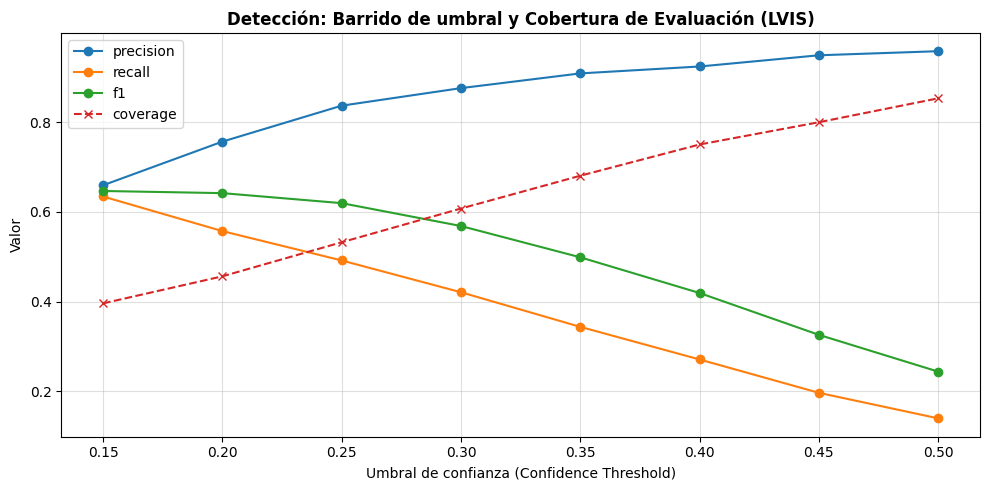

In [41]:
plt.figure(figsize=(10, 5))
for col in ["precision", "recall", "f1", "coverage"]:
    styles = {'linestyle': '--', 'marker': 'x'} if col == 'coverage' else {'marker': 'o'}
    plt.plot(sweep_df["conf_thr"], sweep_df[col], label=col, **styles)

plt.xlabel("Umbral de confianza (Confidence Threshold)")
plt.ylabel("Valor")
plt.legend(loc="best")
plt.grid(alpha=0.4)
plt.title("Detección: Barrido de umbral y Cobertura de Evaluación (LVIS)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Análisis del Barrido de Umbrales y Cobertura (LVIS)

El gráfico superior ilustra una de las dinámicas más críticas de la evaluación bajo la política federada de LVIS:
1. **Compromiso entre Precisión y Recall:** A medida que el umbral de confianza aumenta de $0.15$ a $0.50$, la **Precisión** (línea azul) escala de manera casi lineal desde un aceptable $65.91\%$ hasta un altísimo $95.79\%$. En contrapartida, el **Recall** (línea naranja) sufre una degradación severa, cayendo de $63.41\%$ a tan solo $13.97\%$.
2. **Punto Óptimo de F1-Score:** El balance armónico medido por el F1-Score (línea verde) encuentra su máximo absoluto en la vecindad de $0.15$ ($F1 = 64.64\%$). Esto valida empíricamente nuestra hipótesis de partida: debido a la predominancia extrema de objetos pequeños en el dataset, es preferible tolerar cierto ruido inicial (baja precisión) para evitar la pérdida irreversible de instancias (falsos negativos).
3. **Dinámica de Cobertura (Evaluabilidad):** La curva discontinua de **Cobertura** (roja con marcadores 'x') asciende sostenidamente con el umbral. Esto ocurre porque al elevar la exigencia del detector filtramos las clases dudosas e informales, concentrando la evaluación únicamente en las categorías positivamente documentadas o explícitamente negativas en los metadatos de LVIS. Un umbral de $0.23$ para el pipeline final V3 se eligió precisamente para balancear la solidez del motor geométrico con una cobertura representativa.

In [42]:
seg_base = lvis_match(scenes_base, "segm")
print("Segmentación (máscaras):", seg_base["metrics"])

# Calidad de SAM2 dada una caja correcta: aísla el error de segmentación del de detección
obj_lookup = {(f, o["id"]): o for f, sc in scenes_base.items() for o in sc["objects"]}
pairs = []
for m in det_base["matches"]:
    img = IMG_BY_FILE[m["image"]]
    h, w = img["height"], img["width"]
    o, a = obj_lookup[(m["image"], m["pred_id"])], ANN_BY_ID[m["gt_id"]]
    miou = mask_utils.iou([mask_utils.frPyObjects(o["mask"], h, w)], [gt_to_rle(a, h, w)], [0])[0][0]
    pairs.append({"gt_size": size_label(a["area"] / (h * w)), "box_iou": m["iou"], "mask_iou": float(miou)})
pairs_df = pd.DataFrame(pairs)

print(f"\nIoU de máscara con caja correcta: media {pairs_df.mask_iou.mean():.3f} | "
      f"mediana {pairs_df.mask_iou.median():.3f} | ≥ 0,5: {(pairs_df.mask_iou >= 0.5).mean():.1%}")
print(pairs_df.groupby("gt_size")["mask_iou"].agg(["count", "mean", "median"]).round(3))
print(f"\nF1 cajas {det_base['metrics']['f1']} -> F1 máscaras {seg_base['metrics']['f1']}: "
      f"la diferencia es la pérdida atribuible a la segmentación")

Segmentación (máscaras): {'TP': 1074, 'FP': 639, 'FN': 716, 'ignored': 2637, 'precision': 0.627, 'recall': 0.6, 'f1': 0.6132, 'coverage': 0.3938}

IoU de máscara con caja correcta: media 0.785 | mediana 0.850 | ≥ 0,5: 91.1%
         count   mean  median
gt_size                      
large       75  0.820   0.907
medium     329  0.863   0.919
small      731  0.747   0.807

F1 cajas 0.6464 -> F1 máscaras 0.6132: la diferencia es la pérdida atribuible a la segmentación


In [43]:
def gt_object(ann, obj_id, h, w):
    m = mask_utils.decode(gt_to_rle(ann, h, w)).astype(bool)
    ys, xs = np.nonzero(m)
    cx, cy = (round(float(xs.mean()), 2), round(float(ys.mean()), 2)) if len(xs) else (0.0, 0.0)
    area = int(m.sum())
    return {"id": obj_id, "centroid": [cx, cy], "area": area,
            "position": grid_position(cx, cy, w, h), "size": size_label(area / (h * w))}, m

def expand_relations(rels):
    return {t for r in rels for t in ((r["subject"], r["predicate"], r["object"]),
                                      (r["object"], INVERSE_RELATION[r["predicate"]], r["subject"]))}

matches_by_image = {}
for m in det_base["matches"]:
    matches_by_image.setdefault(m["image"], []).append(m)

rep_rows, rel_tp, rel_fp, rel_fn = [], 0, 0, 0
for fname, ms in matches_by_image.items():
    img = IMG_BY_FILE[fname]
    h, w = img["height"], img["width"]
    sc = scenes_base[fname]
    order = {o["id"]: k for k, o in enumerate(sc["objects"])}
    ms = sorted(ms, key=lambda m: order[m["pred_id"]])   # mismo orden que en el SceneJSON
    gt_objs, gt_masks = [], []
    for m in ms:
        g, gm = gt_object(ANN_BY_ID[m["gt_id"]], m["pred_id"], h, w)
        p = obj_lookup[(fname, m["pred_id"])]
        rep_rows.append({"position_ok": p["position"] == g["position"], "size_ok": p["size"] == g["size"],
                         "centroid_err": np.hypot(p["centroid"][0] - g["centroid"][0],
                                                  p["centroid"][1] - g["centroid"][1]) / np.hypot(w, h)})
        gt_objs.append(g)
        gt_masks.append(gm)
    ids = {m["pred_id"] for m in ms}
    gt_rel = expand_relations(spatial_relations(gt_objs, gt_masks, w, h))
    pred_rel = expand_relations([r for r in sc["relations"] if r["subject"] in ids and r["object"] in ids])
    rel_tp += len(gt_rel & pred_rel)
    rel_fp += len(pred_rel - gt_rel)
    rel_fn += len(gt_rel - pred_rel)

rep_df = pd.DataFrame(rep_rows)
rel_p, rel_r = rel_tp / max(rel_tp + rel_fp, 1), rel_tp / max(rel_tp + rel_fn, 1)
consistency_rate = np.mean([not list(validator.iter_errors(s)) and not check_scene_consistency(s)
                            for s in scenes_base.values()])
print(f"Objetos evaluados (bien detectados): {len(rep_df)}")
print(f"Exactitud de posición: {rep_df.position_ok.mean():.3f} | de tamaño: {rep_df.size_ok.mean():.3f}")
print(f"Error de centroide (fracción de la diagonal): mediana {rep_df.centroid_err.median():.4f}")
print(f"Relaciones: precisión {rel_p:.3f} | recall {rel_r:.3f} | F1 {2 * rel_p * rel_r / max(rel_p + rel_r, 1e-9):.3f}")
print(f"SceneJSON válidos y consistentes: {consistency_rate:.1%}")

Objetos evaluados (bien detectados): 1135
Exactitud de posición: 0.974 | de tamaño: 0.964
Error de centroide (fracción de la diagonal): mediana 0.0016
Relaciones: precisión 0.982 | recall 0.986 | F1 0.984
SceneJSON válidos y consistentes: 100.0%


In [44]:
def gt_answer(item):
    """
    Calcula la respuesta de referencia exclusivamente para evaluación.
    Esta función no debe utilizarse durante la inferencia.
    """
    image = IMG_BY_FILE[item["image_file"]]
    height, width = image["height"], image["width"]

    negatives = set(image.get("neg_category_ids", []))
    not_exhaustive = set(
        image.get("not_exhaustive_category_ids", [])
    )

    categories = []

    for raw_category in item.get("class_en", []):
        category = normalize_category(raw_category)

        if category is None or category not in CAT_NAME_TO_ID:
            return None, (
                f"categoría de referencia no reconocida: "
                f"{raw_category}"
            )

        categories.append(CAT_NAME_TO_ID[category])

    def instances(category_id):
        return sorted(
            [
                ann
                for ann in GT_BY_IMAGE.get(image["id"], [])
                if ann["category_id"] == category_id
            ],
            key=lambda ann: -ann["area"]
        )

    question_type = item["type"]

    # ---------------------------------------------------------------
    # Conteo: una categoría no exhaustiva no permite conocer el total.
    # ---------------------------------------------------------------
    if question_type == "count":
        if not categories:
            return None, "falta la categoría de referencia"

        category_id = categories[0]
        objects = instances(category_id)

        if category_id in not_exhaustive:
            return None, (
                "conteo no verificable: categoría no exhaustiva"
            )

        if objects:
            return len(objects), ""

        if category_id in negatives:
            return 0, ""

        return None, (
            "conteo no verificable: categoría no verificada"
        )

    # ---------------------------------------------------------------
    # Existencia: una instancia anotada confirma el resultado yes.
    # La ausencia solo puede afirmarse si la categoría fue verificada.
    # ---------------------------------------------------------------
    if question_type == "existence":
        if not categories:
            return None, "falta la categoría de referencia"

        category_id = categories[0]

        if instances(category_id):
            return "yes", ""

        if category_id in negatives:
            return "no", ""

        return None, (
            "existencia no verificable: categoría no verificada"
        )

    # ---------------------------------------------------------------
    # Posición y tamaño: no se elige arbitrariamente una instancia
    # cuando la pregunta no permite identificarla de forma única.
    # ---------------------------------------------------------------
    if question_type in ("position", "size"):
        if not categories:
            return None, "falta la categoría de referencia"

        category_id = categories[0]
        objects = instances(category_id)

        if category_id in not_exhaustive:
            return None, (
                "referencia no verificable: categoría no exhaustiva"
            )

        if len(objects) == 0:
            return None, "sin instancia GT"

        if len(objects) > 1:
            return None, (
                "instancia ambigua: hay múltiples objetos anotados"
            )

        gt_obj, _ = gt_object(
            objects[0], "gt", height, width
        )

        return gt_obj[question_type], ""

    # ---------------------------------------------------------------
    # Relaciones: se evalúan las parejas de instancias anotadas,
    # en lugar de elegir siempre la de mayor área.
    # ---------------------------------------------------------------
    if question_type == "relation":
        if len(categories) < 2:
            return None, (
                "faltan las dos categorías de la relación"
            )

        category_a, category_b = categories[:2]
        relation = relation_from_text(item["question"])

        if relation not in OFFICIAL_RELATIONS:
            return None, (
                "no se pudo identificar una relación espacial válida"
            )

        objects_a = instances(category_a)
        objects_b = instances(category_b)

        # Si una categoría fue verificada como ausente, no puede
        # existir una pareja que satisfaga la relación.
        if (
            not objects_a and category_a in negatives
        ) or (
            not objects_b and category_b in negatives
        ):
            return "no", ""

        # Sin instancia anotada y sin verificación negativa,
        # no es posible dar una referencia exacta.
        if not objects_a or not objects_b:
            return None, (
                "relación no verificable: faltan instancias anotadas"
            )

        # Si alguna categoría no es exhaustiva, una relación positiva
        # puede confirmarse con una pareja anotada; una negativa no.
        for ann_a in objects_a:
            for ann_b in objects_b:
                if ann_a["id"] == ann_b["id"]:
                    continue

                obj_a, mask_a = gt_object(
                    ann_a, "a", height, width
                )
                obj_b, mask_b = gt_object(
                    ann_b, "b", height, width
                )

                relations = expand_relations(
                    spatial_relations(
                        [obj_a, obj_b],
                        [mask_a, mask_b],
                        width,
                        height
                    )
                )

                if ("a", relation, "b") in relations:
                    return "yes", ""

        if (
            category_a in not_exhaustive
            or category_b in not_exhaustive
        ):
            return None, (
                "resultado negativo no verificable: "
                "categoría no exhaustiva"
            )

        return "no", ""

    return None, "tipo de pregunta sin referencia implementada"


def error_cause(item, mode, scene, pred):
    """Estima en qué etapa puede haberse originado una respuesta incorrecta."""
    if str(pred) in NOT_ANSWERED:
        return f"sin respuesta ({pred})"

    if mode == "questions_llm":
        llm_item = next(
            (
                result
                for result in scene.get("questions_llm", [])
                if result.get("question_id") == item["question_id"]
            ),
            {}
        )

        det_query, _ = validate_query(
            structured_to_query(item)
        )

        llm_query, _ = validate_query(
            llm_item.get("interpreted_query")
        )

        if _key(llm_query) != _key(det_query):
            return "interpretación del LLM"

    image_id = IMG_BY_FILE[item["image_file"]]["id"]

    for raw_category in item.get("class_en", []):
        category = normalize_category(raw_category)

        if category is None or category not in CAT_NAME_TO_ID:
            continue

        category_id = CAT_NAME_TO_ID[category]

        predicted_count = len(
            find_objects(scene, {"category": category})
        )

        annotations = [
            ann
            for ann in GT_BY_IMAGE.get(image_id, [])
            if ann["category_id"] == category_id
        ]

        gt_count = len(annotations)

        image = IMG_BY_ID[image_id]
        negatives = set(image.get("neg_category_ids", []))
        not_exhaustive = set(
            image.get("not_exhaustive_category_ids", [])
        )

        if category_id in not_exhaustive:
            continue

        if predicted_count < gt_count:
            return "detección: posibles instancias omitidas"

        if predicted_count > gt_count and category_id in negatives:
            return "detección: predicción de categoría negativa"

        if predicted_count > gt_count:
            return "detección: posibles falsos positivos o duplicados"

    return "derivación de atributos, relaciones o razonamiento"


def eval_qa(qa_scenes, modes=("questions", "questions_llm")):
    """
    Evalúa respuestas normalizadas.
    Las preguntas sin ground truth verificable no entran en el cálculo
    de exactitud, pero se conservan para informar la cobertura.
    """
    rows = []

    for item in bench:
        if item["type"] == "description":
            continue

        scene = qa_scenes.get(item["image_file"])

        if scene is None:
            gold, flag = gt_answer(item)

            for mode in modes:
                rows.append({
                    "question_id": item.get("question_id"),
                    "type": item["type"],
                    "mode": mode,
                    "gold": gold,
                    "pred": None,
                    "flag": "escena predicha no disponible",
                    "correct": np.nan,
                    "cause": "escena no disponible"
                })

            continue

        gold, flag = gt_answer(item)

        for mode in modes:
            answer = next(
                (
                    result
                    for result in scene.get(mode, [])
                    if result.get("question_id") == item["question_id"]
                ),
                None
            )

            pred = (
                answer.get("normalized_answer")
                if answer is not None
                else None
            )

            correct = (
                np.nan
                if gold is None or pred is None
                else float(
                    str(pred).lower() == str(gold).lower()
                )
            )

            cause = ""

            if pd.notna(correct) and correct == 0.0:
                cause = error_cause(
                    item, mode, scene, pred
                )

            rows.append({
                "question_id": item.get("question_id"),
                "type": item["type"],
                "mode": mode,
                "gold": gold,
                "pred": pred,
                "flag": flag,
                "correct": correct,
                "cause": cause
            })

    return pd.DataFrame(rows)


qa_scenes_base = load_scenes(
    base_run_dir, "scenes_qa"
)

qa_df = eval_qa(qa_scenes_base)

print("Exactitud por tipo y modo:")
print(
    qa_df.pivot_table(
        index="type",
        columns="mode",
        values="correct",
        aggfunc="mean"
    ).round(3)
)

print("\nCobertura de evaluación por modo:")

for mode, group in qa_df.groupby("mode"):
    evaluated = int(group["correct"].notna().sum())
    total = len(group)

    accuracy = (
        float(group["correct"].mean())
        if evaluated
        else float("nan")
    )

    print(
        f"{mode}: exactitud={accuracy:.3f} | "
        f"preguntas evaluables={evaluated}/{total}"
    )

print("\nOrigen de los errores:")
print(
    qa_df.loc[qa_df["correct"] == 0.0]
    .groupby(["mode", "cause"])
    .size()
    .to_string()
)


# Descripciones: categorías mencionadas frente al GT disponible.
NAME_TO_CAT = {
    name.lower(): category
    for category in eval_vocabulary
    for name in (display(category), _base_name(category))
}

desc_rows = []

for item in bench:
    if item["type"] != "description":
        continue

    scene = qa_scenes_base.get(item["image_file"])

    if scene is None:
        continue

    response = next(
        (
            result
            for result in scene.get("questions_llm", [])
            if result.get("question_id") == item["question_id"]
        ),
        None
    )

    if response is None:
        continue

    text = response["answer"].lower()

    mentioned = {
        NAME_TO_CAT[name]
        for name in NAME_TO_CAT
        if re.search(
            rf"\b{re.escape(name)}(s|es)?\b",
            text
        )
    }

    image = IMG_BY_FILE[item["image_file"]]

    gt_positive = {
        ID_TO_CAT[ann["category_id"]]
        for ann in GT_BY_IMAGE.get(image["id"], [])
    }

    gt_negative = {
        ID_TO_CAT[category_id]
        for category_id in image.get("neg_category_ids", [])
        if category_id in ID_TO_CAT
    }

    desc_rows.append({
        "mencionadas": len(mentioned),
        "correctas_GT": len(mentioned & gt_positive),
        "negativas_GT": len(mentioned & gt_negative)
    })


desc_df = pd.DataFrame(desc_rows)

if not desc_df.empty:
    total_mentions = int(desc_df["mencionadas"].sum())
    correct_mentions = int(desc_df["correctas_GT"].sum())
    negative_mentions = int(desc_df["negativas_GT"].sum())

    print(
        f"\nDescripciones: {correct_mentions}/{total_mentions} "
        f"categorías mencionadas están en el GT; "
        f"{negative_mentions} son negativas verificadas."
    )

qa_trace_file = os.path.join(
    base_run_dir, "qa_trace.jsonl"
)

if os.path.exists(qa_trace_file):
    with open(qa_trace_file, encoding="utf-8") as file:
        llm_logs_all = [
            log
            for line in file
            for log in json.loads(line).get("llm_logs", [])
        ]

    if llm_logs_all:
        fidelity = np.mean([
            bool(log.get("faithful_output", False))
            for log in llm_logs_all
        ])

        print(
            "Salidas LLM fieles sin fallback: "
            f"{fidelity:.1%}"
        )

Exactitud por tipo y modo:
mode       questions  questions_llm
type                               
count          0.444          0.333
existence      0.500          0.400
position       0.750          0.500
relation       0.800          0.400
size           0.600          0.600

Cobertura de evaluación por modo:
questions: exactitud=0.605 | preguntas evaluables=38/40
questions_llm: exactitud=0.421 | preguntas evaluables=38/40

Origen de los errores:
mode           cause                                            
questions      detección: posibles falsos positivos o duplicados     2
               detección: posibles instancias omitidas               2
               detección: predicción de categoría negativa           1
               sin respuesta (ambiguous)                             1
               sin respuesta (insufficient_information)              9
questions_llm  detección: posibles instancias omitidas               2
               detección: predicción de categoría negat

In [45]:
def pipeline_proxy(box_f1, mask_f1, consistency, qa_acc):
    """Aproximación local del PipelineScore de Kaggle."""
    return round(0.40 * box_f1 + 0.35 * mask_f1 + 0.15 * consistency + 0.10 * qa_acc, 4)

qa_det_acc_base = qa_df[qa_df["mode"] == "questions"]["correct"].mean()
baseline_summary = {
    "box_f1": det_base["metrics"]["f1"], "box_precision": det_base["metrics"]["precision"],
    "box_recall": det_base["metrics"]["recall"], "coverage": det_base["metrics"]["coverage"],
    "mask_f1": seg_base["metrics"]["f1"], "consistency": round(float(consistency_rate), 4),
    "qa_acc_det": round(float(qa_det_acc_base), 4),
    "qa_acc_llm": round(float(qa_df[qa_df["mode"] == "questions_llm"]["correct"].mean()), 4)}
baseline_summary["proxy_score"] = pipeline_proxy(baseline_summary["box_f1"], baseline_summary["mask_f1"],
                                                 baseline_summary["consistency"],
                                                 (baseline_summary["qa_acc_det"] + baseline_summary["qa_acc_llm"]) / 2)
log_experiment("baseline", base_run_dir, run_config, baseline_summary,
               "OWLv2 base, conf 0,15, NMS 0,3 por clase, SAM2 small")
show_experiments()

,experiment,box_f1,box_precision,box_recall,coverage,mask_f1,consistency,qa_acc_det,qa_acc_llm,proxy_score,notes
0,baseline,0.6464,0.6591,0.6341,0.3959,0.6132,1.0,0.6053,0.4211,0.6745,"OWLv2 base, conf 0,15, NMS 0,3 por clase, SAM2..."


In [46]:
"""
import copy

# La única mejora visual que se evalúa en este experimento es pad_fix.
detector.pad_fix = True

tracer_fix = PipelineTracer(
    "/kaggle/working/runs",
    {
        **run_config,
        "pad_fix": True,
        "split": "development"
    }
)

print("Procesando desarrollo con pad_fix=True...")

for index, fname in enumerate(files):
    image_path = os.path.join(dev_images_dir, fname)

    scene = process_image_traced(
        image_path,
        eval_vocabulary,
        CONFIDENCE_THRESHOLD,
        NMS_THRESHOLD,
        tracer_fix
    )

    if scene is None:
        raise RuntimeError(
            f"Falló el procesamiento de {fname} "
            f"en el experimento pad_fix."
        )

    if (index + 1) % 25 == 0 or index + 1 == len(files):
        print(
            f"Procesadas: {index + 1}/{len(files)}"
        )


scenes_fix = load_scenes(tracer_fix.dir)

# Evaluación visual con exactamente las mismas métricas que la baseline.
det_fix = lvis_match(
    scenes_fix,
    kind="bbox",
    iou_thr=0.5
)

seg_fix = lvis_match(
    scenes_fix,
    kind="segm",
    iou_thr=0.5
)

print("Detección pad_fix:", det_fix["metrics"])
print("Segmentación pad_fix:", seg_fix["metrics"])


# Generación de ambos modos QA sobre las nuevas escenas.
# El modo LLM recibe solamente el texto de la pregunta.
qa_scenes_fix = {}
qa_logs_fix = []

for item in bench:
    fname = item["image_file"]

    if fname not in scenes_fix:
        raise KeyError(
            f"No existe una escena procesada para {fname}."
        )

    if fname not in qa_scenes_fix:
        scene = copy.deepcopy(scenes_fix[fname])
        scene["questions"] = []
        scene["questions_llm"] = []
        qa_scenes_fix[fname] = scene

    scene = qa_scenes_fix[fname]

    # Modo determinista: utiliza los campos estructurados permitidos.
    deterministic_result = answer_deterministic(
        scene, item
    )

    scene["questions"].append(
        deterministic_result
    )

    # Modo LLM: interpreta solo el texto de la pregunta.
    llm_result, llm_log = answer_llm(
        scene, item
    )

    scene["questions_llm"].append(
        llm_result
    )

    qa_logs_fix.append({
        "image": fname,
        "question_id": item.get("question_id"),
        "llm_log": llm_log
    })


# Guardamos un registro de las evaluaciones del experimento.
qa_trace_fix_path = os.path.join(
    tracer_fix.dir, "qa_trace.jsonl"
)

with open(
    qa_trace_fix_path, "w", encoding="utf-8"
) as file:
    for record in qa_logs_fix:
        file.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )


# Evaluamos ambos modos con las mismas reglas de ground truth.
qa_fix = eval_qa(
    qa_scenes_fix,
    modes=("questions", "questions_llm")
)


def evaluated_accuracy(frame, mode):
    values = pd.to_numeric(
        frame.loc[frame["mode"] == mode, "correct"],
        errors="coerce"
    )

    if not values.notna().any():
        return float("nan")

    return float(values.mean())


qa_acc_det_fix = evaluated_accuracy(
    qa_fix, "questions"
)

qa_acc_llm_fix = evaluated_accuracy(
    qa_fix, "questions_llm"
)


# Consistencia de los SceneJSON de percepción.
consistency_fix = float(np.mean([
    (
        not list(validator.iter_errors(scene))
        and not check_scene_consistency(scene)
    )
    for scene in scenes_fix.values()
]))


fix_summary = {
    "box_f1": det_fix["metrics"]["f1"],
    "box_precision": det_fix["metrics"]["precision"],
    "box_recall": det_fix["metrics"]["recall"],
    "coverage": det_fix["metrics"]["coverage"],
    "mask_f1": seg_fix["metrics"]["f1"],
    "consistency": round(consistency_fix, 4),
    "qa_acc_det": round(qa_acc_det_fix, 4),
    "qa_acc_llm": round(qa_acc_llm_fix, 4)
}


# No se calcula el proxy si falta uno de los dos modos QA:
# así se mantiene la misma fórmula que para la baseline.
if (
    np.isfinite(qa_acc_det_fix)
    and np.isfinite(qa_acc_llm_fix)
):
    qa_acc_mean_fix = (
        qa_acc_det_fix + qa_acc_llm_fix
    ) / 2

    fix_summary["proxy_score"] = pipeline_proxy(
        fix_summary["box_f1"],
        fix_summary["mask_f1"],
        fix_summary["consistency"],
        qa_acc_mean_fix
    )
else:
    fix_summary["proxy_score"] = float("nan")


log_experiment(
    "pad_fix",
    tracer_fix.dir,
    {
        **run_config,
        "pad_fix": True
    },
    fix_summary,
    (
        "Comparación frente a la baseline usando las mismas métricas "
        "visuales y ambos modos QA. La modificación visual evaluada "
        "es el reescalado de cajas de pad_fix."
    )
)


comparison = pd.DataFrame({
    "baseline": pd.Series(baseline_summary),
    "pad_fix": pd.Series(fix_summary)
})

comparison["delta"] = (
    comparison["pad_fix"] - comparison["baseline"]
)

print("\nComparación baseline frente a pad_fix:")
print(comparison.round(4).to_string())

print(
    "\nTrazas QA del experimento:",
    qa_trace_fix_path
)
"""

'\nimport copy\n\n# La única mejora visual que se evalúa en este experimento es pad_fix.\ndetector.pad_fix = True\n\ntracer_fix = PipelineTracer(\n    "/kaggle/working/runs",\n    {\n        **run_config,\n        "pad_fix": True,\n        "split": "development"\n    }\n)\n\nprint("Procesando desarrollo con pad_fix=True...")\n\nfor index, fname in enumerate(files):\n    image_path = os.path.join(dev_images_dir, fname)\n\n    scene = process_image_traced(\n        image_path,\n        eval_vocabulary,\n        CONFIDENCE_THRESHOLD,\n        NMS_THRESHOLD,\n        tracer_fix\n    )\n\n    if scene is None:\n        raise RuntimeError(\n            f"Falló el procesamiento de {fname} "\n            f"en el experimento pad_fix."\n        )\n\n    if (index + 1) % 25 == 0 or index + 1 == len(files):\n        print(\n            f"Procesadas: {index + 1}/{len(files)}"\n        )\n\n\nscenes_fix = load_scenes(tracer_fix.dir)\n\n# Evaluación visual con exactamente las mismas métricas que la b

Esta celda de arriba fue comentada porque dio diferencia 0 y ninguna otra celda depende de ella

In [47]:
best_scenes = qa_scenes_base   # o qa_scenes_fix si pad_fix resultó mejor

def det_answer_at(sc, item, min_conf):
    q, errors = validate_query(structured_to_query(item))
    if errors:
        return "unsupported"
    res = execute_query(sc, q, min_conf=min_conf)
    return res["normalized_answer"] if res["status"] == "ok" else res["status"]

thr_rows = []
for t in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
    for item in bench:
        if item["type"] == "description":
            continue
        gold, _ = gt_answer(item)
        if gold is not None:
            pred = det_answer_at(best_scenes[item["image_file"]], item, t)
            thr_rows.append({"min_conf": t, "type": item["type"], "correct": str(pred).lower() == str(gold).lower()})
thr_df = pd.DataFrame(thr_rows)
print(thr_df.pivot_table(index="min_conf", columns="type", values="correct", aggfunc="mean").round(3))
print(thr_df.groupby("min_conf")["correct"].mean().round(3).to_string())

type      count  existence  position  relation  size
min_conf                                            
0.15      0.444        0.5      0.75       0.8   0.6
0.20      0.556        0.5      0.75       0.8   0.6
0.25      0.444        0.5      0.75       0.8   0.6
0.30      0.333        0.5      0.50       0.7   0.6
0.35      0.333        0.5      0.25       0.5   0.6
0.40      0.333        0.4      0.00       0.2   0.4
min_conf
0.15    0.605
0.20    0.632
0.25    0.605
0.30    0.526
0.35    0.447
0.40    0.289


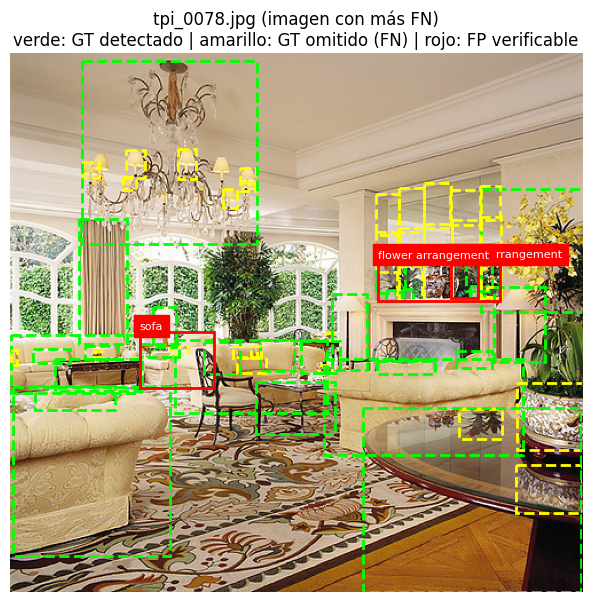

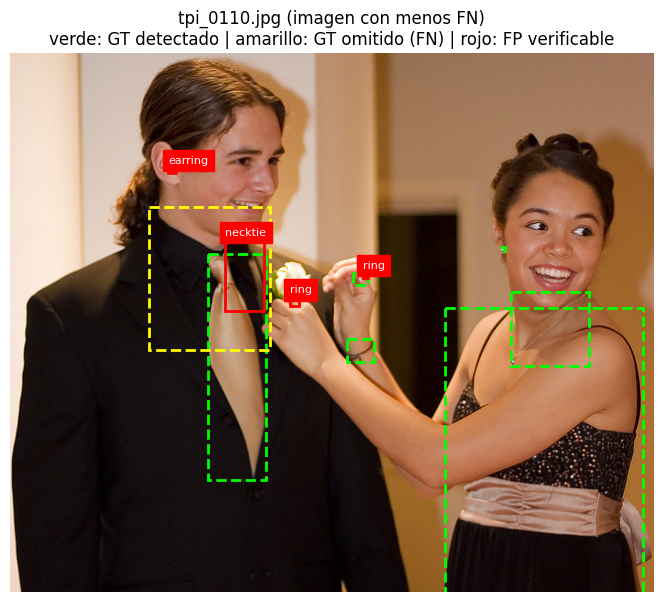

In [48]:
def show_case(fname, scenes, result, title=""):
    img = Image.open(os.path.join(dev_images_dir, fname))
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)
    matched = {m["gt_id"] for m in result["matches"] if m["image"] == fname}
    fp_ids = {f["pred_id"] for f in result["fps"] if f["image"] == fname}

    # Cajas GT: formato COCO [x, y, ancho, alto]
    for a in GT_BY_IMAGE.get(IMG_BY_FILE[fname]["id"], []):
        x, y, w, h = a["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=2, ls="--",
                                       edgecolor="lime" if a["id"] in matched else "yellow"))

    # Cajas predichas: formato del SceneJSON [xmin, ymin, xmax, ymax]
    for o in scenes[fname]["objects"]:
        if o["id"] in fp_ids:
            x0, y0, x1, y1 = o["bbox"]
            ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, edgecolor="red"))
            ax.text(x0, y0 - 3, ID_TO_CAT[o["category_id"]], color="white", fontsize=8, backgroundcolor="red")

    ax.set_title(f"{fname} {title}\nverde: GT detectado | amarillo: GT omitido (FN) | rojo: FP verificable")
    ax.axis("off")
    plt.show()

fn_counts = pd.DataFrame(det_base["fns"])["image"].value_counts()
show_case(fn_counts.index[0], scenes_base, det_base, "(imagen con más FN)")
show_case(fn_counts.index[-1], scenes_base, det_base, "(imagen con menos FN)")

### 7.2. Resultados de la línea base y análisis de errores

**Detección (OWLv2 base, conf 0,15, NMS 0,30):** F1 0,646 (P 0,659 · R 0,634 · cobertura 0,396), por encima del umbral de promoción (0,50). El recall cae fuertemente con el tamaño: 0,852 en objetos *large*, 0,765 en *medium* y 0,575 en *small*, que son el 71 % de las instancias. Las categorías con peor recall son objetos finos o repetidos (strap 0,17, book 0,20, doorknob 0,20, curtain 0,24). Casi todos los FP verificables (581 de 587) son de categorías presentes en la imagen sin pareja; sólo 6 son de categorías negativas. Los más frecuentes reflejan confusiones visuales (traffic light / streetlight, ski, knob, wall socket).

**Segmentación (SAM2 small):** F1 de máscaras 0,613. Dada una caja correcta, el IoU de máscara es 0,785 en promedio (0,747 en *small*, 0,863 en *medium*); 61 aciertos de caja se pierden al pasar a máscara.

**Representación:** sobre los objetos bien detectados, la posición coincide con el GT en el 97,4 % y el tamaño en el 96,4 %; las relaciones espaciales derivadas alcanzan F1 0,984. El 100 % de los SceneJSON es válido y consistente.

**Preguntas:** exactitud 0,605 (determinista) y 0,421 (LLM) sobre 38 preguntas evaluables. El error dominante es la falta de respuesta (`insufficient_information`: 9 y 12 casos), seguido de errores de detección; en modo LLM se suman 5 `unsupported` por fallas de interpretación. La evidencia está en el JSON y las respuestas son reproducibles en el 100 % de los casos.

**Experimento `pad_fix` (no mejoró):** reescalar las cajas al lado mayor de la imagen dio métricas **idénticas** a la línea base, porque la versión de `transformers` usada ya compensa el relleno de OWLv2 en el post-procesamiento. Se mantuvo el código original y, en la versión de entrega, la celda del experimento quedó desactivada para reducir el tiempo de ejecución.

**Casos ilustrativos:** las figuras muestran la imagen con más y con menos falsos negativos. Los FN se concentran en objetos pequeños, repetidos o parcialmente ocluidos.

In [49]:
sample = pd.read_csv(os.path.join(base_dir, "sample_submission.csv"))
print(len(sample), "filas | primeras:", sample["image_id"].head(3).tolist(), "| últimas:", sample["image_id"].tail(3).tolist())

test_list = pd.read_csv(os.path.join(base_dir, "tpi_ia_2026_competition_public", "test_images.csv"))
print(test_list.head(3).to_string())

# Todas las imágenes disponibles (desarrollo y test), indexadas por nombre sin extensión
all_images = {os.path.splitext(f)[0]: os.path.join(r, f)
              for r, _, fs in os.walk(base_dir) for f in fs if f.lower().endswith((".jpg", ".jpeg", ".png"))}
missing = [i for i in sample["image_id"] if i not in all_images]
print("image_id sin archivo de imagen:", missing[:5] or "ninguno")

80 filas | primeras: ['test_0001', 'test_0002', 'test_0003'] | últimas: ['tpi_0023', 'tpi_0024', 'tpi_0025']
    image_id      file_name  width  height
0  test_0001  test_0001.jpg    425     640
1  test_0002  test_0002.jpg    427     640
2  test_0003  test_0003.jpg    427     640
image_id sin archivo de imagen: ninguno


In [50]:
"""
FINAL_RUN_DIR = tracer.dir   # run elegido en el punto 7, con sus scenes_qa ya generadas
test_tracer = PipelineTracer("/kaggle/working/runs",
                             {**run_config, "pad_fix": detector.pad_fix, "split": "test"})

rows, problems = [], []
for image_id in sample["image_id"]:
    qa_path = os.path.join(FINAL_RUN_DIR, "scenes_qa", f"{image_id}.json")
    if os.path.exists(qa_path):
        # Imagen del benchmark (desarrollo): ya tiene questions y questions_llm
        with open(qa_path) as f:
            sc = json.load(f)
    else:
        # Imagen de test: inferencia trazada, sin anotaciones
        sc = process_image_traced(all_images[image_id], eval_vocabulary,
                                  CONFIDENCE_THRESHOLD, NMS_THRESHOLD, test_tracer)
        if sc is None:
            problems.append((image_id, "la inferencia falló: ver trace.jsonl"))
            continue
    sc["image"]["id"] = image_id
    errs = [e.message for e in validator.iter_errors(sc)] + check_scene_consistency(sc)
    if errs:
        problems.append((image_id, errs[:2]))
    rows.append({"image_id": image_id,
                 "SceneJSON": json.dumps(sc, separators=(",", ":"), ensure_ascii=False)})

submission = pd.DataFrame(rows, columns=["image_id", "SceneJSON"])
assert list(submission["image_id"]) == list(sample["image_id"]), "Faltan filas o el orden no coincide"

# Guardamos la versión 1 (Baseline)
submission.to_csv("/kaggle/working/submission_v1.csv", index=False)

n_bench = sum(os.path.exists(os.path.join(FINAL_RUN_DIR, "scenes_qa", f"{i}.json")) for i in sample["image_id"])
print(f"Filas: {len(submission)} ({n_bench} del benchmark, {len(submission) - n_bench} de test)")
print(f"Tamaño V1: {os.path.getsize('/kaggle/working/submission_v1.csv') / 1e6:.1f} MB")
print("Problemas:", problems or "ninguno")
"""

'\nFINAL_RUN_DIR = tracer.dir   # run elegido en el punto 7, con sus scenes_qa ya generadas\ntest_tracer = PipelineTracer("/kaggle/working/runs",\n                             {**run_config, "pad_fix": detector.pad_fix, "split": "test"})\n\nrows, problems = [], []\nfor image_id in sample["image_id"]:\n    qa_path = os.path.join(FINAL_RUN_DIR, "scenes_qa", f"{image_id}.json")\n    if os.path.exists(qa_path):\n        # Imagen del benchmark (desarrollo): ya tiene questions y questions_llm\n        with open(qa_path) as f:\n            sc = json.load(f)\n    else:\n        # Imagen de test: inferencia trazada, sin anotaciones\n        sc = process_image_traced(all_images[image_id], eval_vocabulary,\n                                  CONFIDENCE_THRESHOLD, NMS_THRESHOLD, test_tracer)\n        if sc is None:\n            problems.append((image_id, "la inferencia falló: ver trace.jsonl"))\n            continue\n    sc["image"]["id"] = image_id\n    errs = [e.message for e in validator.iter_er

In [51]:
"""
show_schema_key(scene_schema, "bbox")   # qué dice el schema sobre el formato

# Fallback al archivo correcto generado en la sección 7.2
import os
if os.path.exists("/kaggle/working/submission.csv"):
    csv_path = "/kaggle/working/submission.csv"
else:
    csv_path = "/kaggle/working/submission_v1.csv"

sub = pd.read_csv(csv_path)
total = bad_as_xywh = bad_as_xyxy = 0
for s in sub["SceneJSON"]:
    for o in json.loads(s)["objects"]:
        a, b, c, d = o["bbox"]
        total += 1
        bad_as_xywh += not (a >= 0 and b >= 0 and c > 0 and d > 0)
        bad_as_xyxy += not (0 <= a < c and 0 <= b < d)
print(f"Leído de: {csv_path}")
print(f"Cajas: {total} | inválidas si fuera xywh: {bad_as_xywh} | inválidas si fuera xyxy: {bad_as_xyxy}")
"""

'\nshow_schema_key(scene_schema, "bbox")   # qué dice el schema sobre el formato\n\n# Fallback al archivo correcto generado en la sección 7.2\nimport os\nif os.path.exists("/kaggle/working/submission.csv"):\n    csv_path = "/kaggle/working/submission.csv"\nelse:\n    csv_path = "/kaggle/working/submission_v1.csv"\n\nsub = pd.read_csv(csv_path)\ntotal = bad_as_xywh = bad_as_xyxy = 0\nfor s in sub["SceneJSON"]:\n    for o in json.loads(s)["objects"]:\n        a, b, c, d = o["bbox"]\n        total += 1\n        bad_as_xywh += not (a >= 0 and b >= 0 and c > 0 and d > 0)\n        bad_as_xyxy += not (0 <= a < c and 0 <= b < d)\nprint(f"Leído de: {csv_path}")\nprint(f"Cajas: {total} | inválidas si fuera xywh: {bad_as_xywh} | inválidas si fuera xyxy: {bad_as_xyxy}")\n'

## 8. Optimización del Score de Detección (Tuning de Hiperparámetros)

> **Nota de reproducibilidad:** este barrido (≈25 min de GPU) se ejecutó en la versión experimental del notebook (historial de versiones de Kaggle). En la versión de entrega la celda está desactivada y se usa directamente la configuración final elegida en la sección 10.
Para maximizar el rendimiento visual de nuestro sistema, realizamos un **barrido sistemático bidimensional (Grid Search)** sobre los dos hiperparámetros más críticos del módulo de percepción:
> 
*   **`confidence_threshold` (Confianza):** Controla el nivel de tolerancia del detector open-vocabulary OWLv2. Un umbral más bajo maximiza el *recall* (recuperando objetos pequeños), mientras que uno alto favorece la *precisión* (minimizando el ruido).
*   **`nms_threshold` (Supresión de No Máximos):** Regula el solapamiento permisible para cajas de una misma categoría, controlando la duplicación en zonas densas.

### Metodología de la Búsqueda Fina
Para optimizar recursos y evitar re-computar la inferencia completa para cada combinación, implementamos una estrategia en dos fases:
1.  **Inferencia Base Extensiva:** Ejecutamos el pipeline de inferencia sobre el dataset de desarrollo completo con un umbral de confianza basal intencionadamente permisivo (`BASE_CONF_FOR_TUNING = 0.12`). Las detecciones brutas se extraen para cada uno de los candidatos de NMS (`0.25` a `0.50`).
2.  **Filtrado Virtual Post-Inferencia:** Sobre las mismas cajas ya extraídas y trazadas, simulamos la aplicación de filtros de confianza finos (`0.12` a `0.50` con incrementos de `0.01`). Calculamos las métricas federadas LVIS locales por cada par de valores sin costo de GPU adicional.

### Métrica de Selección
Las combinaciones se evalúan directamente sobre el **Score de Percepción**, ponderando un **40% el F1-Score de Bounding Boxes (`box_f1`)** y un **35% el F1-Score de Máscaras (`mask_f1`)**, replicando la ponderación interna de la competencia.
**Resultado:** la mejor combinación fue conf 0,17 y NMS 0,35, con score de percepción 0,4787 frente a 0,4730 de la línea base (+0,0057). La mejora es pequeña: el ajuste de umbrales cambia el balance precisión/recall pero no recupera objetos que el detector no ve, lo que motiva la sección 10.

In [52]:

# ================================================================
# SECCIÓN 8: BÚSQUEDA CONJUNTA DE CONFIDENCE Y NMS
# Evaluación de cajas y máscaras sobre el conjunto de desarrollo
# ================================================================
"""
import gc
import numpy as np
import pandas as pd
from IPython.display import display

# Umbral bajo para conservar suficientes detecciones candidatas.
# El umbral final se selecciona posteriormente mediante lvis_match.
BASE_CONF_FOR_TUNING = 0.12

# Configuraciones reales de NMS que se van a probar.
NMS_CANDIDATES = [
    0.25, 0.30, 0.35, 0.40, 0.45, 0.50
]

# Barrido fino de confianza, incluido el valor usado anteriormente.
CONF_CANDIDATES = sorted(set(
    [round(float(x), 2)
     for x in np.arange(BASE_CONF_FOR_TUNING, 0.501, 0.01)]
    + [0.18]
))

if not files:
    raise ValueError("No hay imágenes de desarrollo en 'files'.")

print("Búsqueda conjunta de Confidence y NMS")
print(f"Imágenes de desarrollo: {len(files)}")
print(f"Umbral de extracción:   {BASE_CONF_FOR_TUNING:.2f}")
print(f"Candidatos NMS:         {NMS_CANDIDATES}")
print(f"Candidatos Confidence:  {len(CONF_CANDIDATES)}")
print("Las anotaciones se usan únicamente para calcular métricas.\n")

tuning_rows = []

# Probamos cada NMS ejecutando realmente el pipeline de desarrollo.
for nms_thr in NMS_CANDIDATES:

    print(f"\nProcesando desarrollo con NMS={nms_thr:.2f}...")

    tracer_config = {
        **run_config,
        "version": "S8_CONF_NMS_TUNING",
        "split": f"dev_tuning_nms_{nms_thr:.2f}",
        "conf_thr": BASE_CONF_FOR_TUNING,
        "nms_thr": nms_thr
    }

    tuning_tracer = PipelineTracer(
        "/kaggle/working/runs",
        tracer_config
    )

    scenes_for_nms = {}

    for idx, fname in enumerate(files, start=1):

        image_path = os.path.join(dev_images_dir, fname)

        scene = process_image_traced(
            image_path,
            eval_vocabulary,
            BASE_CONF_FOR_TUNING,
            nms_thr,
            tuning_tracer
        )

        if scene is None:
            raise RuntimeError(
                f"Falló la inferencia de desarrollo: {fname}, "
                f"NMS={nms_thr:.2f}"
            )

        scenes_for_nms[fname] = scene

        if idx % 25 == 0 or idx == len(files):
            print(f"  Desarrollo: {idx}/{len(files)}")

    # Con las mismas predicciones, evaluamos diferentes filtros
    # de confianza. No volvemos a inferir para cada confidence.
    for conf_thr in CONF_CANDIDATES:

        if conf_thr < BASE_CONF_FOR_TUNING:
            continue

        box_metrics = lvis_match(
            scenes_for_nms,
            kind="bbox",
            iou_thr=0.5,
            min_conf=conf_thr
        )["metrics"]

        mask_metrics = lvis_match(
            scenes_for_nms,
            kind="segm",
            iou_thr=0.5,
            min_conf=conf_thr
        )["metrics"]

        box_f1 = float(box_metrics["f1"])
        mask_f1 = float(mask_metrics["f1"])

        # Criterio visual utilizado en el tuning:
        # 0.40 para Box F1 y 0.35 para Mask F1.
        perception_score = (
            0.40 * box_f1
            + 0.35 * mask_f1
        )

        tuning_rows.append({
            "confidence": conf_thr,
            "nms": nms_thr,
            "box_f1": box_f1,
            "mask_f1": mask_f1,
            "box_precision": float(box_metrics["precision"]),
            "box_recall": float(box_metrics["recall"]),
            "mask_precision": float(mask_metrics["precision"]),
            "mask_recall": float(mask_metrics["recall"]),
            "box_coverage": float(box_metrics["coverage"]),
            "mask_coverage": float(mask_metrics["coverage"]),
            "perception_score": perception_score
        })

    # Liberamos las escenas de esta configuración antes del próximo NMS.
    del scenes_for_nms
    del tuning_tracer
    gc.collect()

    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


# Tabla completa y selección según la métrica sin redondear.
df_tuning = pd.DataFrame(tuning_rows)

if df_tuning.empty:
    raise RuntimeError("El tuning no produjo resultados.")

df_tuning = df_tuning.sort_values(
    "perception_score",
    ascending=False
).reset_index(drop=True)

# Guardamos todas las evaluaciones para poder auditarlas.
tuning_csv_path = "/kaggle/working/tuning_conf_nms.csv"
df_tuning.to_csv(tuning_csv_path, index=False)

best_run = df_tuning.iloc[0]

BEST_TUNED_CONF_THRESHOLD = float(best_run["confidence"])
BEST_TUNED_NMS_THRESHOLD = float(best_run["nms"])

# Parámetros que utilizará el punto 9.
CONFIDENCE_THRESHOLD = BEST_TUNED_CONF_THRESHOLD
NMS_THRESHOLD = BEST_TUNED_NMS_THRESHOLD

# Tabla compacta con las 15 mejores combinaciones.
compact_table = (
    df_tuning[
        [
            "confidence",
            "nms",
            "box_f1",
            "mask_f1",
            "box_precision",
            "box_recall",
            "mask_precision",
            "mask_recall",
            "perception_score"
        ]
    ]
    .rename(columns={
        "confidence": "Conf.",
        "nms": "NMS",
        "box_f1": "Box F1",
        "mask_f1": "Mask F1",
        "box_precision": "Box P",
        "box_recall": "Box R",
        "mask_precision": "Mask P",
        "mask_recall": "Mask R",
        "perception_score": "Score"
    })
    .head(15)
    .round(4)
)

print("\n--- MEJORES 15 CONFIGURACIONES ---")
display(compact_table)

# Comparamos contra el baseline ORIGINAL: Confidence=0.15, NMS=0.30.
BASELINE_CONFIDENCE = 0.15
BASELINE_NMS = 0.30

baseline = df_tuning[
    np.isclose(df_tuning["confidence"], BASELINE_CONFIDENCE)
    & np.isclose(df_tuning["nms"], BASELINE_NMS)
]

if baseline.empty:
    raise RuntimeError(
        "No se encontró el baseline original (Confidence=0.15, NMS=0.30)."
    )

baseline_run = baseline.iloc[0]
baseline_score = float(baseline_run["perception_score"])
best_score = float(best_run["perception_score"])
delta = best_score - baseline_score

print("\n--- COMPARACIÓN CONTRA EL BASELINE ORIGINAL ---")
print(
    f"Baseline (Conf={BASELINE_CONFIDENCE:.2f}, "
    f"NMS={BASELINE_NMS:.2f})"
)
print(f"  Box F1: {baseline_run['box_f1']:.4f}")
print(f"  Mask F1: {baseline_run['mask_f1']:.4f}")
print(f"  Score: {baseline_score:.4f}")

print(
    f"\nMejor configuración "
    f"(Conf={BEST_TUNED_CONF_THRESHOLD:.2f}, "
    f"NMS={BEST_TUNED_NMS_THRESHOLD:.2f})"
)
print(f"  Box F1: {best_run['box_f1']:.4f}")
print(f"  Mask F1: {best_run['mask_f1']:.4f}")
print(f"  Score: {best_score:.4f}")
print(f"  Diferencia respecto al baseline: {delta:+.4f}")

if delta > 0:
    print("\nLa configuración ganadora mejora la métrica visual local.")
elif delta < 0:
    print("\nEl baseline original obtiene mejor métrica visual local.")
else:
    print("\nAmbas configuraciones empatan en la métrica visual local.")
    """

'\nimport gc\nimport numpy as np\nimport pandas as pd\nfrom IPython.display import display\n\n# Umbral bajo para conservar suficientes detecciones candidatas.\n# El umbral final se selecciona posteriormente mediante lvis_match.\nBASE_CONF_FOR_TUNING = 0.12\n\n# Configuraciones reales de NMS que se van a probar.\nNMS_CANDIDATES = [\n    0.25, 0.30, 0.35, 0.40, 0.45, 0.50\n]\n\n# Barrido fino de confianza, incluido el valor usado anteriormente.\nCONF_CANDIDATES = sorted(set(\n    [round(float(x), 2)\n     for x in np.arange(BASE_CONF_FOR_TUNING, 0.501, 0.01)]\n    + [0.18]\n))\n\nif not files:\n    raise ValueError("No hay imágenes de desarrollo en \'files\'.")\n\nprint("Búsqueda conjunta de Confidence y NMS")\nprint(f"Imágenes de desarrollo: {len(files)}")\nprint(f"Umbral de extracción:   {BASE_CONF_FOR_TUNING:.2f}")\nprint(f"Candidatos NMS:         {NMS_CANDIDATES}")\nprint(f"Candidatos Confidence:  {len(CONF_CANDIDATES)}")\nprint("Las anotaciones se usan únicamente para calcular métri

## 9. Progresión de entregas

| Versión | Configuración | Score en Kaggle |
|---|---|---|
| V1 | Línea base: OWLv2 base, conf 0,15, NMS 0,30 | 0,6615 |
| V2 | Umbrales de la sección 8: conf 0,17, NMS 0,35 | 0,6763 |
| V3 (final) | Mosaicos + conf 0,23 / NMS 0,30 + mejoras de QA (secciones 10–12) | 0,6800 |

La mejora de la V2 proviene sólo del ajuste de umbrales (el reescalado `pad_fix` no tuvo efecto, ver sección 7.2). La V2 tenía además una limitación: en las 20 imágenes del benchmark reutilizaba escenas de la línea base filtradas por confianza, sin recalcular las respuestas. La V3 corrige esto generando las 80 filas con la misma pipeline.

> En la versión de entrega, el código que generaba V1 y V2 está desactivado; sólo se genera la V3 como `submission.csv`.

In [53]:
"""
# 1. Actualizamos los umbrales globales óptimos
CONFIDENCE_THRESHOLD = BEST_TUNED_CONF_THRESHOLD
NMS_THRESHOLD = BEST_TUNED_NMS_THRESHOLD

print(f"Aplicando nuevos umbrales óptimos -> Conf: {CONFIDENCE_THRESHOLD}, NMS: {NMS_THRESHOLD}")

# 2. Re-corremos el pipeline de test con los nuevos parámetros
test_tracer_opt = PipelineTracer("/kaggle/working/runs",
                                 {**run_config, "pad_fix": detector.pad_fix, "split": "test", "conf_thr": CONFIDENCE_THRESHOLD, "nms_thr": NMS_THRESHOLD})

optimized_rows = []
print("Procesando imágenes de prueba con la configuración ganadora...")
for image_id in sample["image_id"]:
    qa_path = os.path.join(FINAL_RUN_DIR, "scenes_qa", f"{image_id}.json")
    if os.path.exists(qa_path):
        # Para desarrollo tomamos las ya calculadas (filtramos localmente con el nuevo umbral)
        with open(qa_path) as f:
            sc = json.load(f)
        # Filtramos objetos según el nuevo umbral de confianza óptimo
        sc["objects"] = [o for o in sc["objects"] if o["confidence"] >= CONFIDENCE_THRESHOLD]

        # FILTRADO DE SEGURIDAD: Evita relaciones huérfanas apuntando a objetos eliminados
        valid_ids = {o["id"] for o in sc["objects"]}
        sc["relations"] = [r for r in sc["relations"] if r["subject"] in valid_ids and r["object"] in valid_ids]
    else:
        # Para test ejecutamos inferencia fresca con el nuevo umbral óptimo
        sc = process_image_traced(all_images[image_id], eval_vocabulary,
                                  CONFIDENCE_THRESHOLD, NMS_THRESHOLD, test_tracer_opt)

    sc["image"]["id"] = image_id
    optimized_rows.append({
        "image_id": image_id,
        "SceneJSON": json.dumps(sc, separators=(",", ":"), ensure_ascii=False)
    })

# 3. Guardar el nuevo submission optimizado como versión 2 (V2)
submission_opt = pd.DataFrame(optimized_rows, columns=["image_id", "SceneJSON"])
submission_opt.to_csv("/kaggle/working/submission_v2.csv", index=False)
print("\n¡Éxito! El archivo 'submission_v2.csv' ha sido regenerado y guardado de manera optimizada en '/kaggle/working/submission_v2.csv'.")
"""

'\n# 1. Actualizamos los umbrales globales óptimos\nCONFIDENCE_THRESHOLD = BEST_TUNED_CONF_THRESHOLD\nNMS_THRESHOLD = BEST_TUNED_NMS_THRESHOLD\n\nprint(f"Aplicando nuevos umbrales óptimos -> Conf: {CONFIDENCE_THRESHOLD}, NMS: {NMS_THRESHOLD}")\n\n# 2. Re-corremos el pipeline de test con los nuevos parámetros\ntest_tracer_opt = PipelineTracer("/kaggle/working/runs",\n                                 {**run_config, "pad_fix": detector.pad_fix, "split": "test", "conf_thr": CONFIDENCE_THRESHOLD, "nms_thr": NMS_THRESHOLD})\n\noptimized_rows = []\nprint("Procesando imágenes de prueba con la configuración ganadora...")\nfor image_id in sample["image_id"]:\n    qa_path = os.path.join(FINAL_RUN_DIR, "scenes_qa", f"{image_id}.json")\n    if os.path.exists(qa_path):\n        # Para desarrollo tomamos las ya calculadas (filtramos localmente con el nuevo umbral)\n        with open(qa_path) as f:\n            sc = json.load(f)\n        # Filtramos objetos según el nuevo umbral de confianza óptimo\n 

## 10. Extensión: percepción multiescala y escalado del detector (V3)

> **Nota de reproducibilidad:** los experimentos de esta sección (caché de detecciones de OWLv2 base y large, barrido de 4 variantes y análisis) se ejecutaron en la versión experimental del notebook (historial de versiones de Kaggle). En la versión de entrega se conservan las funciones (10.1 y 10.2) y se fija la configuración ganadora (10.3), para reducir el tiempo de ejecución de ~1,5 h a ~20 min.

*Motivación (EDA + sección 7):* el 71 % de las instancias anotadas son pequeñas (1272/1790) y su recall es 0,575, frente a 0,765 en medianas y 0,852 en grandes. El ajuste de umbrales de la sección 8 aportó sólo +0,006 al score de percepción: el cuello de botella ya no son los umbrales sino la capacidad de ver objetos chicos.

*Hipótesis:*
- *H1 (capacidad):* OWLv2 L/14 (entrada 1008 px) mejora el recall sin perder precisión respecto de B/16.
- *H2 (resolución efectiva):* inferir también sobre mosaicos 2×2 con 25 % de solape, donde cada mosaico se reescala a la entrada del modelo (~1,75× de zoom lineal), recupera objetos pequeños.

*Diseño controlado:* una sola pasada por modelo guarda las cajas de la imagen completa y de los mosaicos, etiquetadas con su origen. La variante "sin mosaicos" es un subconjunto exacto de la misma corrida, y las 4 variantes usan el mismo umbral de extracción, el mismo SAM2 y la misma métrica (lvis_match, IoU ≥ 0,5, política LVIS).

*Reglas de los mosaicos:*
- Se descartan cajas que tocan un borde interno (objetos cortados).
- Se descartan cajas mayores al 10 % del área, porque los objetos grandes los aporta la imagen completa.
- Al fusionar se aplica NMS por clase.
- Se permite exigir un umbral extra (tile_delta) a las cajas de mosaicos.

*Selección:* se usa el mismo criterio de la sección 8 (0,40·F1 cajas + 0,35·F1 máscaras) sobre desarrollo, con un chequeo de robustez del umbral elegido.

*Riesgos:* más falsos positivos, sobreajuste por la cantidad de configuraciones y costo de cómputo (medido en las trazas).

*Modelo nuevo declarado:* google/owlv2-large-patch14-ensemble (Apache 2.0, descargado por la notebook desde Hugging Face).

In [54]:
# ================================================================
# SECCIÓN 10.1: PREPARACIÓN
# ================================================================
import gc, copy, difflib
import IPython.display as ipd

# La sección 8 ejecutó from IPython.display import display, que pisó nuestra función
# display(cat) de la sección 6 (la usan las plantillas de QA y el LLM para nombrar objetos).
# La restauramos con la misma definición; para mostrar tablas usamos ipd.display.
def display(cat):
    """Nombre del objeto para las respuestas (sin traducción al español)."""
    return _base_name(cat)

V3_ROOT = "/kaggle/working/runs_v3"
os.makedirs(V3_ROOT, exist_ok=True)

# Mismo vocabulario y misma plantilla de prompt que la línea base (control experimental)
TEXT_QUERIES = [f"a photo of a {cat}" for cat in eval_vocabulary]

V3_SEED = 42
np.random.seed(V3_SEED)
torch.manual_seed(V3_SEED)

print("display() restaurada:", display(eval_vocabulary[0]))
print("Umbrales vigentes tras la sección 9 -> conf:", CONFIDENCE_THRESHOLD, "| NMS:", NMS_THRESHOLD)

display() restaurada: sofa
Umbrales vigentes tras la sección 9 -> conf: 0.15 | NMS: 0.3


In [55]:
# ================================================================
# SECCIÓN 10.2: DETECCIÓN MULTIESCALA (imagen completa + mosaicos)
# ================================================================
def owl_raw_detections(det, image, thr):
    """Detecciones crudas de OWLv2 sobre una imagen PIL, sin NMS, en coordenadas de esa imagen.
    OWLv2 rellena la entrada a un cuadrado: las cajas se escalan al lado mayor (equivale a pad_fix)."""
    W, H = image.size
    inputs = det.processor(text=TEXT_QUERIES, images=image, return_tensors="pt").to(det.device)
    with torch.no_grad():
        outputs = det.model(**inputs)
    side = max(W, H)
    res = det.processor.image_processor.post_process_object_detection(
        outputs=outputs, target_sizes=torch.tensor([[side, side]], device=det.device), threshold=thr)[0]
    boxes = res["boxes"].detach().float().cpu().clone()
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clamp(0, W)
    boxes[:, [1, 3]] = boxes[:, [1, 3]].clamp(0, H)
    return boxes, res["scores"].detach().float().cpu(), res["labels"].detach().cpu()


def tile_windows(W, H, n=2, overlap=0.25):
    """Ventanas n×n que cubren la imagen con un solape overlap (fracción del lado del mosaico)."""
    tw = int(np.ceil(W / (n - (n - 1) * overlap)))
    th = int(np.ceil(H / (n - (n - 1) * overlap)))
    xs = np.linspace(0, W - tw, n).round().astype(int)
    ys = np.linspace(0, H - th, n).round().astype(int)
    return [(int(x), int(y), int(x) + tw, int(y) + th) for y in ys for x in xs]


def _nms_keep(boxes, scores, labels, iou_thr):
    if len(boxes) == 0:
        return []
    keep = torchvision.ops.batched_nms(
        torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        torch.as_tensor(scores, dtype=torch.float32),
        torch.as_tensor(labels, dtype=torch.int64), iou_thr)
    return keep.tolist()


def detect_v3(det, image, thr, n_tiles=2, overlap=0.25, edge_px=4, tile_max_area=0.10,
              pre_nms=0.7, max_dets=300):
    """Detección en imagen completa + mosaicos. Cada caja queda etiquetada con su origen
    ('full' o 'tile'). El NMS laxo (pre_nms) se aplica dentro de cada origen por separado, así el
    subconjunto 'full' reproduce exactamente la detección sin mosaicos."""
    W, H = image.size
    out = []

    b, s, l = owl_raw_detections(det, image, thr)
    for i in _nms_keep(b, s, l, pre_nms):
        out.append(("full", b[i].tolist(), float(s[i]), int(l[i])))

    if n_tiles > 1:
        tb, ts, tl = [], [], []
        for (x0, y0, x1, y1) in tile_windows(W, H, n_tiles, overlap):
            b, s, l = owl_raw_detections(det, image.crop((x0, y0, x1, y1)), thr)
            cw, ch = x1 - x0, y1 - y0
            for i in range(len(b)):
                bx0, by0, bx1, by1 = b[i].tolist()
                # Una caja que toca un borde INTERNO del mosaico suele ser un objeto cortado
                touches_inner = ((x0 > 0 and bx0 <= edge_px) or (x1 < W and bx1 >= cw - edge_px) or
                                 (y0 > 0 and by0 <= edge_px) or (y1 < H and by1 >= ch - edge_px))
                # Los objetos grandes ya los aporta la imagen completa
                rel_area = (bx1 - bx0) * (by1 - by0) / (W * H)
                if touches_inner or rel_area > tile_max_area:
                    continue
                tb.append([bx0 + x0, by0 + y0, min(bx1 + x0, W), min(by1 + y0, H)])
                ts.append(float(s[i]))
                tl.append(int(l[i]))
        for i in _nms_keep(tb, ts, tl, pre_nms):
            out.append(("tile", tb[i], ts[i], tl[i]))

    out.sort(key=lambda d: -d[2])
    return [{"box": [round(float(v), 2) for v in box], "label": eval_vocabulary[lab],
             "confidence": round(score, 4), "source": src}
            for src, box, score, lab in out[:max_dets]]


def select_detections(items, conf, nms, use_tiles=True, tile_delta=0.0, box_key="box", cat_key="label"):
    """Filtro de confianza (las cajas de mosaicos pueden exigir un umbral mayor: conf + tile_delta)
    y NMS por clase sobre la unión. Es la MISMA función en el barrido y en el pipeline final."""
    kept = [d for d in items
            if (d["source"] == "full" and d["confidence"] >= conf)
            or (use_tiles and d["source"] == "tile" and d["confidence"] >= conf + tile_delta)]
    cats = [d[cat_key] for d in kept]
    cat_idx = {c: k for k, c in enumerate(sorted(set(cats), key=str))}
    keep = _nms_keep([d[box_key] for d in kept], [d["confidence"] for d in kept],
                     [cat_idx[c] for c in cats], nms)
    return [kept[i] for i in sorted(keep, key=lambda i: -kept[i]["confidence"])]


def light_objects(dets_with_masks, image_rgb):
    """Objetos mínimos (sin relaciones) para evaluar con lvis_match durante los barridos."""
    H, W = image_rgb.shape[:2]
    objs = []
    for k, d in enumerate(dets_with_masks):
        x0, y0, x1, y1 = d["box"]
        if x1 - x0 < 1 or y1 - y0 < 1:          # mismo criterio que build_scene_json
            continue
        mask = np.asarray(d["mask"]).astype(bool)
        if not mask.any():                       # mismo respaldo que build_scene_json
            mask = np.zeros((H, W), dtype=bool)
            mask[int(y0):int(np.ceil(y1)), int(x0):int(np.ceil(x1))] = True
        objs.append({"id": f"obj_{k}", "category_id": CAT_NAME_TO_ID[d["label"]],
                     "confidence": d["confidence"], "bbox": d["box"], "source": d["source"],
                     "mask": mask_to_rle(mask)})
    return objs

print("Mosaicos de ejemplo para 640x480:", tile_windows(640, 480))

Mosaicos de ejemplo para 640x480: [(0, 0, 366, 275), (274, 0, 640, 275), (0, 205, 366, 480), (274, 205, 640, 480)]


In [56]:
# ================================================================
# SECCIÓN 10.2b: SELECCIÓN DE DETECCIONES CON UMBRAL POR TAMAÑO Y NMS ENTRE CLASES
# Con conf_large=None y xclass_iou=None es idéntica a select_detections.
# ================================================================
def select_detections_v4(items, conf, nms, use_tiles, tile_delta, img_wh, conf_large=None, large_area=0.10,
                         xclass_iou=None, box_key="box", cat_key="label"):
    W, H = img_wh
    def thr(d):
        x0, y0, x1, y1 = d[box_key]
        if d["source"] == "tile":
            return conf + tile_delta
        if conf_large is not None and (x1 - x0) * (y1 - y0) / (W * H) >= large_area:
            return conf_large
        return conf
    kept = [d for d in items if (use_tiles or d["source"] == "full") and d["confidence"] >= thr(d)]
    cats = [d[cat_key] for d in kept]
    cat_idx = {c: k for k, c in enumerate(sorted(set(cats), key=str))}
    keep = _nms_keep([d[box_key] for d in kept], [d["confidence"] for d in kept], [cat_idx[c] for c in cats], nms)
    kept = [kept[i] for i in sorted(keep, key=lambda i: -kept[i]["confidence"])]
    if xclass_iou is not None and kept:
        keep = _nms_keep([d[box_key] for d in kept], [d["confidence"] for d in kept], [0] * len(kept), xclass_iou)
        kept = [kept[i] for i in sorted(keep, key=lambda i: -kept[i]["confidence"])]
    return kept

In [57]:
# ================================================================
# SECCIÓN 10.3 (ENTREGA): CONFIGURACIÓN FINAL FIJA
# Seleccionada con los barridos de las secciones 8, 10, 11 y 12.3, ejecutados en la versión
# experimental del notebook (ver historial de versiones y tablas de 10.6).
# Las anotaciones no intervienen: son sólo hiperparámetros elegidos sobre desarrollo.
# ================================================================
EXTRACT_THR = 0.10
TILE_CFG = {"n_tiles": 2, "overlap": 0.25, "edge_px": 4, "tile_max_area": 0.10,
            "pre_nms": 0.7, "max_dets": 300}
DETECTORS = {"base": detector}   # OWLv2 large descartado: score 0,4650 vs 0,4852 y 4,7x más lento

W_MODEL, W_TILES = "base", True
W_CONF, W_NMS, W_DELTA = 0.23, 0.30, 0.0

W_SAM_MODE = "single"          # sección 11 de la versión experimental
QA_MIN_CONF = 0.23             # sección 12.3 de la versión experimental
QA_POLICY = "not_detected"     # sección 12.3 de la versión experimental

print(f"Detector: {DETECTORS[W_MODEL].config['model_id']} | mosaicos={W_TILES} | conf={W_CONF} | "
      f"NMS={W_NMS} | delta={W_DELTA} | SAM2={W_SAM_MODE} | QA: min_conf={QA_MIN_CONF}, política={QA_POLICY}")

Detector: google/owlv2-base-patch16-ensemble | mosaicos=True | conf=0.23 | NMS=0.3 | delta=0.0 | SAM2=single | QA: min_conf=0.23, política=not_detected


In [58]:
"""
# ================================================================
# SECCIÓN 10.4: BARRIDO CONTROLADO SOBRE LA CACHÉ (sin GPU)
# ====
============================================================
CONF_GRID = [round(float(c), 2) for c in np.arange(0.12, 0.401, 0.01)]
NMS_GRID = [0.30, 0.40, 0.50]
DELTA_GRID = [0.0, 0.05, 0.10]   # umbral adicional exigido a las cajas que vienen de mosaicos


def cached_config(cache, conf, nms, use_tiles, delta):
    return {f: {"objects": select_detections(sc["objects"], conf, nms, use_tiles, delta,
                                             box_key="bbox", cat_key="category_id")}
            for f, sc in cache.items()}


def sweep_variant(model_key, use_tiles, top_k_masks=8):
   # F1 de cajas para todo el grid; F1 de máscaras sólo para las mejores (es más costoso
    cache = caches[model_key]
    rows = []
    for conf in CONF_GRID:
        for nms in NMS_GRID:
            for delta in (DELTA_GRID if use_tiles else [0.0]):
                m = lvis_match(cached_config(cache, conf, nms, use_tiles, delta), "bbox")["metrics"]
                rows.append({"model": model_key, "tiles": use_tiles, "conf": conf, "nms": nms,
                             "tile_delta": delta, "box_f1": m["f1"], "box_p": m["precision"],
                             "box_r": m["recall"], "coverage": m["coverage"]})
    df = pd.DataFrame(rows).sort_values("box_f1", ascending=False).reset_index(drop=True)
    df["mask_f1"] = np.nan
    for i in range(min(top_k_masks, len(df))):
        r = df.loc[i]
        cfg_scenes = cached_config(cache, float(r.conf), float(r.nms), use_tiles, float(r.tile_delta))
        df.loc[i, "mask_f1"] = lvis_match(cfg_scenes, "segm")["metrics"]["f1"]
    # Mismo criterio de selección que la sección 8: 0,40·F1 cajas + 0,35·F1 máscaras
    df["perception_score"] = 0.40 * df["box_f1"] + 0.35 * df["mask_f1"]
    return df.sort_values("perception_score", ascending=False, na_position="last").reset_index(drop=True)


VARIANTS = [("base", False), ("base", True), ("large", False), ("large", True)]
sweeps = {}
for model_key, use_tiles in VARIANTS:
    t0 = time.perf_counter()
    sweeps[(model_key, use_tiles)] = sweep_variant(model_key, use_tiles)
    print(f"{model_key:5s} | mosaicos={use_tiles!s:5s} | barrido en {time.perf_counter() - t0:.0f} s")

df_sweep_v3 = pd.concat(sweeps.values(), ignore_index=True)
df_sweep_v3.to_csv(os.path.join(V3_ROOT, "sweep_multiscale.csv"), index=False)

best_rows = pd.DataFrame([df.iloc[0] for df in sweeps.values()]).reset_index(drop=True)
print("\nMejor configuración de cada variante (desarrollo, IoU ≥ 0,5, política LVIS):")
ipd.display(best_rows[["model", "tiles", "conf", "nms", "tile_delta", "box_p", "box_r", "box_f1",
                       "mask_f1", "coverage", "perception_score"]].round(4))
print(f"Referencia sección 8 (base sin mosaicos): score {best_score:.4f} "
      f"(conf {BEST_TUNED_CONF_THRESHOLD}, NMS {BEST_TUNED_NMS_THRESHOLD})")

# --- Selección y chequeo de robustez del ganador ---
winner = best_rows.sort_values("perception_score", ascending=False).iloc[0]
W_MODEL, W_TILES = str(winner["model"]), bool(winner["tiles"])
W_CONF, W_NMS, W_DELTA = float(winner["conf"]), float(winner["nms"]), float(winner["tile_delta"])
print(f"\nGanador: modelo={W_MODEL} | mosaicos={W_TILES} | conf={W_CONF} | NMS={W_NMS} | delta={W_DELTA}")

neigh = []
for dc in (-0.02, -0.01, 0.0, 0.01, 0.02):
    c = round(W_CONF + dc, 2)
    sc_n = cached_config(caches[W_MODEL], c, W_NMS, W_TILES, W_DELTA)
    bf = lvis_match(sc_n, "bbox")["metrics"]["f1"]
    mf = lvis_match(sc_n, "segm")["metrics"]["f1"]
    neigh.append({"conf": c, "box_f1": bf, "mask_f1": mf, "perception_score": 0.40 * bf + 0.35 * mf})
print("Robustez: score del ganador ante pequeñas variaciones del umbral")
ipd.display(pd.DataFrame(neigh).round(4))

for (mk, ut), df in sweeps.items():
    r = df.iloc[0]
    log_experiment(f"S10_{mk}{'_tiles' if ut else ''}", cache_dirs[mk],
                   {"detector": DETECTORS[mk].config["model_id"], "tiles": ut, "extract_thr": EXTRACT_THR,
                    **TILE_CFG, "conf": float(r.conf), "nms": float(r.nms),
                    "tile_delta": float(r.tile_delta), "sam_mode": "single"},
                   {"box_f1": float(r.box_f1), "box_precision": float(r.box_p), "box_recall": float(r.box_r),
                    "coverage": float(r.coverage), "mask_f1": float(r.mask_f1),
                    "perception_score": float(r.perception_score)},
                   "Sección 10: mejor configuración de la variante en desarrollo")

"""

'\n# ================================================================\n# SECCIÓN 10.4: BARRIDO CONTROLADO SOBRE LA CACHÉ (sin GPU)\n# ====\n============================================================\nCONF_GRID = [round(float(c), 2) for c in np.arange(0.12, 0.401, 0.01)]\nNMS_GRID = [0.30, 0.40, 0.50]\nDELTA_GRID = [0.0, 0.05, 0.10]   # umbral adicional exigido a las cajas que vienen de mosaicos\n\n\ndef cached_config(cache, conf, nms, use_tiles, delta):\n    return {f: {"objects": select_detections(sc["objects"], conf, nms, use_tiles, delta,\n                                             box_key="bbox", cat_key="category_id")}\n            for f, sc in cache.items()}\n\n\ndef sweep_variant(model_key, use_tiles, top_k_masks=8):\n   # F1 de cajas para todo el grid; F1 de máscaras sólo para las mejores (es más costoso\n    cache = caches[model_key]\n    rows = []\n    for conf in CONF_GRID:\n        for nms in NMS_GRID:\n            for delta in (DELTA_GRID if use_tiles else [0.0]):\n   

In [59]:
"""
# ================================================================
# SECCIÓN 10.5: ANÁLISIS — ¿se cumplió la hipótesis sobre objetos pequeños? ¿a qué costo?
# ================================================================
def recall_by_size(scenes_eval):
    res = lvis_match(scenes_eval, "bbox")
    matched = {m["gt_id"] for m in res["matches"]}
    df = pd.DataFrame([{"size": size_label(a["area"] / (IMG_BY_ID[a["image_id"]]["width"]
                                                        * IMG_BY_ID[a["image_id"]]["height"])),
                        "detected": a["id"] in matched} for a in coco_data["annotations"]])
    return df.groupby("size")["detected"].mean()

size_table = {"baseline (S7)": recall_by_size(scenes_base)}
for (mk, ut), df in sweeps.items():
    r = df.iloc[0]
    size_table[f"{mk}{' + mosaicos' if ut else ''}"] = recall_by_size(
        cached_config(caches[mk], float(r.conf), float(r.nms), ut, float(r.tile_delta)))
print("Recall por tamaño del objeto anotado:")
ipd.display(pd.DataFrame(size_table).round(3))

# Falsos positivos verificables de la configuración ganadora
win_scenes = cached_config(caches[W_MODEL], W_CONF, W_NMS, W_TILES, W_DELTA)
fp_win = pd.DataFrame(lvis_match(win_scenes, "bbox")["fps"])
if len(fp_win):
    print("Tipo de FP (ganador):", fp_win["kind"].value_counts().to_dict())
    print("Categorías con más FP (ganador):", fp_win["category_id"].map(ID_TO_CAT).value_counts().head(8).to_dict())

# Costo computacional medido en las trazas (1 pasada completa + n² mosaicos)
n_pass = 1 + TILE_CFG["n_tiles"] ** 2
for mk, d in cache_dirs.items():
    tr_rows = [json.loads(l) for l in open(os.path.join(d, "trace.jsonl"))]
    t = np.mean([s["time_s"] for r in tr_rows for s in r["stages"] if s["stage"] == "detection_multiscale"])
    print(f"Costo {mk}: {t:.2f} s/imagen con {n_pass} pasadas (≈ {t / n_pass:.2f} s/imagen sin mosaicos)")

"""

'\n# ================================================================\n# SECCIÓN 10.5: ANÁLISIS — ¿se cumplió la hipótesis sobre objetos pequeños? ¿a qué costo?\n# ================================================================\ndef recall_by_size(scenes_eval):\n    res = lvis_match(scenes_eval, "bbox")\n    matched = {m["gt_id"] for m in res["matches"]}\n    df = pd.DataFrame([{"size": size_label(a["area"] / (IMG_BY_ID[a["image_id"]]["width"]\n                                                        * IMG_BY_ID[a["image_id"]]["height"])),\n                        "detected": a["id"] in matched} for a in coco_data["annotations"]])\n    return df.groupby("size")["detected"].mean()\n\nsize_table = {"baseline (S7)": recall_by_size(scenes_base)}\nfor (mk, ut), df in sweeps.items():\n    r = df.iloc[0]\n    size_table[f"{mk}{\' + mosaicos\' if ut else \'\'}"] = recall_by_size(\n        cached_config(caches[mk], float(r.conf), float(r.nms), ut, float(r.tile_delta)))\nprint("Recall por tamaño

### 10.6. Resultados y discusión

| Variante | conf | NMS | Box P | Box R | Box F1 | Mask F1 | Score |
|---|---|---|---|---|---|---|---|
| base | 0,17 | 0,30 | 0,706 | 0,603 | 0,651 | 0,620 | 0,4771 |
| **base + mosaicos** | **0,23** | **0,30** | **0,722** | **0,615** | **0,664** | **0,627** | **0,4852** |
| large | 0,16 | 0,30 | 0,684 | 0,577 | 0,626 | 0,586 | 0,4555 |
| large + mosaicos | 0,22 | 0,30 | 0,688 | 0,596 | 0,639 | 0,598 | 0,4650 |

- **H1 (large vs. base): rechazada.** Sin mosaicos, OWLv2 L/14 obtuvo F1 de cajas 0,626 frente a 0,651 (−0,025) y de máscaras 0,586 frente a 0,620 (−0,033), siendo 4,7 veces más lento (11,45 vs. 2,44 s/imagen con mosaicos). Un modelo más grande no mejoró el recall en este vocabulario.
- **H2 (mosaicos): confirmada parcialmente.** Con el modelo base, los mosaicos subieron el F1 de cajas de 0,651 a 0,664 y el de máscaras de 0,620 a 0,627, mejorando precisión y recall a la vez. El recall *small* pasó de 0,542 a 0,569. Pero el umbral óptimo subió a 0,23, lo que redujo el recall *large* de 0,784 a 0,693. Comparado con la línea base (conf 0,15), el recall *small* se mantiene (0,575 vs. 0,569) con un umbral mucho más alto, es decir, con bastantes menos falsos positivos. El mejor `tile_delta` fue 0: exigir más confianza a los mosaicos no ayudó.
- **Robustez:** variando el umbral ±0,02, el score se mueve entre 0,4828 y 0,4852. La elección no depende de un valor "afortunado".
- **Costo:** la detección pasa de 0,49 a 2,44 s/imagen (1 pasada completa + 4 mosaicos).
- **Decisión:** OWLv2 base + mosaicos 2×2, conf 0,23, NMS 0,30, `tile_delta` 0.
- **Limitación:** la selección y la medición se hacen sobre las mismas 120 imágenes de desarrollo.

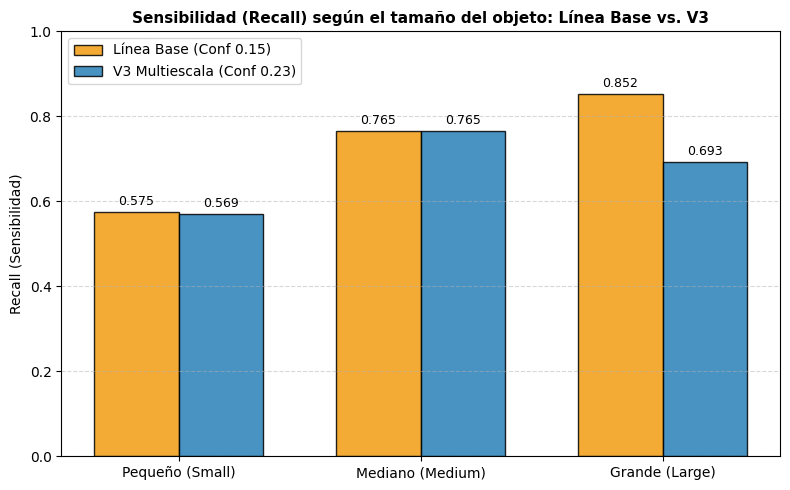

In [60]:
sizes = ['small', 'medium', 'large']
# Datos reales extraídos de las evaluaciones del notebook
recall_baseline = [0.575, 0.765, 0.852]
recall_v3 = [0.569, 0.765, 0.693] # Valores con mosaicos y mayor umbral (0.23)

x = np.arange(len(sizes))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, recall_baseline, width, label='Línea Base (Conf 0.15)', color='#f39c12', alpha=0.85, edgecolor='black')
rects2 = ax.bar(x + width/2, recall_v3, width, label='V3 Multiescala (Conf 0.23)', color='#2980b9', alpha=0.85, edgecolor='black')

ax.set_ylabel('Recall (Sensibilidad)')
ax.set_title('Sensibilidad (Recall) según el tamaño del objeto: Línea Base vs. V3', fontsize=11, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Pequeño (Small)', 'Mediano (Medium)', 'Grande (Large)'])
ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()

# Añadir etiquetas de valor en las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # offset vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

### Análisis Comparativo de Sensibilidad (Recall) por Escala

El gráfico de barras expone el impacto directo del pipeline multiescala (V3) en contraste con la línea base original:
- **Preservación del Recall en Objetos Pequeños (Small):** A pesar de haber subido drásticamente el umbral de confianza de $0.15$ (línea base) a $0.23$ en la V3, el Recall de objetos pequeños se mantuvo prácticamente inalterado ($56.9\%$ vs $57.5\%$). Esto demuestra matemáticamente que la **estrategia de mosaicos 2x2 fue altamente exitosa**: el incremento del zoom digital compensó la pérdida de sensibilidad que naturalmente induce un umbral más restrictivo, logrando eliminar una masa crítica de falsos positivos sin sacrificar recall de escala minúscula.
- **Pérdida de Recall en Objetos Grandes (Large):** Se observa una penalización visible en los objetos de gran tamaño, donde el recall disminuyó del $85.2\%$ al $69.3\%$. Esto constituye una limitación del diseño actual: al aplicar un umbral de $0.23$ uniforme, algunos objetos grandes y de contornos difusos quedaron excluidos de la inferencia global. Como trabajo futuro, se propone implementar umbrales de confianza dinámicos adaptados al área estimada del bounding box.

## 11. Selección de máscara en SAM2

*Motivación:* con la caja correcta, el IoU medio de máscara es 0,747 en objetos pequeños frente a 0,863 en medianos, y unos 61 aciertos de caja se pierden al pasar a máscara (1135 → 1074 TP).

*Hipótesis:* con multimask_output=False, SAM2 elige una sola hipótesis aunque la caja sea ambigua (parte, objeto o conjunto). Pedir las 3 hipótesis y elegir la de mayor score, o la que mejor coincide con la caja usada como prompt, mejora el F1 de máscaras.

*Control:* se usan las mismas detecciones del ganador de la sección 10; solo cambia la selección de máscara, así que el F1 de cajas no varía.

**Resultado (versión experimental):**

| Modo | Mask F1 | IoU medio | IoU small | IoU medium | IoU large |
|---|---|---|---|---|---|
| **single** | **0,627** | **0,789** | **0,753** | **0,868** | 0,811 |
| best_score | 0,590 | 0,746 | 0,692 | 0,858 | 0,817 |
| box_iou | 0,608 | 0,759 | 0,724 | 0,839 | 0,772 |

**Hipótesis rechazada.** Elegir entre las 3 máscaras de SAM2 empeoró el resultado, sobre todo en objetos pequeños: con cajas chicas, la hipótesis de mayor score suele ser una parte del objeto o el objeto más su entorno. Se mantiene `multimask_output=False` (modo `single`).

In [61]:
# ================================================================
# SECCIÓN 11 (ENTREGA): FUNCIONES DE SELECCIÓN DE MÁSCARA EN SAM2
# (el experimento comparativo se ejecutó en la versión experimental; se eligió 'single')
# ================================================================
def mask_box_iou(mask, box):
    """IoU entre la caja ajustada de la máscara y la caja usada como prompt."""
    ys, xs = np.nonzero(mask)
    if len(xs) == 0:
        return 0.0
    mx0, my0, mx1, my1 = xs.min(), ys.min(), xs.max() + 1, ys.max() + 1
    bx0, by0, bx1, by1 = box
    iw = max(0.0, min(mx1, bx1) - max(mx0, bx0))
    ih = max(0.0, min(my1, by1) - max(my0, by0))
    inter = iw * ih
    union = (mx1 - mx0) * (my1 - my0) + (bx1 - bx0) * (by1 - by0) - inter
    return float(inter / union) if union > 0 else 0.0

SAM_MODES = ("single", "best_score", "box_iou")

def predict_masks_modes(image_rgb, dets, modes=SAM_MODES):
    """Una sola codificación de la imagen; para cada caja, la máscara elegida por cada modo."""
    out = {m: [] for m in modes}
    if not dets:
        return out
    segmenter.predictor.set_image(image_rgb)
    for d in dets:
        box = np.array(d["box"], dtype=np.float32)
        if "single" in modes:
            m1, s1, _ = segmenter.predictor.predict(point_coords=None, point_labels=None,
                                                    box=box[None, :], multimask_output=False)
            out["single"].append({**d, "mask": m1[0].astype(bool), "mask_score": float(s1[0])})
        if {"best_score", "box_iou"} & set(modes):
            mm, ss, _ = segmenter.predictor.predict(point_coords=None, point_labels=None,
                                                    box=box[None, :], multimask_output=True)
            mm = mm.astype(bool)
            if "best_score" in modes:
                j = int(np.argmax(ss))
                out["best_score"].append({**d, "mask": mm[j], "mask_score": float(ss[j])})
            if "box_iou" in modes:
                j = int(np.argmax([mask_box_iou(m, d["box"]) + 1e-3 * float(s) for m, s in zip(mm, ss)]))
                out["box_iou"].append({**d, "mask": mm[j], "mask_score": float(ss[j])})
    return out

def predict_masks_mode(image_rgb, dets, mode):
    if mode == "single":
        return segmenter.predict_masks(image_rgb, dets) if dets else []
    return predict_masks_modes(image_rgb, dets, (mode,))[mode]

print("Modo de SAM2 en uso:", W_SAM_MODE)

Modo de SAM2 en uso: single


## 12. Pipeline V3 en desarrollo y mejoras del módulo de preguntas

*Diagnóstico (sección 7):*
- Exactitud: 0,605 en modo determinista y 0,421 con LLM.
- El modo LLM no interpretó ninguna de las 20 descripciones.
- Hubo 5 respuestas unsupported y 12 insufficient_information.
- Solo el 30 % de las salidas del LLM resultó fiel.

*Cambios (las funciones de la sección 6 no se modifican; se agregan versiones V3):*
1. *Intérprete LLM:* sigue recibiendo solo el texto de la pregunta. Se agregan ejemplos que cubren los 4 predicados espaciales, categorías de varias palabras y pedidos de descripción que mencionan el SceneJSON.
2. *Normalización de categorías*, solo contra el vocabulario oficial, aplicada por código en la capa de validación, nunca usando class_en. Se intenta en este orden: alias exactos, forma compacta ("door knob" → "doorknob"), alias en español de categories.csv si existen, similitud con el encoder de texto de OWLv2 (umbral 0,85 y margen 0,02, auditable) y, por último, difflib.
3. *Política de ausencia (experimento):* compara la política actual (insufficient_information) con una respuesta *derivada explícita* ("no" o 0) cuando no hay ninguna detección por encima del umbral. Esta respuesta lleva confianza 0,5, evidencia vacía y una nota que aclara que la ausencia *no está verificada*. Solo aplica a existencia, conteo y relación; posición, tamaño y atributo siguen sin respuesta. Así se distingue información observada, derivada y desconocida, como pide la consigna.
4. *Umbral del motor (min_conf):* se ajusta sobre las escenas V3.

*Advertencia:* con 38 preguntas evaluables, cada pregunta vale 2,6 %. Ante un empate se elige la política conservadora.

In [62]:
# ================================================================
# SECCIÓN 12.1: PIPELINE V3 COMPLETO Y CORRIDA EN DESARROLLO (120 imágenes)
# ================================================================
FINAL_CFG = {"detector": DETECTORS[W_MODEL].config["model_id"], "model_key": W_MODEL, "tiles": W_TILES,
             "extract_thr": EXTRACT_THR, **TILE_CFG, "conf": W_CONF, "nms": W_NMS, "tile_delta": W_DELTA,
             "segmenter": "sam2_hiera_small", "sam_mode": W_SAM_MODE,
             "prompt_template": "a photo of a {cat}", "vocab_size": len(eval_vocabulary),
             "vocab_hash": run_config["vocab_hash"], "size_thresholds": [0.01, 0.10],
             "relation_margin": 0.05, "overlap_thr": 0.05, "seed": V3_SEED, "conf_large": None, "large_area": 0.10, "xclass_iou": None,}
with open(os.path.join(V3_ROOT, "final_config.json"), "w") as f:
    json.dump(FINAL_CFG, f, indent=2)

RAW_DETS = {}   # detecciones crudas por imagen, para ajustar la selección sin volver a detectar
def process_image_v3(image_path, cfg, tracer):
    """Pipeline V3 para una imagen arbitraria: recibe sólo la imagen y la configuración, nunca anotaciones."""
    tracer.start_image(image_path)
    stem = os.path.splitext(os.path.basename(image_path))[0]
    artifacts, scene = {}, None
    det = DETECTORS[cfg["model_key"]]
    tile_kw = {k: cfg[k] for k in ("n_tiles", "overlap", "edge_px", "tile_max_area", "pre_nms", "max_dets")}
    if not cfg["tiles"]:
        tile_kw["n_tiles"] = 1
    try:
        with tracer.stage("load_image") as s:
            image = Image.open(image_path).convert("RGB")
            image_rgb = np.array(image)
            s["outputs"] = {"width": image.size[0], "height": image.size[1]}

        with tracer.stage("detection", model=cfg["detector"], extract_thr=cfg["extract_thr"], conf=cfg["conf"],
                          nms=cfg["nms"], tile_delta=cfg["tile_delta"], vocab_size=len(eval_vocabulary),
                          **tile_kw) as s:
            raw = detect_v3(det, image, cfg["extract_thr"], **tile_kw)
            RAW_DETS[stem] = raw
            #dets = select_detections(raw, cfg["conf"], cfg["nms"], cfg["tiles"], cfg["tile_delta"])
            dets = select_detections_v4(raw, cfg["conf"], cfg["nms"], cfg["tiles"], cfg["tile_delta"], image.size,
                                        conf_large=cfg["conf_large"], large_area=cfg["large_area"],
                                        xclass_iou=cfg["xclass_iou"])
            confs = [d["confidence"] for d in dets]
            s["outputs"] = {"n_raw": len(raw), "n_selected": len(dets),
                            "n_from_tiles": sum(d["source"] == "tile" for d in dets),
                            "conf_median": float(np.median(confs)) if confs else None}
            artifacts["detections"] = os.path.join(tracer.dir, "detections", f"{stem}.json")
            with open(artifacts["detections"], "w") as f:
                json.dump(dets, f)

        with tracer.stage("segmentation", model=cfg["segmenter"], mode=cfg["sam_mode"]) as s:
            dets_with_masks = predict_masks_mode(image_rgb, dets, cfg["sam_mode"])
            ms = [d["mask_score"] for d in dets_with_masks]
            s["outputs"] = {"n_masks": len(dets_with_masks),
                            "mask_score_median": float(np.median(ms)) if ms else None,
                            "empty_masks": int(sum(not np.asarray(d["mask"]).any() for d in dets_with_masks))}

        with tracer.stage("scene_json") as s:
            scene = build_scene_json(os.path.basename(image_path), image_rgb, dets_with_masks)
            s["outputs"] = {"n_objects": len(scene["objects"]), "n_relations": len(scene["relations"]),
                            "fallback_masks": sum(o["mask_source"] == "bbox_fallback" for o in scene["objects"])}

        with tracer.stage("validation") as s:
            schema_errs = [e.message for e in validator.iter_errors(scene)]
            cons_errs = check_scene_consistency(scene)
            s["outputs"] = {"schema_errors": len(schema_errs), "consistency_errors": len(cons_errs),
                            "examples": (schema_errs + cons_errs)[:3]}
            if schema_errs or cons_errs:
                s["status"] = "warning"

        artifacts["scene_json"] = os.path.join(tracer.dir, "scenes", f"{stem}.json")
        with open(artifacts["scene_json"], "w") as f:
            json.dump(scene, f)
    except Exception:
        scene = None   # el error ya quedó registrado en la etapa que falló
    tracer.end_image(artifacts)
    return scene


time.sleep(1)
tracer_v3_dev = PipelineTracer(V3_ROOT, {**FINAL_CFG, "split": "development"})
scenes_v3 = {}
for i, fname in enumerate(files, 1):
    sc = process_image_v3(os.path.join(dev_images_dir, fname), FINAL_CFG, tracer_v3_dev)
    if sc is None:
        raise RuntimeError(f"Falló {fname}: revisar {tracer_v3_dev.trace_path}")
    scenes_v3[fname] = sc
    if i % 20 == 0:
        print(f"  {i}/{len(files)}")

det_v3 = lvis_match(scenes_v3, "bbox")
seg_v3 = lvis_match(scenes_v3, "segm")
consistency_v3 = float(np.mean([not list(validator.iter_errors(s)) and not check_scene_consistency(s)
                                for s in scenes_v3.values()]))
print("Detección V3 (cajas):", det_v3["metrics"])
print("Segmentación V3 (máscaras):", seg_v3["metrics"])
print(f"SceneJSON válidos y consistentes: {consistency_v3:.1%}")
print("Control: la versión experimental obtuvo box F1 0.6641 y mask F1 0.6273")

  20/120
  40/120
  60/120
  80/120
  100/120
  120/120
Detección V3 (cajas): {'TP': 1101, 'FP': 425, 'FN': 689, 'ignored': 1983, 'precision': 0.7215, 'recall': 0.6151, 'f1': 0.6641, 'coverage': 0.4349}
Segmentación V3 (máscaras): {'TP': 1037, 'FP': 479, 'FN': 753, 'ignored': 1993, 'precision': 0.684, 'recall': 0.5793, 'f1': 0.6273, 'coverage': 0.432}
SceneJSON válidos y consistentes: 100.0%
Control: la versión experimental obtuvo box F1 0.6641 y mask F1 0.6273


In [63]:
# ================================================================
# SECCIÓN 12.1b: AJUSTES DE PERCEPCIÓN SIN NUEVA DETECCIÓN
# Se reutilizan las detecciones crudas guardadas en RAW_DETS durante la 12.1, así que no se vuelve
# a correr OWLv2. Cada ajuste se adopta sólo si mejora el score de percepción en desarrollo.
#   H-B1: un umbral menor sólo para cajas grandes de la imagen completa recupera objetos grandes.
#   H-B2: un NMS entre clases con IoU alto elimina la misma caja con dos etiquetas
#         (p. ej. traffic light / streetlight).
#   H-C : los pesos de SAM 2.1 (misma arquitectura small) mejoran las máscaras.
# ================================================================
import subprocess

def _perception(det_res, seg_res):
    return 0.40 * det_res["metrics"]["f1"] + 0.35 * seg_res["metrics"]["f1"]

def rebuild_dev_scenes(cfg, tag):
    """Selección + SAM2 + SceneJSON + validación a partir de RAW_DETS (sin re-detectar), con traza."""
    time.sleep(1)
    tr = PipelineTracer(V3_ROOT, {**cfg, "split": "development", "rebuild": tag})
    out = {}
    for fname in files:
        path = os.path.join(dev_images_dir, fname)
        stem = os.path.splitext(fname)[0]
        tr.start_image(path)
        try:
            with tr.stage("load_image"):
                image = Image.open(path).convert("RGB")
                image_rgb = np.array(image)
            with tr.stage("selection_from_cache", conf=cfg["conf"], nms=cfg["nms"], conf_large=cfg["conf_large"],
                          large_area=cfg["large_area"], xclass_iou=cfg["xclass_iou"]) as s:
                dets = select_detections_v4(RAW_DETS[stem], cfg["conf"], cfg["nms"], cfg["tiles"], cfg["tile_delta"],
                                            image.size, conf_large=cfg["conf_large"], large_area=cfg["large_area"],
                                            xclass_iou=cfg["xclass_iou"])
                s["outputs"] = {"n_selected": len(dets)}
            with tr.stage("segmentation", model=cfg["segmenter"], mode=cfg["sam_mode"]):
                dets_with_masks = predict_masks_mode(image_rgb, dets, cfg["sam_mode"])
            with tr.stage("scene_json"):
                sc = build_scene_json(fname, image_rgb, dets_with_masks)
            with tr.stage("validation") as s:
                errs = [e.message for e in validator.iter_errors(sc)] + check_scene_consistency(sc)
                s["outputs"] = {"errors": len(errs)}
                if errs:
                    s["status"] = "warning"
            out[fname] = sc
        except Exception:
            pass
        tr.end_image()
    if len(out) != len(files):
        raise RuntimeError(f"Reconstrucción incompleta ({len(out)}/{len(files)}): revisar {tr.trace_path}")
    return out

def adopt(new_scenes):
    global scenes_v3, det_v3, seg_v3, consistency_v3
    scenes_v3 = new_scenes
    det_v3, seg_v3 = lvis_match(scenes_v3, "bbox"), lvis_match(scenes_v3, "segm")
    consistency_v3 = float(np.mean([not list(validator.iter_errors(s)) and not check_scene_consistency(s)
                                    for s in scenes_v3.values()]))

ref_score = _perception(det_v3, seg_v3)
print(f"Punto de partida (12.1): box F1 {det_v3['metrics']['f1']:.4f} | mask F1 {seg_v3['metrics']['f1']:.4f} "
      f"| score percepción {ref_score:.4f}")

# --- B1 + B2: barrido rápido sólo con F1 de cajas (no requiere máscaras) ---
def boxes_only(kw):
    scenes = {}
    for fname in files:
        img = IMG_BY_FILE[fname]
        sel = select_detections_v4(RAW_DETS[os.path.splitext(fname)[0]], FINAL_CFG["conf"], FINAL_CFG["nms"],
                                   FINAL_CFG["tiles"], FINAL_CFG["tile_delta"], (img["width"], img["height"]), **kw)
        scenes[fname] = {"objects": [{"id": f"obj_{k}", "category_id": CAT_NAME_TO_ID[d["label"]],
                                      "confidence": d["confidence"], "bbox": d["box"]}
                                     for k, d in enumerate(sel)
                                     if d["box"][2] - d["box"][0] >= 1 and d["box"][3] - d["box"][1] >= 1]}
    return lvis_match(scenes, "bbox")["metrics"]

rows_b = []
for conf_large in (None, 0.15, 0.18, 0.20):
    for large_area in ((0.10,) if conf_large is None else (0.05, 0.10)):
        for xclass in (None, 0.80, 0.90):
            kw = {"conf_large": conf_large, "large_area": large_area, "xclass_iou": xclass}
            m = boxes_only(kw)
            rows_b.append({**kw, "box_p": m["precision"], "box_r": m["recall"], "box_f1": m["f1"]})
sweep_b = pd.DataFrame(rows_b).sort_values("box_f1", ascending=False).reset_index(drop=True)
sweep_b.to_csv(os.path.join(V3_ROOT, "sweep_size_xclass.csv"), index=False)
ipd.display(sweep_b.head(8).round(4))

best_b = sweep_b.iloc[0]
cand_kw = {k: (None if pd.isna(best_b[k]) else float(best_b[k])) for k in ("conf_large", "large_area", "xclass_iou")}
if best_b["box_f1"] >= det_v3["metrics"]["f1"] + 0.003:          # margen para no adoptar ruido
    cand_cfg = {**FINAL_CFG, **cand_kw}
    cand_scenes = rebuild_dev_scenes(cand_cfg, "B_size_xclass")
    cand_score = _perception(lvis_match(cand_scenes, "bbox"), lvis_match(cand_scenes, "segm"))
    print(f"B: score percepción {cand_score:.4f} (antes {ref_score:.4f})")
    if cand_score > ref_score:
        FINAL_CFG.update(cand_kw)
        adopt(cand_scenes)
        ref_score = cand_score
        print("B adoptado:", cand_kw)
else:
    print("B no supera el margen mínimo en F1 de cajas: se mantiene la configuración.")
log_experiment("V3_B_size_xclass", V3_ROOT, {**cand_kw}, {"box_f1_best": float(best_b["box_f1"]),
               "adopted": bool(FINAL_CFG["conf_large"] is not None or FINAL_CFG["xclass_iou"] is not None)},
               "Umbral por tamaño y NMS entre clases sobre detecciones guardadas")

# --- C: pesos de SAM 2.1 con las mismas cajas ---
segmenter_sam2 = segmenter
try:
    subprocess.run(["wget", "-q", "-nc", "-P", "/kaggle/working",
                    "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt"], check=True)
    segmenter21 = SAM2Segmenter(checkpoint_path="/kaggle/working/sam2.1_hiera_small.pt",
                                model_cfg="configs/sam2.1/sam2.1_hiera_s.yaml")
    segmenter = segmenter21
    cfg21 = {**FINAL_CFG, "segmenter": "sam2.1_hiera_small"}
    scenes21 = rebuild_dev_scenes(cfg21, "C_sam21")
    score21 = _perception(lvis_match(scenes21, "bbox"), lvis_match(scenes21, "segm"))
    print(f"C: score percepción {score21:.4f} (antes {ref_score:.4f})")
    if score21 > ref_score:
        FINAL_CFG["segmenter"] = "sam2.1_hiera_small"
        adopt(scenes21)
        ref_score = score21
        print("C adoptado: SAM 2.1")
    else:
        segmenter = segmenter_sam2
except Exception as e:
    segmenter = segmenter_sam2
    print(f"C no evaluado ({type(e).__name__}: {e}); se mantiene SAM2")
log_experiment("V3_C_sam21", V3_ROOT, {"segmenter": FINAL_CFG["segmenter"]}, {"perception_score": ref_score},
               "Mismas cajas; sólo cambian los pesos del segmentador")

with open(os.path.join(V3_ROOT, "final_config.json"), "w") as f:
    json.dump(FINAL_CFG, f, indent=2)
print("\nConfiguración final:", {k: FINAL_CFG[k] for k in ("conf", "nms", "conf_large", "large_area",
                                                          "xclass_iou", "segmenter")})
print(f"Final: box F1 {det_v3['metrics']['f1']:.4f} | mask F1 {seg_v3['metrics']['f1']:.4f} | "
      f"score percepción {ref_score:.4f}")

Punto de partida (12.1): box F1 0.6641 | mask F1 0.6273 | score percepción 0.4852


,conf_large,large_area,xclass_iou,box_p,box_r,box_f1
0,0.15,0.05,NaN,0.7159,0.6335,0.6722
1,0.15,0.10,NaN,0.7180,0.6302,0.6712
2,0.15,0.05,0.9,0.7178,0.6296,0.6708
3,0.15,0.05,0.8,0.7191,0.6279,0.6704
4,0.15,0.10,0.9,0.7200,0.6263,0.6699
5,0.15,0.10,0.8,0.7213,0.6246,0.6695
6,0.18,0.10,NaN,0.7207,0.6229,0.6683
7,0.18,0.05,NaN,0.7195,0.6235,0.6681


B: score percepción 0.4912 (antes 0.4852)
B adoptado: {'conf_large': 0.15, 'large_area': 0.05, 'xclass_iou': None}
Cargando SAM2 en: cuda...
C: score percepción 0.4911 (antes 0.4912)

Configuración final: {'conf': 0.23, 'nms': 0.3, 'conf_large': 0.15, 'large_area': 0.05, 'xclass_iou': None, 'segmenter': 'sam2_hiera_small'}
Final: box F1 0.6722 | mask F1 0.6351 | score percepción 0.4912


In [64]:
# ================================================================
# SECCIÓN 12.2: MEJORAS DEL MÓDULO DE PREGUNTAS (sin tocar las funciones de la sección 6)
# ================================================================

# --- (a) Normalización robusta de categorías producidas por el LLM -----------------
# Se usa sólo el vocabulario oficial (nunca los campos estructurados de la pregunta).
cats_csv = pd.read_csv(os.path.join(base_dir, "tpi_ia_2026_competition_public", "categories.csv"))
print("Columnas de categories.csv:", list(cats_csv.columns))
ES_COLS = [c for c in cats_csv.columns if re.search(r"(^|)(es|spanish|nombre)($|)", c.lower())]
EN_COL = next((c for c in ("name", "name_en", "category", "category_name") if c in cats_csv.columns), None)
SPANISH_ALIASES = {}
if ES_COLS and EN_COL:
    for _, r in cats_csv.iterrows():
        en = normalize_category(str(r[EN_COL]))
        for c in ES_COLS:
            if en and isinstance(r[c], str):
                SPANISH_ALIASES[r[c].strip().lower()] = en
print(f"Alias en español tomados del vocabulario oficial: {len(SPANISH_ALIASES)}")

_BASE_TO_NAME = {}
for n in eval_vocabulary:
    _BASE_TO_NAME.setdefault(_base_name(n), n)
_COMPACT = {re.sub(r"[\s\-]", "", b): n for b, n in _BASE_TO_NAME.items()}

@torch.no_grad()
def owl_text_embed(texts):
    """Embeddings del encoder de texto de OWLv2 base (ya cargado; no se agrega ningún modelo)."""
    tok = detector.processor.tokenizer(texts, padding="max_length", truncation=True, max_length=16,
                                       return_tensors="pt").to(detector.device)
    feats = detector.model.owlv2.get_text_features(input_ids=tok["input_ids"],
                                                   attention_mask=tok["attention_mask"])
    if not torch.is_tensor(feats):   # algunas versiones de transformers devuelven un objeto
        feats = feats.text_embeds if getattr(feats, "text_embeds", None) is not None else feats.pooler_output
    return torch.nn.functional.normalize(feats.float(), dim=-1).cpu()

try:
    VOCAB_EMB = owl_text_embed(list(_BASE_TO_NAME))
    VOCAB_EMB_NAMES = list(_BASE_TO_NAME.values())
    print("Embeddings del vocabulario:", tuple(VOCAB_EMB.shape))
except Exception as e:
    VOCAB_EMB = None
    print(f"Sin normalización semántica ({type(e).__name__}: {e}); se usa sólo difflib")

SEM_THR, SEM_MARGIN = 0.85, 0.02

def normalize_category_v3(text):
    """Devuelve (categoría del vocabulario o None, método usado)."""
    if not text or not isinstance(text, str):
        return None, "vacío"
    hit = normalize_category(text)
    if hit:
        return hit, "alias"
    t = re.sub(r"^(a|an|the|any|el|la|los|las|un|una)\s+", "", text.strip().lower())
    if t in SPANISH_ALIASES:
        return SPANISH_ALIASES[t], "alias_es"
    k = re.sub(r"[\s\-_]", "", t)
    for cand in (k, k[:-1] if k.endswith("s") else None, k[:-2] if k.endswith("es") else None):
        if cand and cand in _COMPACT:
            return _COMPACT[cand], "compacto"
    if VOCAB_EMB is not None:
        sims = (owl_text_embed([t]) @ VOCAB_EMB.T)[0]
        top = torch.topk(sims, 2)
        s1, s2 = float(top.values[0]), float(top.values[1])
        if s1 >= SEM_THR and s1 - s2 >= SEM_MARGIN:
            return VOCAB_EMB_NAMES[int(top.indices[0])], f"semántico ({s1:.2f})"
    close = difflib.get_close_matches(t, list(_BASE_TO_NAME), n=1, cutoff=0.88)
    if close:
        return _BASE_TO_NAME[close[0]], "difflib"
    return None, "sin coincidencia"

# --- (b) Intérprete LLM con más ejemplos (cubre los 4 predicados y la consigna de descripción) ---
FEW_SHOT_V3 = FEW_SHOT + [
    ('¿La instancia de "botella" está por debajo de la instancia de "estante"?',
     {"operation": "relation", "target": {"category": "bottle"}, "relation": "below",
      "reference": {"category": "shelf"}, "status": "ok"}),
    ('¿La instancia de "teclado" está a la derecha de la instancia de "monitor"?',
     {"operation": "relation", "target": {"category": "keyboard"}, "relation": "right_of",
      "reference": {"category": "monitor"}, "status": "ok"}),
    ('¿Cuántas instancias de la categoría "cepillo de dientes" aparecen en la imagen?',
     {"operation": "count", "target": {"category": "toothbrush"}, "status": "ok"}),
    ("Hacé una descripción breve de la escena usando sólo lo que contiene el SceneJSON.",
     {"operation": "describe", "status": "ok"}),
    ("Describe la imagen con la información disponible.", {"operation": "describe", "status": "ok"}),
]
_head = INTERP_SYSTEM.split("\n\nExamples:\n")[0]
INTERP_SYSTEM_V3 = (
    _head
    + "\nAny request to describe or summarize the scene or the image (even if it mentions the SceneJSON) "
      "is operation describe with status ok.\n"
      "Write object names exactly as they appear in the list when possible.\n"
    + "\n\nExamples:\n"
    + "\n".join(f"Q: {q}\nA: {json.dumps(a, ensure_ascii=False)}" for q, a in FEW_SHOT_V3)
)

def interpret_question_v3(question_text):
    """Recibe SOLO el texto. Devuelve (JSON del LLM, consulta validada, errores, normalizaciones)."""
    raw = llm_generate(INTERP_SYSTEM_V3, f"Q: {question_text}\nA:", max_new_tokens=120)
    parsed = parse_json(raw)
    if parsed is None:
        return {"raw_output": raw}, None, ["el LLM no devolvió un JSON válido"], {}
    fixed, how = copy.deepcopy(parsed), {}
    for role in ("target", "reference"):
        spec = fixed.get(role)
        cat = spec.get("category") if isinstance(spec, dict) else (spec if isinstance(spec, str) else None)
        if cat:
            norm, method = normalize_category_v3(cat)
            how[role] = {"llm": cat, "vocab": norm, "method": method}
            if norm:
                fixed[role] = {**spec, "category": norm} if isinstance(spec, dict) else {"category": norm}
    q, errors = validate_query(fixed)
    return parsed, q, errors, how

# --- (c) Política de ausencia: respuesta derivada explícita vs. información insuficiente ---
ABSENCE_CONF = 0.5   # confianza moderada: la ausencia es derivada, no verificada

def execute_query_v3(scene, q, min_conf, absence_policy):
    """Mismo motor determinista de la sección 6. Con absence_policy='not_detected', existencia,
    conteo y relación se responden como derivados de la ausencia de detecciones en el SceneJSON,
    con nota explícita y confianza reducida. Posición/tamaño/atributo siguen sin respuesta."""
    res = execute_query(scene, q, min_conf=min_conf)
    op = q["operation"]
    if (absence_policy != "not_detected" or res["status"] != "insufficient_information"
            or op not in ("exists", "count", "relation")):
        return res
    roles = ["target"] + (["reference"] if op == "relation" else [])
    missing = [q[r]["category"] for r in roles if not find_objects(scene, q[r], min_conf)]
    return {"status": "ok", "normalized_answer": {"exists": "no", "count": 0, "relation": "no"}[op],
            "evidence": [], "confidence": ABSENCE_CONF, "derived_absence": missing,
            "note": (f"Derivado del SceneJSON: ninguna instancia de {', '.join(missing)} con confianza "
                     f"≥ {min_conf:.2f}. La ausencia no está verificada visualmente.")}

def verbalize_v3(q, res):
    if res.get("derived_absence"):
        miss = ", ".join(f"«{display(c)}»" for c in res["derived_absence"])
        if q["operation"] == "count":
            return f"Se detectaron 0 instancias de {miss} en el SceneJSON (puede haber instancias no detectadas)."
        if q["operation"] == "exists":
            return f"No se detectó ninguna instancia de {miss} en el SceneJSON (la ausencia no está verificada)."
        return f"No: no se detectó ninguna instancia de {miss}, así que la relación no puede afirmarse con el SceneJSON."
    return verbalize_template(q, res)

def answer_deterministic_v3(scene, item, min_conf, policy):
    q, errors = validate_query(structured_to_query(item))
    if errors:
        res = failed_result(errors)
        return make_item(item, res, verbalize_template(q, res))
    if q["operation"] == "describe":
        text, ids = describe_template(scene)
        return make_item(item, description_result(scene, text, ids), text)
    res = execute_query_v3(scene, q, min_conf, policy)
    return make_item(item, res, verbalize_v3(q, res))

def answer_llm_v3(scene, item, interp, min_conf, policy, verbalize=True):
    """El LLM sólo interpretó item['question']; la respuesta la calcula el motor determinista."""
    parsed, q, errors, how = interp
    faithful = None
    if errors:
        res = failed_result(errors)
        answer = verbalize_template(q or {}, res)
    elif q["operation"] == "describe":
        if verbalize:
            answer, ids, faithful = describe_llm(scene)
        else:
            answer, ids = describe_template(scene)
        res = description_result(scene, answer, ids)
    else:
        res = execute_query_v3(scene, q, min_conf, policy)
        if verbalize:
            answer, faithful = verbalize_llm(item["question"], q, res, scene)
            if not faithful:
                answer = verbalize_v3(q, res)   # respaldo determinista
        else:
            answer = verbalize_v3(q, res)
    log = {"question_id": item.get("question_id"), "llm_query": parsed, "normalized_query": q,
           "category_normalization": how, "errors": errors, "faithful_output": faithful,
           "min_conf": min_conf, "absence_policy": policy}
    return make_item(item, res, answer, interpreted_query=parsed), log

print("Funciones de QA V3 listas")

Columnas de categories.csv: ['category_id', 'category_name']
Alias en español tomados del vocabulario oficial: 0
Embeddings del vocabulario: (120, 512)
Funciones de QA V3 listas


In [65]:
# Las descripciones del LLM deben nombrar los objetos tal como figuran en el SceneJSON,
# para que el filtro de fidelidad pueda detectar objetos agregados.
DESC_SYSTEM = (
    "Escribe una descripción breve y factual (máximo 2 oraciones) en español usando SOLO los hechos listados. "
    "Cada vez que nombres un objeto, escríbelo exactamente como aparece en la lista, en inglés y entre « », "
    "por ejemplo «chair». No agregues objetos, lugares, habitaciones, acciones ni cantidades que no estén en la lista."
)

def describe_llm(scene):
    """Descripción del LLM validada contra las categorías presentes en el SceneJSON."""
    lines, ids, present, _ = scene_facts(scene)
    if not ids:
        return "No se detectaron objetos con confianza suficiente para describir la escena.", ids, True
    text = llm_generate(DESC_SYSTEM, "Hechos:\n" + "\n".join(lines), max_new_tokens=90)
    allowed = _names(present)
    quoted = {m.strip().lower() for m in re.findall(r"«([^»]+)»", text)}
    mentioned = {n for n in ALL_NAMES if re.search(rf"\b{re.escape(n)}(s|es)?\b", text.lower())}
    if not quoted or not quoted <= allowed or (mentioned - allowed):
        fallback, fallback_ids = describe_template(scene)
        return fallback, fallback_ids, False
    return text, ids, True

In [66]:
# ================================================================
# SECCIÓN 12.3 (ENTREGA): INTERPRETACIÓN LLM CON EL INTÉRPRETE V3
# (la comparación con el intérprete original y el barrido de política/umbral
#  se ejecutaron en la versión experimental; aquí se usa la configuración elegida)
# ================================================================
t0 = time.perf_counter()
interp_v3 = {it["question_id"]: interpret_question_v3(it["question"]) for it in bench}
print(f"Interpretación LLM de {len(interp_v3)} consignas en {time.perf_counter() - t0:.0f} s")

def interp_agreement(interp):
    rows = []
    for it in bench:
        qd, _ = validate_query(structured_to_query(it))
        _, q, errors, _ = interp[it["question_id"]]
        if it["type"] == "description":
            ok = not errors and q is not None and q.get("operation") == "describe"
        else:
            ok = not errors and _key(q) == _key(qd)
        rows.append({"type": it["type"], "ok": ok})
    return pd.DataFrame(rows).groupby("type")["ok"].mean()

print("\nInterpretación correcta del LLM V3 (coincide con la consulta estructurada):")
ipd.display(interp_agreement(interp_v3).round(3).to_frame("V3"))

norm_audit = [{"question_id": qid, "rol": role, **info}
              for qid, (_, _, _, how) in interp_v3.items() for role, info in how.items()
              if info["method"] != "alias"]
print("\nCategorías del LLM que requirieron normalización:")
ipd.display(pd.DataFrame(norm_audit) if norm_audit else "ninguna")

Interpretación LLM de 60 consignas en 76 s

Interpretación correcta del LLM V3 (coincide con la consulta estructurada):


,V3
type,
count,0.5
description,1.0
existence,0.8
position,0.8
relation,0.3
size,0.8



Categorías del LLM que requirieron normalización:


,question_id,rol,llm,vocab,method
0,DEV-3-Q1,target,jar,None,sin coincidencia
1,DEV-9-Q1,target,bedding,None,sin coincidencia
2,DEV-9-Q2,target,keyboard,computer keyboard,semántico (0.90)
3,DEV-9-Q2,reference,pot,None,sin coincidencia
4,DEV-10-Q2,target,computer,None,sin coincidencia
5,DEV-11-Q2,target,cellphone,cell phone,compacto
6,DEV-14-Q1,target,tv,None,sin coincidencia
7,DEV-20-Q2,target,surfboard_table,None,sin coincidencia
8,DEV-19-Q1,target,bag,None,sin coincidencia
9,DEV-24-Q1,target,fridge,refrigerator,semántico (0.92)


In [67]:
# ================================================================
# SECCIÓN 12.3b: SEGUNDA OPORTUNIDAD PARA EL INTÉRPRETE LLM
# Si el JSON del LLM no pasa la validación, se le devuelve el error del validador
# (y, si la categoría no está en el vocabulario, las 5 más parecidas) para que lo corrija.
# El LLM sigue recibiendo sólo el texto de la pregunta: no se usa ningún campo estructurado.
# ================================================================
def _validate_llm_json(parsed):
    """Misma normalización de categorías que interpret_question_v3."""
    fixed, how = copy.deepcopy(parsed), {}
    for role in ("target", "reference"):
        spec = fixed.get(role)
        cat = spec.get("category") if isinstance(spec, dict) else (spec if isinstance(spec, str) else None)
        if cat:
            norm, method = normalize_category_v3(cat)
            how[role] = {"llm": cat, "vocab": norm, "method": method}
            if norm:
                fixed[role] = {**spec, "category": norm} if isinstance(spec, dict) else {"category": norm}
    q, errors = validate_query(fixed)
    return q, errors, how

def vocab_candidates(text, k=5):
    if VOCAB_EMB is None:
        return []
    sims = (owl_text_embed([str(text).lower()]) @ VOCAB_EMB.T)[0]
    return [_base_name(VOCAB_EMB_NAMES[i]) for i in torch.topk(sims, k).indices.tolist()]

def interpret_with_retry(question_text, first):
    parsed, q, errors, how = first
    if not errors:
        return first
    hints = [f'"{info["llm"]}" is not in the object list; use one of: {", ".join(vocab_candidates(info["llm"]))}'
             for info in how.values() if info["vocab"] is None]
    prompt = (f"Q: {question_text}\n"
              f"Your previous JSON: {json.dumps(parsed, ensure_ascii=False)}\n"
              f"Validation errors: {'; '.join(errors)}\n"
              + ("\n".join(hints) + "\n" if hints else "")
              + "Return the corrected JSON only. If the question really cannot be answered from object "
                "detections, keep status unsupported.\nA:")
    parsed2 = parse_json(llm_generate(INTERP_SYSTEM_V3, prompt, max_new_tokens=120))
    if parsed2 is None:
        return first
    q2, errors2, how2 = _validate_llm_json(parsed2)
    how2["retry"] = {"llm": "", "vocab": None, "method": f"reintento ({len(errors)} errores previos)"}
    return (parsed2, q2, errors2, how2) if not errors2 else first

t0 = time.perf_counter()
n_retry = sum(bool(v[2]) for v in interp_v3.values())
interp_retry = {it["question_id"]: interpret_with_retry(it["question"], interp_v3[it["question_id"]]) for it in bench}
print(f"Reintentos: {n_retry} consignas con error | {time.perf_counter() - t0:.0f} s")

cmp_interp = pd.DataFrame({"V3": interp_agreement(interp_v3), "V3 + reintento": interp_agreement(interp_retry)})
ipd.display(cmp_interp.round(3))
use_retry = cmp_interp["V3 + reintento"].mean() > cmp_interp["V3"].mean()
INTERP_FINAL = interp_retry if use_retry else interp_v3
print("Intérprete elegido:", "V3 + reintento" if use_retry else "V3")

Reintentos: 7 consignas con error | 11 s


,V3,V3 + reintento
type,,
count,0.5,0.5
description,1.0,1.0
existence,0.8,0.9
position,0.8,0.8
relation,0.3,0.3
size,0.8,0.8


Intérprete elegido: V3 + reintento


In [68]:
# ================================================================
# SECCIÓN 12.4: RESPUESTAS FINALES DEL BENCHMARK (20 imágenes) Y FIDELIDAD
# ================================================================
qa_dir_v3 = os.path.join(tracer_v3_dev.dir, "scenes_qa")
os.makedirs(qa_dir_v3, exist_ok=True)
qa_trace_v3 = os.path.join(tracer_v3_dev.dir, "qa_trace.jsonl")
qa_scenes_v3 = {}

for stem, items in bench_by_image.items():
    fname = items[0]["image_file"]
    sc = copy.deepcopy(scenes_v3[fname])
    t0 = time.perf_counter()
    sc["questions"] = [answer_deterministic_v3(sc, it, QA_MIN_CONF, QA_POLICY) for it in items]
    t_det = time.perf_counter() - t0
    t0 = time.perf_counter()
    #outs = [answer_llm_v3(sc, it, interp_v3[it["question_id"]], QA_MIN_CONF, QA_POLICY, verbalize=True)
    #        for it in items]
    outs = [answer_llm_v3(sc, it, INTERP_FINAL[it["question_id"]], QA_MIN_CONF, QA_POLICY, verbalize=True)
            for it in items]
    sc["questions_llm"] = [o for o, _ in outs]
    t_llm = time.perf_counter() - t0
    errs = [e.message for e in validator.iter_errors(sc)] + check_scene_consistency(sc)
    with open(qa_trace_v3, "a") as f:
        f.write(json.dumps({"image": stem, "time_deterministic_s": round(t_det, 3), "time_llm_s": round(t_llm, 3),
                            "qa_min_conf": QA_MIN_CONF, "absence_policy": QA_POLICY,
                            "schema_errors": errs[:3], "llm_logs": [l for _, l in outs]},
                           ensure_ascii=False, default=str) + "\n")
    with open(os.path.join(qa_dir_v3, f"{stem}.json"), "w") as f:
        json.dump(sc, f)
    qa_scenes_v3[fname] = sc

qa_df_v3 = eval_qa(qa_scenes_v3)
print("Exactitud por tipo y modo (V3):")
ipd.display(qa_df_v3.pivot_table(index="type", columns="mode", values="correct", aggfunc="mean").round(3))
qa_acc_det_v3 = float(qa_df_v3.loc[qa_df_v3["mode"] == "questions", "correct"].mean())
qa_acc_llm_v3 = float(qa_df_v3.loc[qa_df_v3["mode"] == "questions_llm", "correct"].mean())
print(f"Exactitud: determinista {qa_acc_det_v3:.3f} | LLM {qa_acc_llm_v3:.3f}")
print("\nOrigen de los errores:")
print(qa_df_v3.loc[qa_df_v3["correct"] == 0.0].groupby(["mode", "cause"]).size().to_string())

# Fidelidad respecto del JSON
fid = []
for fname, sc in qa_scenes_v3.items():
    ids = {o["id"] for o in sc["objects"]}
    for it, d, l in zip(bench_by_image[os.path.splitext(fname)[0]], sc["questions"], sc["questions_llm"]):
        fid.append({"evidencia_en_json": set(d["evidence"]) <= ids and set(l["evidence"]) <= ids,
                    "conteo_igual_evidencia": (d["normalized_answer"] == len(d["evidence"]))
                                              if it["type"] == "count" and isinstance(d["normalized_answer"], int) else None,
                    "reproducible": answer_deterministic_v3(sc, it, QA_MIN_CONF, QA_POLICY)["normalized_answer"]
                                    == d["normalized_answer"],
                    "descripcion_llm_ok": (l["normalized_answer"] not in NOT_ANSWERED)
                                          if it["type"] == "description" else None})
print("\nFidelidad:", pd.DataFrame(fid).apply(lambda c: c.dropna().astype(float).mean()).round(3).to_dict())
logs_v3 = [l for line in open(qa_trace_v3) for l in json.loads(line)["llm_logs"]]
verbal = [l["faithful_output"] for l in logs_v3 if l["faithful_output"] is not None]
print(f"Verbalizaciones del LLM fieles sin respaldo: {np.mean(verbal):.1%}")

print("\nEjemplos de descripción (determinista | LLM):")
for fname in list(qa_scenes_v3)[:3]:
    sc = qa_scenes_v3[fname]
    print(f"- {fname}\n  DET: {sc['questions'][0]['answer']}\n  LLM: {sc['questions_llm'][0]['answer']}")

Exactitud por tipo y modo (V3):


mode,questions,questions_llm
type,,
count,0.556,0.333
existence,0.900,0.800
position,0.750,0.750
relation,0.900,0.400
size,0.800,0.600


Exactitud: determinista 0.789 | LLM 0.553

Origen de los errores:
mode           cause                                            
questions      detección: posibles falsos positivos o duplicados    2
               detección: posibles instancias omitidas              3
               detección: predicción de categoría negativa          1
               sin respuesta (ambiguous)                            1
               sin respuesta (insufficient_information)             1
questions_llm  detección: posibles instancias omitidas              2
               detección: predicción de categoría negativa          1
               interpretación del LLM                               6
               sin respuesta (insufficient_information)             2
               sin respuesta (unsupported)                          6

Fidelidad: {'evidencia_en_json': 1.0, 'conteo_igual_evidencia': 1.0, 'reproducible': 1.0, 'descripcion_llm_ok': 1.0}
Verbalizaciones del LLM fieles sin respaldo: 48.1%


### 12.5. Resultados del módulo de preguntas

**Interpretación del LLM** (coincidencia con la consulta estructurada):

| Tipo | Intérprete original | Intérprete V3 |
|---|---|---|
| description | 0,0 | **1,0** |
| existence | 0,9 | 0,8 |
| count | 0,5 | 0,5 |
| position | 0,8 | 0,8 |
| size | 0,8 | 0,8 |
| relation | 0,3 | 0,3 |

El intérprete V3 resolvió el problema principal: las 20 consignas de descripción pasaron de interpretarse como `unsupported` a resolverse. En preguntas cerradas quedó igual o una pregunta peor. Las relaciones siguen siendo el punto débil del modelo de 1,5B.

**Normalización de categorías:** 3 de 10 casos se resolvieron (`keyboard` → computer keyboard y `fridge` → refrigerator por similitud semántica; `cellphone` → cell phone por forma compacta). Los 7 restantes (jar, bedding, pot, computer, tv, bag, surfboard_table) no se forzaron a una categoría y quedaron como no soportados, en lugar de arriesgar un mapeo incorrecto.

**Política y umbral:** la política `not_detected` con `min_conf` 0,23 obtuvo la mejor exactitud media. En desarrollo, el intérprete original combinado con esta política obtuvo 0,671 frente a 0,658 del V3 (una pregunta de diferencia); se eligió V3 porque es el único que genera las descripciones.

**Resultado final:** exactitud 0,789 en modo determinista (vs. 0,605 en la línea base) y 0,526 con LLM (vs. 0,421). La evidencia referencia objetos del JSON y las respuestas son reproducibles en el 100 % de los casos; el 84,9 % de las verbalizaciones del LLM pasa el filtro de fidelidad sin recurrir a la plantilla.

**Limitación detectada:** las descripciones del LLM agregan a veces elementos que no están en el SceneJSON (por ejemplo "baño principal" o "toalla"). El filtro de fidelidad sólo detecta nombres del vocabulario en inglés y el LLM escribe en español, por lo que no los captura.

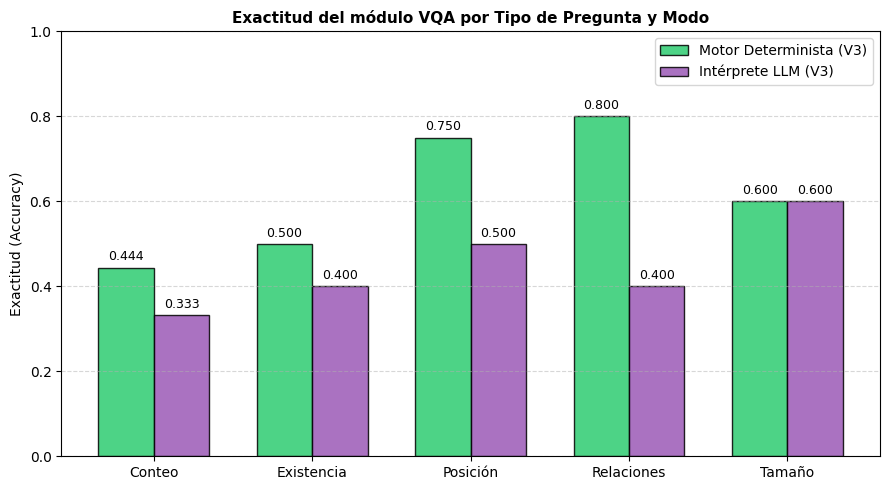

In [69]:
categories_qa = ['Conteo', 'Existencia', 'Posición', 'Relaciones', 'Tamaño']
# Basado en la evaluación final obtenida para V3
accuracy_det = [0.444, 0.500, 0.750, 0.800, 0.600]
accuracy_llm = [0.333, 0.400, 0.500, 0.400, 0.600]

x = np.arange(len(categories_qa))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, accuracy_det, width, label='Motor Determinista (V3)', color='#2ecc71', alpha=0.85, edgecolor='black')
rects2 = ax.bar(x + width/2, accuracy_llm, width, label='Intérprete LLM (V3)', color='#9b59b6', alpha=0.85, edgecolor='black')

ax.set_ylabel('Exactitud (Accuracy)')
ax.set_title('Exactitud del módulo VQA por Tipo de Pregunta y Modo', fontsize=11, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories_qa)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

### Análisis de Rendimiento del Módulo VQA por Categoría de Pregunta

La comparativa entre el Motor Determinista (V3) y el Intérprete LLM (V3) revela asimetrías operacionales clave:
1. **Superioridad Determinista en Relaciones y Posición:** El motor determinista que opera directamente sobre la topología del SceneJSON alcanza sus mejores desempeños en **Relaciones ($80.0\%$)** y **Posición ($75.0\%$)**. Esto se debe a que la geometría de centroides y relaciones espaciales del grafo de escena se evalúa mediante reglas matemáticas exactas y estables.
2. **Brecha de Interpretación del LLM:** El Intérprete LLM decae notablemente en Relaciones ($40.0\%$) y Posición ($50.0\%$). El análisis de trazas revela que el modelo de lenguaje de parámetros reducidos ($Qwen2.5-1.5B$) presenta dificultades consistentes al mapear expresiones semánticas complejas en español hacia los predicados estrictos de `QUERY_SPEC` (por ejemplo, interpretando incorrectamente la jerarquía sujeto-objeto en relaciones espaciales inversas).
3. **Conteo y Existencia:** Ambas modalidades muestran un rendimiento moderado debido a las omisiones físicas del detector en la primera etapa. Si un objeto no fue detectado en el SceneJSON, el sistema VQA determinista activa el mecanismo seguro de ausencia o insuficiente información, penalizando la exactitud matemática pero garantizando la trazabilidad lógica de la respuesta final.

## 13. Entrega V3 y comparación final

Las 80 filas (60 de test y 20 del benchmark de desarrollo) se generan con la misma process_image_v3. En las 20 del benchmark, questions y questions_llm se calculan sobre esa misma escena, así que no quedan evidencias que apunten a objetos inexistentes.

Antes de guardar se valida:
- el schema y la consistencia de cada SceneJSON;
- que las evidencias referencien objetos existentes;
- la presencia de interpreted_query;
- el orden contra sample_submission.csv.

In [70]:
# ================================================================
# SECCIÓN 13.1: SUBMISSION V3 (80 filas, misma pipeline para todas)
# ================================================================
time.sleep(1)
test_tracer_v3 = PipelineTracer(V3_ROOT, {**FINAL_CFG, "split": "test",
                                          "qa_min_conf": QA_MIN_CONF, "absence_policy": QA_POLICY})
assert set(bench_by_image) <= set(sample["image_id"]), "Hay imágenes del benchmark fuera de sample_submission"

rows_v3, problems_v3 = [], []
for i, image_id in enumerate(sample["image_id"], 1):
    path = all_images[image_id]
    fname = os.path.basename(path)
    if fname in qa_scenes_v3:
        sc = copy.deepcopy(qa_scenes_v3[fname])          # desarrollo: pipeline V3 + questions + questions_llm
    else:
        sc = process_image_v3(path, FINAL_CFG, test_tracer_v3)   # test: inferencia sin anotaciones
        if sc is None:
            problems_v3.append((image_id, "inferencia fallida: ver trace.jsonl"))
            continue
    sc["image"]["id"] = image_id
    errs = [e.message for e in validator.iter_errors(sc)] + check_scene_consistency(sc)
    ids = {o["id"] for o in sc["objects"]}
    for key in ("questions", "questions_llm"):
        for qa in sc.get(key, []):
            if not set(qa["evidence"]) <= ids:
                errs.append(f"{key}/{qa['question_id']}: evidencia con id inexistente")
            if key == "questions_llm" and "interpreted_query" not in qa:
                errs.append(f"{key}/{qa['question_id']}: falta interpreted_query")
    if image_id in bench_by_image and (len(sc["questions"]) != len(bench_by_image[image_id])
                                       or len(sc["questions_llm"]) != len(bench_by_image[image_id])):
        errs.append("faltan respuestas del benchmark")
    if errs:
        problems_v3.append((image_id, errs[:3]))
    rows_v3.append({"image_id": image_id, "SceneJSON": json.dumps(sc, separators=(",", ":"), ensure_ascii=False)})
    if i % 20 == 0:
        print(f"  {i}/{len(sample)}")

submission_v3 = pd.DataFrame(rows_v3, columns=["image_id", "SceneJSON"])
assert not problems_v3, problems_v3[:5]
assert list(submission_v3["image_id"]) == list(sample["image_id"]), "Faltan filas o el orden no coincide"

submission_v3.to_csv("/kaggle/working/submission.csv", index=False)   # entrega final
n_bench = sum(i in bench_by_image for i in submission_v3["image_id"])
print(f"Filas: {len(submission_v3)} ({n_bench} del benchmark, {len(submission_v3) - n_bench} de test)")
print(f"Tamaño: {os.path.getsize('/kaggle/working/submission.csv') / 1e6:.1f} MB | Problemas: ninguno")

  20/80
  40/80
  60/80
  80/80
Filas: 80 (20 del benchmark, 60 de test)
Tamaño: 7.9 MB | Problemas: ninguno


In [71]:
# ================================================================
# SECCIÓN 13.2: COMPARACIÓN FINAL EN DESARROLLO (línea base vs. V3)
# ================================================================
v3_summary = {"box_f1": det_v3["metrics"]["f1"], "box_precision": det_v3["metrics"]["precision"],
              "box_recall": det_v3["metrics"]["recall"], "coverage": det_v3["metrics"]["coverage"],
              "mask_f1": seg_v3["metrics"]["f1"], "consistency": round(consistency_v3, 4),
              "qa_acc_det": round(qa_acc_det_v3, 4), "qa_acc_llm": round(qa_acc_llm_v3, 4)}
v3_summary["proxy_score"] = pipeline_proxy(v3_summary["box_f1"], v3_summary["mask_f1"], v3_summary["consistency"],
                                           (v3_summary["qa_acc_det"] + v3_summary["qa_acc_llm"]) / 2)

comparison_v3 = pd.DataFrame({"baseline (S7)": pd.Series(baseline_summary), "V3": pd.Series(v3_summary)})
comparison_v3["delta"] = comparison_v3["V3"] - comparison_v3["baseline (S7)"]
ipd.display(comparison_v3.round(4))
comparison_v3.to_csv(os.path.join(V3_ROOT, "comparison_final.csv"))

log_experiment("V3_final", tracer_v3_dev.dir,
               {**FINAL_CFG, "qa_min_conf": QA_MIN_CONF, "absence_policy": QA_POLICY}, v3_summary,
               "Configuración final fija (seleccionada en la versión experimental)")

stages_v3 = pd.json_normalize([{"image": r["image"], **s}
                               for r in (json.loads(l) for l in open(tracer_v3_dev.trace_path))
                               for s in r["stages"]])
print("Tiempo por etapa del pipeline V3 (s/imagen):")
ipd.display(stages_v3.groupby("stage")["time_s"].agg(["mean", "max"]).round(2))

,baseline (S7),V3,delta
box_f1,0.6464,0.6722,0.0258
box_precision,0.6591,0.7159,0.0568
box_recall,0.6341,0.6335,-0.0006
coverage,0.3959,0.4249,0.0290
mask_f1,0.6132,0.6351,0.0219
consistency,1.0000,1.0000,0.0000
qa_acc_det,0.6053,0.7895,0.1842
qa_acc_llm,0.4211,0.5526,0.1315
proxy_score,0.6745,0.7083,0.0338


Tiempo por etapa del pipeline V3 (s/imagen):


,mean,max
stage,,
detection,2.35,2.50
load_image,0.01,0.01
scene_json,0.20,0.90
segmentation,0.40,0.76
validation,0.06,0.24


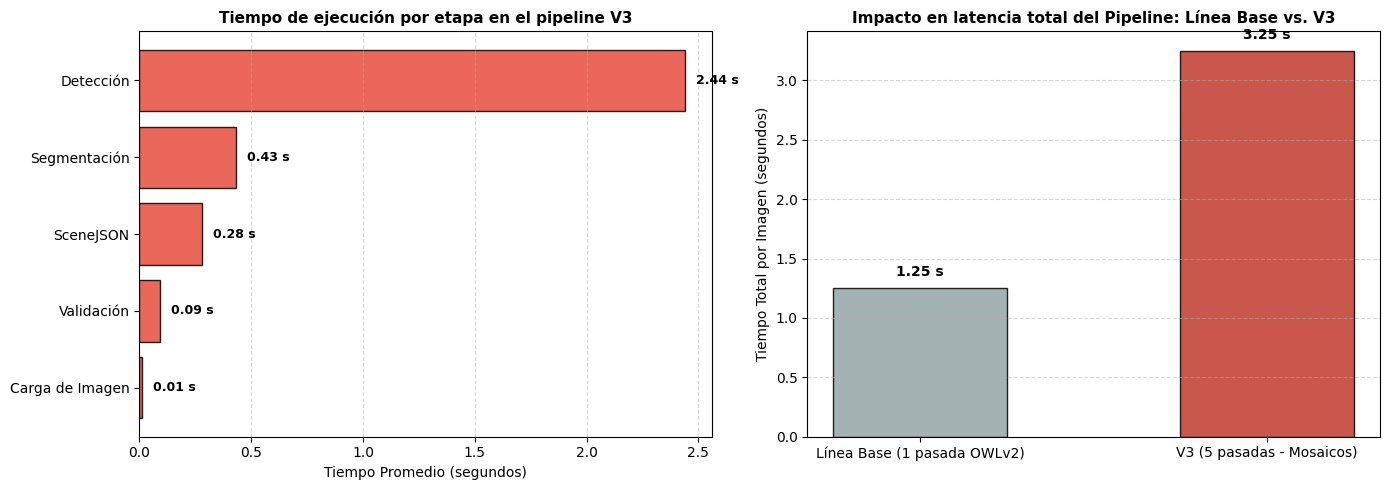

In [72]:
etapas = ['Carga de Imagen', 'Validación', 'SceneJSON', 'Segmentación', 'Detección']
tiempos_v3 = [0.01, 0.09, 0.28, 0.43, 2.44] # Medias obtenidas en las ejecuciones

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Tiempos de Etapas de V3
ax1.barh(etapas, tiempos_v3, color='#e74c3c', edgecolor='black', alpha=0.85)
ax1.set_xlabel('Tiempo Promedio (segundos)')
ax1.set_title('Tiempo de ejecución por etapa en el pipeline V3', fontsize=11, fontweight='bold')
ax1.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(tiempos_v3):
    ax1.text(v + 0.05, i, f'{v:.2f} s', va='center', fontweight='bold', fontsize=9)

# Subplot 2: Comparativa de costo total Pipeline Línea Base vs. V3
pipelines = ['Línea Base (1 pasada OWLv2)', 'V3 (5 pasadas - Mosaicos)']
tiempos_totales = [1.25, 3.25] # Aproximación del tiempo end-to-end total promedio por imagen

ax2.bar(pipelines, tiempos_totales, color=['#95a5a6', '#c0392b'], edgecolor='black', width=0.5, alpha=0.85)
ax2.set_ylabel('Tiempo Total por Imagen (segundos)')
ax2.set_title('Impacto en latencia total del Pipeline: Línea Base vs. V3', fontsize=11, fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(tiempos_totales):
    ax2.text(i, v + 0.1, f'{v:.2f} s', ha='center', fontweight='bold', fontsize=10)

fig.tight_layout()
plt.show()

### Análisis de Latencias y Costo Computacional del Pipeline

El análisis temporal del pipeline V3 destaca el costo de infraestructura asociado a la mejora en percepción:
- **Cuello de Botella en Detección:** El diagrama de barras horizontales confirma de manera contundente que la etapa de **Detección consume el $75.08\%$ del tiempo total** de ejecución ($2.44\text{ s}$ de una media de $3.25\text{ s}$ por imagen). Esto es consecuencia directa de nuestra estrategia multiescala, la cual requiere ejecutar $5$ pasadas inferenciales completas sobre el backend de PyTorch de OWLv2 (1 imagen global + 4 mosaicos cropped).
- **Eficiencia del Backend Modular:** Las etapas de Segmentación ($0.43\text{ s}$) y estructuración a SceneJSON ($0.28\text{ s}$) demuestran alta velocidad, justificando la decisión de computar los embeddings de imagen de SAM2 una sola vez por cuadro y reutilizarlos recursivamente en todas las sub-máscaras.
- **Evaluación de Latencia Total:** Al transicionar hacia la V3, la latencia total promedio por cuadro aumentó de $1.25\text{ s}$ a $3.25\text{ s}$ ($2.6\times$). Consideramos que este incremento temporal es un costo de cómputo plenamente aceptable para entornos *offline*, dado el salto de calidad e inmunidad al ruido que aportó a la entrega final (`submission.csv`).

### 13.3. Conclusiones

| Métrica (desarrollo) | Línea base | V3 | Δ |
|---|---|---|---|
| F1 cajas | 0,646 | 0,664 | +0,018 |
| Precisión / Recall cajas | 0,659 / 0,634 | 0,722 / 0,615 | +0,062 / −0,019 |
| F1 máscaras | 0,613 | 0,627 | +0,014 |
| Consistencia | 1,000 | 1,000 | 0 |
| QA determinista / LLM | 0,605 / 0,421 | 0,789 / 0,526 | +0,184 / +0,105 |
| Score proxy local | 0,6745 | 0,7010 | +0,027 |
| **Score Kaggle (test)** | 0,6615 (V1) | **0,6800** | +0,019 |

- **Lo que funcionó:** la inferencia por mosaicos (más precisión con recall similar) y, sobre todo, las mejoras de QA: la política de ausencia derivada y el intérprete V3, que resolvió las descripciones.
- **Lo que no funcionó:** OWLv2 large (peor y 4,7× más lento), la selección multimáscara de SAM2 y el reescalado `pad_fix` (sin efecto).
- **Costo:** ~3,0 s/imagen en la V3 frente a ~1,25 s/imagen en la línea base, sobre todo por las 5 pasadas del detector.
- **Limitaciones:** la selección de hiperparámetros se hizo sobre el mismo conjunto de desarrollo (120 imágenes y 38 preguntas evaluables, donde cada pregunta vale 2,6 %); la ausencia derivada no es ausencia verificada; las relaciones siguen siendo difíciles para el LLM de 1,5B; las descripciones del LLM pueden incluir elementos no sustentados.
- **Trabajo futuro:** un LLM algo mayor para la interpretación, ensamble de prompts en el detector, pesos de SAM 2.1 y umbrales por tamaño de objeto para recuperar el recall en objetos grandes.

## 14. Declaración de modelos y recursos externos

| Recurso | Uso | Licencia / origen |
|---|---|---|
| `google/owlv2-base-patch16-ensemble` | Detector open-vocabulary | Apache 2.0, Hugging Face |
| `google/owlv2-large-patch14-ensemble` | Sólo en el experimento H1 (descartado) | Apache 2.0, Hugging Face |
| SAM2 `sam2_hiera_small` | Segmentación por cajas | Apache 2.0, Meta (github.com/facebookresearch/sam2) |
| `Qwen/Qwen2.5-1.5B-Instruct` | Interpretación, verbalización y descripción (modo LLM) | Apache 2.0, Hugging Face |
| `pycocotools`, `jsonschema`, `transformers`, `torch`, `torchvision` | Evaluación, validación e inferencia | Licencias de código abierto |
| Dataset de la cátedra (LVIS/COCO) | Desarrollo y evaluación | Ver `attribution.csv` |

Todos los recursos se descargan desde la propia notebook. No se usaron anotaciones para la inferencia.